# 1-board: compensation

Find what the board's own chain adds to a current reading at low current, and how best to take each term out, so a speed estimated from the back-EMF at low speed does not carry the board. The largest term is the current zero. The shunt amplifier sits at one zero with the bridge asleep and at another with it awake, and the step between them grows with the rail. The method this stage specifies for it is a dynamic two-zero tracker, which measures the zero on the board in service, at the live rail and the live temperature, where the reading it serves is taken. It is graded here against the stage 1 captures, two motors' stage 2 captures, and one recording on a motor that carries the trough sample the tracker feeds on. A per-rail table of the step is scored beside it as the bound a static method could reach; it is not a deliverable, since reading it needs the zero at three rails, three supplies on every bench. The firmware takes its zero method and its constants from this result.

## Purpose

A servo estimates its speed from the back-EMF, the terminal volts less the copper's drop $R\,i$, over $K_e$. At low speed the EMF is a few tens of millivolts and the current a few tens of milliamps, so an error in the current's zero goes straight into the speed: one count of zero error is $R \cdot 0.88\,\mathrm{mA} / K_e$, about 0.53 rev/s on an MG90 motor, and the budget a speed estimate works to at low speed is 0.5 rev/s, under a count. The board's zero is not one number. Stage 1 found the current channel's rest zero at 1206 counts and an in-drive offset of about 5 counts over it, fitted as one constant from 3.7 to 8 V. The stage 2 captures hold the two zeros side by side on every cycle, the torque-off rest before each chain and the open bridge after each coast cut, at three rails, so the step and its shape against the rail can be read there with hundreds of spins behind each number, and one later recording on the same motor carries the trough sample under low-duty drives at the same three rails, so the level the tracker feeds on is read directly.

The question has two parts, and every stage from here on answers both for its own terms. What does the board add, term by term, in counts and in rev/s at low speed. And how best does the data say to compensate each: a table, a tracker, a gate, or nothing. The terms are the current zero and its rail shape, the trough's own share over the open bridge, the frame's two shunt samples, the window floors, the edge lags, the window scale, the ADC's own map, the zero and the scale at a 3.3 V rail, the two drifts with board temperature, and the current scale itself. The current zero gets the full treatment, since it is the one term a tracker can follow live and the one the stage 2 data can grade.

## Procedure

This notebook captures nothing of its own. It reads the stage 1 results and datasets of this board (rest-noise, current-scale, terminal-chain, sample-timing, opamp-temperature and bridge-states), and, as earlier-stage data, the stage 2 bemf-coast datasets of two motors on the same board, mg90-c (capture-1, capture-2, low-1, low-meter-3 and trough-4) and mg90-b (capture-1). Each motor is read with its own constants: mg90-b's $K_e$ and $R$ from its stage 2 result files, mg90-c's re-derived below from its own stall pass and its own coasts, since mg90-c has no stage 2 result files of its own yet.

Five of the motor datasets stream the R/L field set, `current_raw` alone as the crest sample, with no trough sample and no bias column. trough-4 streams `current_trough` beside `current_raw` in every row, under holds at 10 to 60 % duty at the three rails, so the trough a low-duty drive feeds is read on the motor there, and the tracker is replayed on it with its real feed. On the five datasets the trough is synthesized at the level trough-4 measured. The stage 1 bursts and sweeps on the dummy load carry the trough too and stand beside the motor's.

## Data

Under `telemetry/mg90-c__dev-v006-2A-D/bemf-coast/` and `telemetry/mg90-b__dev-v006-2A-D/bemf-coast/`:

- `<dataset>/cycles.csv`, one row per cycle with its rail, its duty, its repeat and its host times, and for the low datasets the kick duty.
- `<dataset>/cycles/<k>/sweep.csv`, one row per control tick at 20 kHz: segment 0 is the 500 ms torque-off baseline, then per direction a spin and a coast with the bridge open. capture-1 and capture-2 hold 1.5 s at 15 to 60 % and coast 0.8 s, three repeats at 3.7, 5 and 7.4 V. low-1 kicks for 300 ms at 30 % then holds 2 s at 6 to 12 % (5 V) and kicks at 20 % then holds at 4 to 8 % (7.4 V), coast 0.6 s. low-meter-3 kicks for 300 ms then holds 2.5 s at 8 to 20 %, at 7.4, 5 and then 3.7 V, coast 0.3 s. trough-4 kicks for 300 ms at 20 % (7.4 V), 30 % (5 V) or 40 % (3.7 V), then holds 2 s at 20, 15, 10 and 40 % (7.4 V), 20, 15, 12 and 40 % (5 V) and 30, 20, 16 and 60 % (3.7 V), coast 0.6 s, three repeats of each, 36 cycles in the order 7.4, 5 and 3.7 V, 0 rows dropped and 0 tick gaps; its rows carry the rail, both shunt samples, the taps and the window, and no NTC. mg90-b's capture-1 is the same ladder as mg90-c's at 5 and 7.4 V.
- `<dataset>/cycles/<k>/segments.csv`, the host time of every segment's first and last row, which the replay keeps the real gaps from. mg90-b's capture-1 predates it and has none.
- `<dataset>/cycles/<k>/meta.json`, the schedule and the capture settings.

Under `telemetry/dev-v006-2A-D/`, the stage 1 datasets this notebook re-reads: `rest-noise/capture-1/rest-*` (torque-off streams at three rails), `current-scale/capture-1/bare/laps` (the rests before the 100 % laps, from 3.3 V up), `sample-timing/capture-1/{bursts, bursts-1s, ladder-slow, ladder-slow-1s}` (free-running bursts through slow-decay windows at 7.4 and 3.7 V with the ladders' rests), and `bridge-states/capture-1/<wiring>/{bursts-slow, sweep-slow}` at 5 V on the four dummy wirings, whose sweeps carry the trough sample in the row.

### The results carried in

From stage 1, current-scale's counts per amp, in-drive offset, rest zero and its 3.3 V numbers, sample-timing's edge lags, floors and window scale, bridge-states' window scale, terminal-chain's terminal scale, rail range and ADC map, opamp-temperature's two drifts, and rest-noise's current floor. From stage 2, for mg90-b only, bemf-coast's $K_e$ and rest-resistance's locked $R$.

In [1]:
import sys
import warnings

import matplotlib.pyplot as plt
import numba as nb
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from oscnb import boards, bursts as bu, motors, results, tel

warnings.filterwarnings("ignore")
BLUE, ORANGE, GREEN, INK, MUTED, RED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#898781", "#b8322a"   # the house colors
RAIL_COLOR = {3.7: ORANGE, 5.0: GREEN, 7.4: BLUE}              # one color per rail through every figure
BOARD = boards.BOARDS[boards.DEFAULT]
FS, ARR = BOARD.tick_hz, BOARD.pwm_arr                          # the 20 kHz control tick; 1200 ticks from the trough to the crest
TELE = results.ROOT / "telemetry"
T1 = TELE / BOARD.key                                           # this board's stage 1 datasets
CS = results.read("1-board", "current-scale", pair=BOARD.key)   # counts per amp, the in-drive offset, the rests
ST = results.read("1-board", "sample-timing", pair=BOARD.key)   # the edge lags, the floors, the window scale
BSR = results.read("1-board", "bridge-states", pair=BOARD.key)  # the window scale on the resistor
TC = results.read("1-board", "terminal-chain", pair=BOARD.key)  # the terminal scale, the rail range, the ADC map
OPA = results.read("1-board", "opamp-temperature", pair=BOARD.key)   # the zero and gain drifts with temperature
RN = results.read("1-board", "rest-noise", pair=BOARD.key)      # the current channel's floor at rest
CPA = CS["counts_per_a"]["value"]                               # counts per amp against the DMM
DRIVE_OFF = CS["drive_offset_counts"]["value"]                  # the in-drive offset current-scale fitted as one constant
MA_PER_COUNT = 1e3 / CPA
NOISE_REST = RN["current_noise"]["value"]                       # counts rms of the current channel at rest
LEVELS = (3.7, 5.0, 7.4)                                        # the three rails the motor datasets ran at
# the datasets the modeled replay walks, in capture order within each motor: the crest sample alone in their rows
SIM = [("mg90-c", "capture-1"), ("mg90-c", "capture-2"), ("mg90-c", "low-1"), ("mg90-c", "low-meter-3"), ("mg90-b", "capture-1")]
REAL = ("mg90-c", "trough-4")                                   # the recording with the trough sample in every row: the tracker's real feed


def folder_of(motor, name):
    return TELE / f"{motor}__{BOARD.key}" / "bemf-coast" / name


print(f"{BOARD.key}: {CPA:.1f} counts/A, {MA_PER_COUNT:.3f} mA per count, in-drive offset {DRIVE_OFF:+.2f} counts, "
      f"rest noise {NOISE_REST:.2f} counts rms")
for m, n in SIM + [REAL]:
    c = pd.read_csv(folder_of(m, n) / "cycles.csv")
    print(f"  {str(results.rel(folder_of(m, n))):55s} {len(c):3d} cycles at {', '.join(f'{v:g}' for v in sorted(c['volts_set'].unique()))} V"
          + ("  (both shunt samples in the row)" if (m, n) == REAL else ""))

dev-v006-2A-D: 1135.0 counts/A, 0.881 mA per count, in-drive offset +5.26 counts, rest noise 1.08 counts rms
  telemetry/mg90-c__dev-v006-2A-D/bemf-coast/capture-1     45 cycles at 3.7, 5, 7.4 V
  telemetry/mg90-c__dev-v006-2A-D/bemf-coast/capture-2     45 cycles at 3.7, 5, 7.4 V
  telemetry/mg90-c__dev-v006-2A-D/bemf-coast/low-1         21 cycles at 5, 7.4 V
  telemetry/mg90-c__dev-v006-2A-D/bemf-coast/low-meter-3   33 cycles at 3.7, 5, 7.4 V
  telemetry/mg90-b__dev-v006-2A-D/bemf-coast/capture-1     30 cycles at 5, 7.4 V
  telemetry/mg90-c__dev-v006-2A-D/bemf-coast/trough-4      36 cycles at 3.7, 5, 7.4 V  (both shunt samples in the row)


In [2]:
# the method's constants, as the Method section below specifies them; nothing here is read off a board
ALPHA_SHIFT = 13                                    # the EWMA's gain, 2^-13 per tick
FRAC = 16                                           # the zeros' fixed-point state, Q16
STALE_TICKS = 65535                                 # ticks without a feed before a zero is stale and follows the other
ZERO_SETTLE_TICKS = 32                              # ticks after a bridge change before a rest, coast or brake feeds
BIAS_BRAKE_MIN_TICKS = 960                          # the brake half of a slow-decay period that lets its trough feed, the gate as first specified
TROUGH_FEED_MAX_TICKS = ARR - BIAS_BRAKE_MIN_TICKS  # 240: a drive window this wide or narrower feeds the awake zero, 20 % duty
TAU_S = (1 << ALPHA_SHIFT) / FS                     # the EWMA's time constant, seconds
BRAKE_DUTY_Q15 = 82                                 # the capture tool's post-rung brake: a token slow-decay drive
BRAKE_TICKS = int(BOARD.drive_ticks(BRAKE_DUTY_Q15))
BRAKE_POLL_S, BRAKE_POLLS = 0.020, 50               # one 20 ms poll if the pot reads still, up to 50 if it never does
GATES_PCT = (20, 30, 40, 60)                        # the feeding gate's candidates, scored on the motor's own trough below
GATE_REC_PCT = 30                                   # the gate the result recommends, from that scoring


def gate_ticks(pct):
    # the widest slow-decay window whose trough feeds the awake zero under a gate at `pct` duty
    return int(round(pct / 100 * ARR))


def brake_min_ticks(pct):
    # the same gate as the least width of the period's brake half
    return ARR - gate_ticks(pct)


print(f"alpha 2^-{ALPHA_SHIFT} per tick, tau {TAU_S:.3f} s; stale after {STALE_TICKS} ticks ({STALE_TICKS / FS:.1f} s); settle {ZERO_SETTLE_TICKS} ticks; "
      f"a slow-decay drive feeds at <= {TROUGH_FEED_MAX_TICKS} ticks ({TROUGH_FEED_MAX_TICKS / ARR * 100:.0f} % duty) as first specified; the brake {BRAKE_TICKS} ticks for 20 ms or 1 s")
print("gate candidates: " + ", ".join(f"{p} % = {gate_ticks(p)} ticks (brake half >= {brake_min_ticks(p)})" for p in GATES_PCT))

alpha 2^-13 per tick, tau 0.410 s; stale after 65535 ticks (3.3 s); settle 32 ticks; a slow-decay drive feeds at <= 240 ticks (20 % duty) as first specified; the brake 3 ticks for 20 ms or 1 s
gate candidates: 20 % = 240 ticks (brake half >= 960), 30 % = 360 ticks (brake half >= 840), 40 % = 480 ticks (brake half >= 720), 60 % = 720 ticks (brake half >= 480)


### Each motor's own constants

The speed a count of zero error is worth goes through the motor's own $R$ and $K_e$. mg90-b's come from its stage 2 result files. mg90-c's are read here from its own captures, the way those notebooks read them: $R$ from the stall pass, a line through $V/I$ from 60 ms into each 100 % lap read at the drive's start, the graded rails only, the mean per hole and the median over the twelve holes, in the positive direction. $K_e$ comes from capture-1's coasts, the window's bridged EMF over the speed its own ripple counts, the mean over the turned spins. The ripple-tach pieces are motor-model's and the stage 2 modules', imported for their functions alone, and no mg90-b constant enters mg90-c's numbers.

In [3]:
# mg90-b's constants from its stage 2 result files
BEMF_B = results.read("2-motor", "bemf-coast", pair="mg90-b")
RR_B = results.read("2-motor", "rest-resistance", pair="mg90-b")
# the stage 2 modules, for the ripple tach's pieces (spin/coast pairing, the open-row bridging, the line and window reads)
sys.path.insert(0, str(results.ROOT / "stages" / "2-motor" / "motor-model"))
import motor_model as mm   # noqa: E402
import brush_drop as bd    # noqa: E402

K_CPV, C_OFF = TC["terminal_counts_per_v"]["value"], TC["terminal_offset_counts"]["value"]   # terminal counts per volt and offset
GRADED_V = TC["rail_range_v"]["lo"] + 0.015        # the lowest graded rail; the 3.3 V laps stay out
N_R_C = motors.MOTORS["mg90-c"].ripple_per_rev     # ripple events per revolution, slots x brushes


def stall_r(stall):
    # rest-resistance's lap read: per 100 % lap into the locked rotor, a line through V/I from 60 ms in, its value at the start
    rows = []
    for _, L in pd.read_csv(stall / "laps.csv").iterrows():
        df, meta = tel.load(stall / L["folder"], BOARD)
        zero = float(tel.baseline(df)["current_raw"].median())              # the lap's own torque-off zero
        for seg, g in df[df["seg"] > 0].groupby("seg"):
            d = int(g["dir"].iloc[0])
            on = int(np.flatnonzero(g["duty_counts"].to_numpy() != 0)[0])  # the drive's first row
            g = g.iloc[on:]
            i = (g["current_raw"].to_numpy(float) - zero - DRIVE_OFF) / CPA                 # amps through the stage 1 chain
            u = ((g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * d - C_OFF) / K_CPV      # terminal volts, bias free
            t = np.arange(len(g)) / FS
            late = t >= 0.060
            rows.append(dict(hole=int(L["hole"]), level=float(L["volts_set"]), dir=d, r_start=np.polyfit(t[late], (u / i)[late], 1)[1]))
    return pd.DataFrame(rows)


def coast_ke_rows(folder):
    # bemf-coast's coast route per spin: the bridged EMF over the whole-cycle window after the cut, and the speed its ripple counts
    df, meta = tel.load(folder, BOARD)
    rest = tel.baseline(df)
    zero_e = float((rest["vmotor_a"] - rest["vmotor_b"]).median())        # the tap difference's rest zero
    out = []
    for d, sp, co in mm.spin_coast_pairs(df):
        try:
            z = mm.cut_row(co)                                              # the row the drive stops
            e = (((co["vmotor_a"] - co["vmotor_b"]) * d).to_numpy(float)[z:] - zero_e) / K_CPV   # the coast's EMF in volts
            if e[2:20].mean() < mm.TURN_V:                                  # the motor did not turn
                continue
            eb = mm.bridge_rows(e, mm.open_rows(e))                         # the rows the brush path stood open, bridged
            f0 = mm.line_freq(eb[mm.COAST_FROM:mm.COAST_FROM + 200])        # the ripple line's seed
            main = bd.line_read(eb, mm.COAST_FROM, mm.TARGET_MS, f0)        # the window's EMF and its ripple frequency
            out.append(dict(dir=d, e_win=main["e_win"], coast_rev_s=main["f"] / N_R_C))
        except (ValueError, IndexError, np.linalg.LinAlgError, TypeError):  # a coast whose ripple seed finds no line
            continue
    return out


SR = stall_r(TELE / f"mg90-c__{BOARD.key}" / "rest-resistance" / "capture-1" / "stall")
HOLE = SR[(SR["level"] >= GRADED_V) & (SR["dir"] == 1)].groupby("hole")["r_start"].mean()
cyc1 = pd.read_csv(folder_of("mg90-c", "capture-1") / "cycles.csv")
KE_ROWS = pd.DataFrame([r for _, C in cyc1.iterrows() for r in coast_ke_rows(folder_of("mg90-c", "capture-1") / C["folder"])])
ke_spin = (KE_ROWS["e_win"] / (2 * np.pi * KE_ROWS["coast_rev_s"])).dropna()
ke_spin = ke_spin[(ke_spin > 0.5e-3) & (ke_spin < 2e-3)]                  # V s/rad; the band a turned coast lands in
MOTORS = {
    "mg90-c": dict(ke_mv_per_rev_s=float(ke_spin.mean()) * 2 * np.pi * 1e3, ke_sd_pct=float(ke_spin.std(ddof=1) / ke_spin.mean() * 100),
                   ke_n=int(len(ke_spin)), r_ohm=float(HOLE.median()), r_lo=float(HOLE.min()), r_hi=float(HOLE.max())),
    "mg90-b": dict(ke_mv_per_rev_s=BEMF_B["ke_mv_per_rev_s"]["value"], r_ohm=RR_B["r_term_median_ohm"]["value"],
                   r_lo=RR_B["r_term_median_ohm"]["lo"], r_hi=RR_B["r_term_median_ohm"]["hi"]),
}


def rev_s_per_count(motor):
    # the speed error one count of zero error makes at low speed: a count of current through the motor's own R and Ke
    m = MOTORS[motor]
    return MA_PER_COUNT * m["r_ohm"] / m["ke_mv_per_rev_s"]


def rev_s_per_ma(motor):
    m = MOTORS[motor]
    return m["r_ohm"] / m["ke_mv_per_rev_s"]


print(f"mg90-c: R {MOTORS['mg90-c']['r_ohm']:.3f} ohm ({MOTORS['mg90-c']['r_lo']:.3f} to {MOTORS['mg90-c']['r_hi']:.3f} over {len(HOLE)} holes), "
      f"Ke {MOTORS['mg90-c']['ke_mv_per_rev_s']:.3f} mV per rev/s (sd {MOTORS['mg90-c']['ke_sd_pct']:.2f} % over {MOTORS['mg90-c']['ke_n']} coasts)")
print(f"mg90-b: R {MOTORS['mg90-b']['r_ohm']:.3f} ohm ({MOTORS['mg90-b']['r_lo']:.3f} to {MOTORS['mg90-b']['r_hi']:.3f}), "
      f"Ke {MOTORS['mg90-b']['ke_mv_per_rev_s']:.3f} mV per rev/s, from its result files")
for m in MOTORS:
    print(f"  {m}: {rev_s_per_count(m):.3f} rev/s per count, {rev_s_per_ma(m):.3f} rev/s per mA; 0.5 rev/s = {0.5 / rev_s_per_count(m):.2f} counts = {0.5 / rev_s_per_ma(m):.2f} mA")

mg90-c: R 4.402 ohm (4.283 to 4.439 over 12 holes), Ke 7.321 mV per rev/s (sd 0.51 % over 88 coasts)
mg90-b: R 4.455 ohm (4.384 to 4.531), Ke 7.341 mV per rev/s, from its result files
  mg90-c: 0.530 rev/s per count, 0.601 rev/s per mA; 0.5 rev/s = 0.94 counts = 0.83 mA
  mg90-b: 0.535 rev/s per count, 0.607 rev/s per mA; 0.5 rev/s = 0.94 counts = 0.82 mA


## Method

### The method specified: a dynamic two-zero tracker

The method keeps two zeros of the current channel, one for the bridge asleep (the driver disabled) and one for it awake (the driver on with no winding current across the shunt), each an exponentially weighted moving average of the trough shunt sample,

$$z \leftarrow z + 2^{-13}\,(x - z)$$

per 20 kHz tick, a time constant $\tau = 2^{13} / 20\,\mathrm{kHz} = 0.41$ s, the state in Q16 with the update floored, so a step closes to within an eighth of a count. A zero that has not been fed for 65535 ticks, 3.3 s, is stale and follows the other zero's moves until it is fed again. Which zero a tick feeds follows from the bridge state the previous tick's command set. The driver disabled feeds the asleep zero. A coast or a brake feeds the awake zero, after 32 ticks of settle from the change. A slow-decay drive whose brake half is at least a set share of the 1200 ticks feeds the awake zero from its trough sample with no settle wait: 960 ticks, a window of 240 ticks or 20 % duty or narrower, as first specified, and the gate is scored at 20, 30, 40 and 60 % on the motor's own trough below. A wider drive feeds nothing. At boot both zeros are seeded from the install's rest measurement, so the step between them is unknown until the awake zero is fed. The reading a drive uses is the crest sample less the awake zero.

The zero is a property of the board, not of the motor, and it moves with the rail and with the board's temperature. The tracker reads it on the board in service, at the rail and the temperature the reading it serves is taken at, and it costs nothing at identification and nothing beyond the loop it already runs in. That is the reason it is the method, and the grading below says what it leaves.

The capture tool's post-rung brake is a token slow-decay drive of 82 Q15, three ticks of window, held for one 20 ms poll when the pot reads still and up to fifty when it never does. On the pot-less motor rig which of the two happened is not recorded, so the replay runs both. Its trough is a feed.

### The five zeros the data hold

- (a) asleep: the mean of every cycle's torque-off baseline, 5000 rows. The mean and not the median, since the median of integer codes is an integer and the EWMA is a mean. Stage 1's rests at the same rails and at 3.3 V beside it.
- (b) awake by coast: the open bridge 1 to 20 ms after each coast cut, counts over the cycle's own baseline, with its settling profile at 0.1 to 1 ms, 20 ms to the end and 100 to 300 ms. On trough-4 also the late coast, 10 ms past the cut to the end, in both shunt columns, which is the reference the motor's trough is read against.
- (c) awake by brake: whether any schedule streams one.
- (d) awake by the slow-decay trough, on the motor: trough-4's trough sample under each hold, the settled rows over the cycle's own trough baseline, per rail and duty, against the same chain's late coast in its own column and in the crest column. The dummy's beside it: the between-window shunt level of stage 1's slow-decay bursts, folded on the period, the median within 100 ticks of the trough, over the burst's own pre-step zero and the ladder's baseline, from sample-timing at 7.4 and 3.7 V and bridge-states at 5 V, with the trough column of the bridge-states sweeps.
- (e) under switching on the motor: the crest sample on the dropout rows, the periods the brush path stood open, over the baseline, in spins with at least ten such rows in their last 200 ms.

Then the awake-minus-asleep step against the rail, per spin against the coast's own measured rail: a line, a slope through the origin, a quadratic, and the per-rail residual of each. Then, on trough-4, what the trough depends on, the duty, the winding current, the speed and the time within the hold, each against the per-spin scatter, and the frame's two shunt samples against each other at rest and with the bridge open.

### The replay

A tick-exact port of the tracker runs over each dataset's real timeline, built from these pieces.

- The gap between cycles and the rest after every chain as the driver disabled, fed with the baseline level plus the rest floor's noise.
- The 500 ms baseline's real rows.
- 5 ms of coast between torque on and the first drive, from `segments.csv`.
- Every drive row with its own `duty_counts`, where a feeding width gets a synthetic trough sample at the motor's measured trough level for that rail plus a count of noise, on the five datasets that did not stream the trough.
- The coast rows' real samples after the 32-tick settle.
- The brake as a 3-tick drive for 20 ms or 1 s, then torque off.

mg90-b's capture-1 has no segment times, so its gaps are synthesized at the median gap from one segment's end to the next drive in mg90-c's capture-1. The tracker is seeded at each dataset's first baseline mean, both zeros equal, which is the boot case. The truth per spin is the cycle's baseline plus the dataset's own per-rail open-bridge mean, and the spin's own coast zero is the alternative truth. The error is the awake zero less the truth at the spin's first row, its last row and over its last 200 ms, in counts and in rev/s through the motor's own constants. A spin is warm when its dataset's first chain is behind it. On trough-4 nothing is synthesized but the gaps: every streamed row feeds its own trough sample, baseline, drive and coast alike, the truth per spin is the chain's own late coast in the crest column, and the replay runs once per gate candidate.

### The scoring and the comparisons

The tracker (A) is scored as the rms and worst error over all spins, pooled and per dataset, with the count of spins past 0.5 rev/s, on the five datasets and on its real feed. Two comparisons run on the same replay. (B) the tracker plus a rail term, the line's slope times the rail now less the rail at the last feed, first as the rail of the last fed tick and then as a rail learned by an EWMA at the same gain on the same ticks: the one refinement that needs no identification step. (C) no awake tracking: the asleep zero plus a per-rail table read once from mg90-c's capture-1, linear between its three rails, applied to every dataset and both motors by the live rail, and the same with the line in place of the table. C is the bound a static method reaches on this board and the grading truth's own reproducibility across days and motors. It is not a method a user can run, since reading it needs the zero at three rails.

## The zeros per rail

One record per cycle: its baseline, every streamed segment with its drive ticks and shunt samples, per driven segment the open-bridge zero after its coast and the dropout rows' zero under drive, and, on trough-4, both shunt samples' baselines, the settled trough under each drive and the late coast in both columns. The replay later feeds from the same records.

In [4]:
OPEN_FROM, OPEN_TO = 20, 400          # rows past the cut: 1 to 20 ms, the open-bridge window
LATE_FROM, LATE_TO = 2000, 6000       # 100 to 300 ms past the cut, the settled check
COAST_SKIP = 200                      # 10 ms past the cut to the coast's end: the late coast, the reference on the recording with both samples
EMF_FROM, EMF_TO = 40, 200            # 2 to 10 ms past the cut: the coast EMF that gives the speed at the cut
N200 = int(0.2 * FS)                  # the last 200 ms of a spin


def quarters(x, q=4):
    # the mean of each quarter of a settled window
    return [float(np.mean(p)) for p in np.array_split(np.asarray(x, float), q)]


def reduce_cycle(folder, dataset_level):
    # one compact record of a cycle: the baseline, the segments' per-row ticks and samples, the zeros per driven segment, and, where
    # the row carries the trough sample, both samples' baselines, the settled trough under every drive and both columns of the late coast
    df, meta = tel.load(folder, BOARD)
    segf = folder / "segments.csv"
    segs = pd.read_csv(segf).set_index("seg") if segf.exists() else None
    rest = tel.baseline(df)
    zero_i = float(rest["current_raw"].mean())                 # the baseline MEAN: the median of integer codes is an integer
    rec = dict(folder=str(results.rel(folder)), level=float(dataset_level), zero_i=zero_i, zero_sd=float(rest["current_raw"].std(ddof=1)),
               rail_rest=float(BOARD.rail_v(rest["vbus_raw"].mean())), ntc_raw=float(rest["ntc_raw"].mean()), schedule=meta["schedule"],
               has_trough="current_trough" in df.columns, segs=[])
    if rec["has_trough"]:
        rec["z_trough"] = float(rest["current_trough"].mean())  # the trough sample's own baseline, the frame's other shunt sample
        rec["z_trough_sd"] = float(rest["current_trough"].std(ddof=1))
    for seg, g in df.groupby("seg"):
        s = dict(seg=int(seg), dir=int(g["dir"].iloc[0]), cmd=int(g["cmd_duty_q15"].iloc[0]), n=len(g),
                 ticks=g["duty_counts"].abs().to_numpy(np.int16), raw=g["current_raw"].to_numpy(np.uint16),
                 vbus=g["vbus_raw"].to_numpy(np.float32),
                 t_start=float(segs.loc[seg, "t_start"]) if segs is not None else np.nan,
                 t_end=float(segs.loc[seg, "t_end"]) if segs is not None else np.nan)
        if rec["has_trough"]:
            s["trough"] = g["current_trough"].to_numpy(np.uint16)
            s["va"], s["vb"] = g["vmotor_a"].to_numpy(np.int16), g["vmotor_b"].to_numpy(np.int16)   # the taps, for the coast EMF
            if s["cmd"] != 0:
                st = tel.settled(g)                                                      # after the duty reached its held value, 40 rows in
                tr = st["current_trough"].to_numpy(float) - rec["z_trough"]              # the trough over its own baseline
                cr = st["current_raw"].to_numpy(float) - zero_i                          # the crest over its own
                s.update(ticks_settled=int(st["duty_counts"].abs().median()), n_settled=len(st),
                         trough_level=float(tr.mean()), trough_sd_rows=float(tr.std(ddof=1)), crest_level=float(cr.mean()),
                         trough_200=float(tr[-N200:].mean()), trough_q=quarters(tr), crest_q=quarters(cr),
                         trough_first100ms=float(tr[:int(0.1 * FS)].mean()), rail_settled=float(BOARD.rail_v(st["vbus_raw"].mean())))
        rec["segs"].append(s)
    S = rec["segs"]
    for i, s in enumerate(S):
        if s["cmd"] == 0:
            continue
        j = next((k for k in range(i + 1, len(S)) if S[k]["cmd"] == 0), None)   # the coast that ends this chain
        s["ticks_held"] = float(np.median(s["ticks"][len(s["ticks"]) // 2:]))    # the held window, ticks
        x = s["raw"][-N200:].astype(float) - zero_i                              # the last 200 ms over the baseline
        s["rail_spin"] = float(BOARD.rail_v(s["vbus"][-N200:].mean()))
        s["crest_200"] = float(x.mean())
        ic = x - DRIVE_OFF
        q = ic / ic.mean() if ic.mean() > 0 else np.full_like(ic, np.nan)        # each row against the window's mean
        drop, deep = x[q < tel.DROPOUT_FRAC], x[q < 0.10]                        # the dropout rows, and the deepest of them
        s["dropout_rows"], s["deep_rows"] = int(len(drop)), int(len(deep))
        s["dropout_zero"] = float(np.median(drop)) if len(drop) else np.nan
        s["deep_zero"] = float(np.median(deep)) if len(deep) else np.nan
        if j is None:
            continue
        co = S[j]
        z = int(np.flatnonzero(co["ticks"] == 0)[0]) if (co["ticks"] == 0).any() else 0   # the cut row
        r = co["raw"].astype(float) - zero_i
        s["coast_seg"], s["cut_row"] = j, z
        s["open_zero"] = float(r[z + OPEN_FROM:z + OPEN_TO].mean())             # (b): 1 to 20 ms after the cut
        s["open_zero_sd_rows"] = float(r[z + OPEN_FROM:z + OPEN_TO].std(ddof=1))
        s["open_zero_early"] = float(r[z + 2:z + OPEN_FROM].mean())             # 0.1 to 1 ms
        s["open_zero_late"] = float(r[z + LATE_FROM:z + LATE_TO].mean()) if len(r) > z + LATE_TO else np.nan
        s["open_zero_tail"] = float(r[z + OPEN_TO:].mean())                     # 20 ms to the end
        s["rail_coast"] = float(BOARD.rail_v(co["vbus"][z + OPEN_FROM:].mean()))
        if rec["has_trough"]:
            tr = co["trough"].astype(float) - rec["z_trough"]
            s["coast_crest_late"] = float(r[z + COAST_SKIP:].mean())            # the late coast in the crest column: this recording's (b)
            s["coast_trough_late"] = float(tr[z + COAST_SKIP:].mean())          # the same open bridge seen by the trough sample
            s["coast_trough_open"] = float(tr[z + OPEN_FROM:z + OPEN_TO].mean())
            emf = BOARD.diff_v(co["va"][z + EMF_FROM:z + EMF_TO], co["vb"][z + EMF_FROM:z + EMF_TO])
            s["emf_cut_v"] = float(abs(np.median(emf)))                         # the coast EMF just past the cut: the speed the drive left
            co["coast_trough_late"], co["coast_crest_late"] = s["coast_trough_late"], s["coast_crest_late"]
            nbin = int(0.1 * FS)                                                 # the coast in 100 ms bins: both samples against the dying EMF
            s["coast_bins"] = [dict(t_ms=(b0 - z) / FS * 1e3, trough=float(tr[b0:b0 + nbin].mean()) - s["coast_trough_late"],
                                    crest=float(r[b0:b0 + nbin].mean()) - s["coast_crest_late"],
                                    emf_v=float(abs(np.median(BOARD.diff_v(co["va"][b0:b0 + nbin], co["vb"][b0:b0 + nbin])))))
                               for b0 in range(z + 2, len(tr) - nbin + 1, nbin)]
    return rec


CACHE = {}                            # the reductions, built once per process


def reduce_dataset(motor, name):
    if (motor, name) not in CACHE:
        cyc = pd.read_csv(folder_of(motor, name) / "cycles.csv").sort_values("t_start").reset_index(drop=True)
        recs = []
        for _, C in cyc.iterrows():
            r = reduce_cycle(folder_of(motor, name) / C["folder"], C["volts_set"])
            r.update(k=int(C["k"]), duty=int(C["duty_pct"]), repeat=int(C["repeat"]), t_start=float(C["t_start"]), t_end=float(C["t_end"]),
                     kick=int(C["kick_pct"]) if "kick_pct" in C and pd.notna(C["kick_pct"]) else 0)
            recs.append(r)
        CACHE[(motor, name)] = recs
    return CACHE[(motor, name)]


def spin_table(motor, name):
    # one row per driven segment with its zeros
    rows = []
    for r in reduce_dataset(motor, name):
        for i, s in enumerate(r["segs"]):
            if s["cmd"] == 0:
                continue
            prev = r["segs"][i - 1]
            rows.append(dict(motor=motor, name=name, k=r["k"], level=r["level"], duty=r["duty"], seg=s["seg"], dir=s["dir"],
                             is_hold=prev["cmd"] != 0 and prev["dir"] == s["dir"], cmd=s["cmd"], ticks=s["ticks_held"], zero_i=r["zero_i"],
                             zero_sd=r["zero_sd"], rail_rest=r["rail_rest"], rail_spin=s["rail_spin"], crest_200=s["crest_200"],
                             dropout_rows=s["dropout_rows"], dropout_zero=s["dropout_zero"], deep_rows=s["deep_rows"], deep_zero=s["deep_zero"],
                             open_zero=s.get("open_zero", np.nan), open_zero_sd_rows=s.get("open_zero_sd_rows", np.nan),
                             open_zero_early=s.get("open_zero_early", np.nan), open_zero_late=s.get("open_zero_late", np.nan),
                             open_zero_tail=s.get("open_zero_tail", np.nan), rail_coast=s.get("rail_coast", np.nan),
                             t_start=s["t_start"], t_end=s["t_end"]))
    return pd.DataFrame(rows)


def trough_table(motor, name, ke_mv_per_rev_s):
    # one row per driven segment of a recording with both samples: the settled trough and crest over their own baselines, the quarters,
    # the chain's late coast in both columns, and the speed at the cut from the coast EMF through the motor's own Ke
    rows = []
    for r in reduce_dataset(motor, name):
        for i, s in enumerate(r["segs"]):
            if s["cmd"] == 0:
                continue
            prev = r["segs"][i - 1]
            rows.append(dict(k=r["k"], level=r["level"], kind="hold" if prev["cmd"] != 0 and prev["dir"] == s["dir"] else "kick",
                             duty=s["ticks_settled"] * 100 / ARR, ticks=s["ticks_settled"], dir=s["dir"], seg=s["seg"], n_settled=s["n_settled"],
                             z_crest=r["zero_i"], z_trough=r["z_trough"], z_diff=r["z_trough"] - r["zero_i"],
                             trough=s["trough_level"], trough_sd_rows=s["trough_sd_rows"], crest=s["crest_level"], trough_200=s["trough_200"],
                             trough_first100ms=s["trough_first100ms"], **{f"trough_q{q + 1}": v for q, v in enumerate(s["trough_q"])},
                             **{f"crest_q{q + 1}": v for q, v in enumerate(s["crest_q"])},
                             coast_trough=s["coast_trough_late"], coast_crest=s["coast_crest_late"], coast_crest_open=s["open_zero"],
                             coast_trough_open=s["coast_trough_open"], emf_cut_v=s["emf_cut_v"], speed_cut=s["emf_cut_v"] * 1e3 / ke_mv_per_rev_s,
                             rail_spin=s["rail_settled"], rail_coast=s["rail_coast"], t_start=s["t_start"], t_end=s["t_end"]))
    df = pd.DataFrame(rows)
    df["crest_over_zero"] = df["crest"] - df["coast_crest"]            # the winding current at the crest sample, counts over the open-bridge zero
    df["d_t"] = df["trough"] - df["coast_trough"]                      # the trough over the same chain's open bridge in its own column: the drive's share
    df["d_c"] = df["trough"] - df["coast_crest"]                       # the trough over the crest column's open bridge: the zero error a trough-fed zero leaves on the crest reading
    df["trough_over_crest_zero"] = df["trough"] + df["z_diff"]         # the trough level over the asleep zero of the crest column, the frame the other zeros are in
    return df


T = pd.concat([spin_table(m, n) for m, n in SIM], ignore_index=True)
TR = trough_table(*REAL, MOTORS["mg90-c"]["ke_mv_per_rev_s"])
print(f"{len(T)} driven segments, {T['open_zero'].notna().sum()} with a coast behind them, over {sum(len(reduce_dataset(m, n)) for m, n in SIM)} cycles")
print(f"{REAL[1]}: {len(TR)} driven segments ({(TR['kind'] == 'kick').sum()} kicks, {(TR['kind'] == 'hold').sum()} holds) over {len(reduce_dataset(*REAL))} cycles, "
      f"each with both shunt samples; settled window {TR['n_settled'].min() / FS:.2f} to {TR['n_settled'].max() / FS:.2f} s")

456 driven segments, 456 with a coast behind them, over 174 cycles
trough-4: 144 driven segments (72 kicks, 72 holds) over 36 cycles, each with both shunt samples; settled window 0.30 to 2.00 s


### (a) The asleep zero

The torque-off baseline per cycle, by dataset and rail, with stage 1's rests beside it, and the baseline's wander across a dataset's cycles against the board NTC.

In [5]:
def wmean(x):
    # mean, sd, standard error and count of the finite values
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    sd = float(x.std(ddof=1)) if len(x) > 1 else np.nan
    return float(x.mean()), sd, sd / np.sqrt(len(x)) if len(x) > 1 else np.nan, len(x)


def line_fit(v, y):
    # y = a + b v by least squares: a, b, their standard errors, the residuals
    v, y = np.asarray(v, float), np.asarray(y, float)
    A = np.c_[np.ones_like(v), v]
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    res = y - (coef[0] + coef[1] * v)
    cov = np.linalg.inv(A.T @ A) * float((res ** 2).sum() / max(len(y) - 2, 1))
    return coef[0], coef[1], float(np.sqrt(cov[0, 0])), float(np.sqrt(cov[1, 1])), res


# the stage 2 baselines per dataset and rail
rows = []
for (m, n), g in T.groupby(["motor", "name"], sort=False):
    for lv, h in g.groupby("level"):
        z = h.drop_duplicates("k")
        rows.append(dict(motor=m, name=n, level=lv, cycles=len(z), zero_mean=z["zero_i"].mean(), zero_sd_cycles=z["zero_i"].std(ddof=1),
                         within_sd=z["zero_sd"].mean(), rail_rest=z["rail_rest"].mean()))
A = pd.DataFrame(rows)
# stage 1's rests: rest-noise at three rails and the bare laps' rests from 3.3 V up
s1 = []
for p in sorted((T1 / "rest-noise" / "capture-1").glob("rest-*")):
    df, meta = tel.load(p, BOARD)
    b = tel.baseline(df)
    s1.append(dict(source="rest-noise", run=p.name, rail=float(BOARD.rail_v(b["vbus_raw"].mean())), zero=float(b["current_raw"].mean())))
for _, L in pd.read_csv(T1 / "current-scale" / "capture-1" / "bare" / "levels.csv").iterrows():
    df, meta = tel.load(T1 / "current-scale" / "capture-1" / "bare" / L["folder"], BOARD)
    b = tel.baseline(df)
    s1.append(dict(source="current-scale bare lap", run=f"{L['volts_set']} V", rail=float(BOARD.rail_v(b["vbus_raw"].mean())), zero=float(b["current_raw"].mean())))
S1 = pd.DataFrame(s1)
# the baseline's wander across a dataset's cycles against the board NTC through the registry's beta
drift = []
for m, n in SIM:
    recs = reduce_dataset(m, n)
    zi = np.array([r["zero_i"] for r in recs])
    tc = BOARD.ntc_c_beta(np.array([r["ntc_raw"] for r in recs]))
    a, b, sa, sb, res = line_fit(tc, zi)
    drift.append(dict(motor=m, name=n, cycles=len(zi), zero_range=zi.max() - zi.min(), zero_sd=zi.std(ddof=1), ntc_c_range=tc.max() - tc.min(),
                      counts_per_c=b, counts_per_c_se=sb, resid_sd=res.std(ddof=1)))
DR = pd.DataFrame(drift)
pd.set_option("display.width", 220, "display.max_columns", 40)
print("stage 2 baselines per dataset and rail (zero_mean over the cycles' baseline means, zero_sd_cycles across them, within_sd the rows)")
print(A.round(2).to_string(index=False))
print("\nstage 1 rests")
print(S1.round(2).to_string(index=False))
print(f"\nthe baseline across a dataset's cycles against the board NTC; opamp-temperature's tempco {OPA['zero_drift_counts_per_c']['value']:.3f} counts/C")
print(DR.round(2).to_string(index=False))

stage 2 baselines per dataset and rail (zero_mean over the cycles' baseline means, zero_sd_cycles across them, within_sd the rows)
 motor        name  level  cycles  zero_mean  zero_sd_cycles  within_sd  rail_rest
mg90-c   capture-1    3.7      15    1206.48            0.38       1.02       3.70
mg90-c   capture-1    5.0      15    1206.92            0.40       1.01       4.99
mg90-c   capture-1    7.4      15    1207.29            0.46       1.00       7.39
mg90-c   capture-2    3.7      15    1205.81            0.44       1.04       3.70
mg90-c   capture-2    5.0      15    1206.13            0.37       1.05       4.99
mg90-c   capture-2    7.4      15    1206.05            0.34       1.05       7.39
mg90-c       low-1    5.0      12    1206.53            0.30       1.03       5.00
mg90-c       low-1    7.4       9    1207.18            0.25       0.99       7.39
mg90-c low-meter-3    3.7       9    1205.40            0.76       1.05       3.70
mg90-c low-meter-3    5.0      12    12

### (b) to (e) The awake zeros

The open bridge after the cut with its settling profile and its reproduction on trough-4, the brake check, the slow-decay trough on the motor with the dummy's beside it, and the dropout rows on the motor.

In [6]:
# (b) the open bridge 1 to 20 ms after the cut, per dataset and rail, with the settling profile
rows = []
for (m, n), g in T.groupby(["motor", "name"], sort=False):
    for lvl, h in g.groupby("level"):
        h = h[h["open_zero"].notna()]
        mu, sd, se, k = wmean(h["open_zero"])
        rows.append(dict(motor=m, name=n, level=lvl, spins=k, open_counts=mu, sd=sd, se=se, open_ma=mu * MA_PER_COUNT,
                         early_0p1_1ms=h["open_zero_early"].mean(), late_100_300ms=h["open_zero_late"].mean(), tail_20ms_end=h["open_zero_tail"].mean(),
                         rows_sd=h["open_zero_sd_rows"].mean()))
B = pd.DataFrame(rows)
pool = []
for lvl, h in T[T["open_zero"].notna()].groupby("level"):
    for m, hh in h.groupby("motor"):
        mu, sd, se, k = wmean(hh["open_zero"])
        pool.append(dict(motor=m, level=lvl, spins=k, open_counts=mu, sd=sd, se=se, open_ma=mu * MA_PER_COUNT, sd_ma=sd * MA_PER_COUNT))
BP = pd.DataFrame(pool)
print("(b) the open bridge per dataset and rail, counts over the cycle's baseline")
print(B.round(2).to_string(index=False))
print("\npooled per rail and motor")
print(BP.round(2).to_string(index=False))

# (b) on the recording with both samples, from another day: the same 1 to 20 ms window beside the five datasets' pooled level, then the late coast
# (10 ms past the cut to the end) in the crest column and in the trough column
TB = TR[TR["kind"] == "hold"].groupby("level").agg(chains=("k", "count"), open_1_20ms=("coast_crest_open", "mean"), late_crest=("coast_crest", "mean"),
                                                 late_sd=("coast_crest", "std"), late_trough_col=("coast_trough", "mean")).reset_index()
TB["se"] = TB["late_sd"] / np.sqrt(TB["chains"])
TB["pooled_five"] = [BP[(BP["motor"] == "mg90-c") & (BP["level"] == lv)]["open_counts"].iloc[0] for lv in TB["level"]]
TB["open_minus_pooled"] = TB["open_1_20ms"] - TB["pooled_five"]
TB["early_minus_late"] = TB["open_1_20ms"] - TB["late_crest"]
print(f"\n(b) on {REAL[1]}, counts over the cycle's crest baseline: the 1 to 20 ms window against the five datasets' pooled (b), and the late coast in both columns")
print(TB.round(2).to_string(index=False))

# (c) does any schedule stream a brake segment?
import json
sched = {}
for m in ("mg90-c", "mg90-b"):
    for p in sorted((TELE / f"{m}__{BOARD.key}" / "bemf-coast").glob("*/cycles/0/meta.json")) + sorted((TELE / f"{m}__{BOARD.key}" / "bemf-coast").glob("*/*/0/meta.json")):
        sched[str(p.relative_to(results.ROOT))] = json.loads(p.read_text())["schedule"]
brake_sched = {k: v for k, v in sched.items() if any(s.startswith("brake") for s in v)}
print(f"\n(c) schedules with a streamed brake segment: {brake_sched or 'none'} ({len(sched)} schedules read; every zero-duty segment is a coast)")

(b) the open bridge per dataset and rail, counts over the cycle's baseline
 motor        name  level  spins  open_counts   sd   se  open_ma  early_0p1_1ms  late_100_300ms  tail_20ms_end  rows_sd
mg90-c   capture-1    3.7     30         2.59 0.46 0.08     2.29           2.77            2.45           2.43     1.00
mg90-c   capture-1    5.0     30         6.01 0.51 0.09     5.30           6.10            5.73           5.75     1.08
mg90-c   capture-1    7.4     30         9.66 0.69 0.13     8.51           9.62            9.64           9.63     1.32
mg90-c   capture-2    3.7     30         2.52 0.45 0.08     2.22           2.56            2.38           2.36     1.00
mg90-c   capture-2    5.0     30         5.89 0.60 0.11     5.19           6.01            5.78           5.77     1.03
mg90-c   capture-2    7.4     30         9.33 0.62 0.11     8.22           9.28            9.14           9.12     1.38
mg90-c       low-1    5.0     48         5.83 0.51 0.07     5.14           5.83      

In [7]:
# (d) the slow-decay trough on the motor: the trough sample under the holds at 20 % and under, settled rows over the cycle's own trough baseline,
# against the same chain's late coast in its own column (d_t) and in the crest column (d_c), per rail; the wider holds and the kicks beside
FEED_PCT = TROUGH_FEED_MAX_TICKS / ARR * 100
HOLD = TR[TR["kind"] == "hold"]
mrows = []
for lv, g in TR.groupby("level"):
    f = g[(g["kind"] == "hold") & (g["duty"] <= FEED_PCT + 0.01)]
    w = g[(g["kind"] == "hold") & (g["duty"] > FEED_PCT + 0.01)]
    k = g[g["kind"] == "kick"]
    mrows.append(dict(level=lv, feeding_holds=len(f), duties=" ".join(f"{d:.0f}" for d in sorted(f["duty"].unique())),
                      trough_over_crest_zero=f["trough_over_crest_zero"].mean(), d_t=f["d_t"].mean(), d_t_se=f["d_t"].sem(), d_c=f["d_c"].mean(), d_c_se=f["d_c"].sem(),
                      d_c_ma=f["d_c"].mean() * MA_PER_COUNT, d_c_rev_s=f["d_c"].mean() * rev_s_per_count("mg90-c"), spin_sd=f["d_t"].std(ddof=1),
                      wider_duties=" ".join(f"{d:.0f}" for d in sorted(w["duty"].unique())), d_t_wider=w["d_t"].mean(), d_c_wider=w["d_c"].mean(),
                      kick_duty=k["duty"].iloc[0], d_t_kick=k["d_t"].mean(), d_c_kick=k["d_c"].mean()))
MT = pd.DataFrame(mrows)
print(f"(d) the motor's trough on {REAL[1]}, counts: at the feeding duties (<= {FEED_PCT:.0f} %) over the same chain's late coast, its own column (d_t) and the crest column (d_c)")
print(MT.round(2).to_string(index=False))

# the dummy's slow-decay trough beside it: the stage 1 bursts folded on the period
def fold_levels(folder, torque_off, label):
    # per burst from rest: the pre-step zero, the shunt within 100 ticks of the trough, the brake half's middle, and the
    # zero stamped in the burst's meta (`bias`, an integer, what the board subtracted when the burst was taken), all over the ladder's baseline
    out = []
    for k, df in enumerate(bu.load(folder)):
        m = bu.meta(df)
        if m["pre_q15"] != 0:
            continue
        ticks = int(BOARD.drive_ticks(m["step_q15"]))
        t, y, _ = bu.fold(df, ARR, "sh", after_step=60)
        trough = np.abs(t) >= ARR - 100                                  # within 100 ticks of the trough
        mid = (np.abs(t) >= ticks + 300) & (np.abs(t) < ARR - 100)        # the brake half between the OFF tail and that band
        out.append(dict(run=label, k=k, rail=float(BOARD.rail_v(m["vbus_raw"])), ticks=ticks, feeds=ticks <= TROUGH_FEED_MAX_TICKS,
                        pre_step_zero=bu.zero(df, ARR) - torque_off, trough_level=float(np.median(y[trough])) - torque_off,
                        trough_sd=float(y[trough].std(ddof=1)), mid_level=float(np.median(y[mid])) - torque_off if mid.any() else np.nan,
                        stamped_bias=m["bias"] - torque_off))
    return out


def rest_mean(folder):
    # the capture's torque-off reference, the baseline's mean
    df, _ = tel.load(folder, BOARD)
    return float(tel.baseline(df)["current_raw"].mean())


drows = []
st = T1 / "sample-timing" / "capture-1"
drows += fold_levels(st / "bursts", rest_mean(st / "ladder-slow"), "sample-timing 7.4 V")
drows += fold_levels(st / "bursts-1s", rest_mean(st / "ladder-slow-1s"), "sample-timing 3.7 V")
bs = T1 / "bridge-states" / "capture-1"
for w in ("r", "ra", "rab", "rb"):
    drows += fold_levels(bs / w / "bursts-slow", rest_mean(bs / w / "sweep-slow"), f"bridge-states {w} 5 V")
D = pd.DataFrame(drows)
Dg = D.groupby(["run", "ticks"]).agg(rail=("rail", "mean"), n=("k", "count"), feeds=("feeds", "first"), pre_step_zero=("pre_step_zero", "mean"),
                                    trough=("trough_level", "mean"), trough_sd=("trough_level", "std"), mid=("mid_level", "mean"),
                                    stamped_bias=("stamped_bias", "mean")).reset_index()
# the bridge-states sweeps carry the trough sample in the row: its level under the 25 and 40 % rungs over the baseline's trough
srows = []
for w in ("r", "ra", "rab", "rb"):
    df, meta = tel.load(bs / w / "sweep-slow", BOARD)
    b = tel.baseline(df)
    z_c, z_t = float(b["current_raw"].mean()), float(b["current_trough"].mean())
    for seg, g in df[df["seg"] > 0].groupby("seg"):
        tk = int(g["duty_counts"].abs().median())
        if tk >= ARR:
            continue
        s = g.iloc[len(g) // 2:]
        srows.append(dict(wiring=w, ticks=tk, trough_over_rest_trough=float(s["current_trough"].mean() - z_t),
                          trough_over_rest_crest=float(s["current_trough"].mean() - z_c), rest_crest_minus_trough=z_c - z_t))
SW = pd.DataFrame(srows)
print("\nthe dummy's bursts per run and width: the pre-step zero (a coast), the trough band, the brake half's middle, the stamped bias")
print(Dg.round(2).to_string(index=False))
print("\nthe dummy sweeps' trough sample at 5 V over the baseline's trough and crest")
print(SW.round(2).to_string(index=False))

# (e) the dropout rows on the motor: spins with at least ten in their last 200 ms
rows = []
for lvl, h in T[T["dropout_rows"] >= 10].groupby("level"):
    for m, hh in h.groupby("motor"):
        mu, sd, se, k = wmean(hh["dropout_zero"])
        rows.append(dict(motor=m, level=lvl, spins=k, rows_per_spin=hh["dropout_rows"].mean(), dropout_counts=mu, sd=sd, se=se, dropout_ma=mu * MA_PER_COUNT))
EP = pd.DataFrame(rows)
print("\n(e) the dropout rows' crest over the baseline, pooled per rail and motor")
print(EP.round(2).to_string(index=False))

(d) the motor's trough on trough-4, counts: at the feeding duties (<= 20 %) over the same chain's late coast, its own column (d_t) and the crest column (d_c)
 level  feeding_holds   duties  trough_over_crest_zero  d_t  d_t_se  d_c  d_c_se  d_c_ma  d_c_rev_s  spin_sd wider_duties  d_t_wider  d_c_wider  kick_duty  d_t_kick  d_c_kick
   3.7             12    16 20                    3.16 0.12    0.07 0.20    0.07    0.17       0.10     0.25        30 60       0.62       0.72       40.0      0.50      0.59
   5.0             18 12 15 20                    6.39 0.32    0.08 0.41    0.07    0.36       0.22     0.33           40       0.58       0.72       30.0      0.57      0.68
   7.4             18 10 15 20                    9.79 0.35    0.07 0.60    0.07    0.53       0.32     0.31           40       0.85       1.06       20.0      0.35      0.59



the dummy's bursts per run and width: the pre-step zero (a coast), the trough band, the brake half's middle, the stamped bias
                  run  ticks  rail  n  feeds  pre_step_zero  trough  trough_sd   mid  stamped_bias
  bridge-states r 5 V    300  5.00 10  False           7.17    7.77       0.42  7.77          6.57
  bridge-states r 5 V    480  5.00 10  False           7.07    7.87       0.48  7.97          7.17
 bridge-states ra 5 V    300  5.00 10  False           6.21    6.41       0.47  6.41          6.41
 bridge-states ra 5 V    480  5.00 10  False           6.21    6.21       0.42  6.51          6.41
bridge-states rab 5 V    300  5.00 10  False           6.33    6.53       0.42  6.53          6.73
bridge-states rab 5 V    480  5.00 10  False           6.23    6.53       0.63  6.58          6.63
 bridge-states rb 5 V    300  5.00 10  False           6.57    6.77       0.82  6.87          6.37
 bridge-states rb 5 V    480  5.00 10  False           6.57    6.87       0.70  6

### The step against the rail

The summary per rail, then the shape: the open-bridge step per spin against the coast's own rail, fitted as a line, a slope through the origin and a quadratic, with the dropout rows, the motor's trough and the dummy's trough and coast fitted the same way.

In [8]:
summ, LEV = [], {}
for lvl in LEVELS:
    bc = T[(T["motor"] == "mg90-c") & (T["level"] == lvl) & T["open_zero"].notna()]["open_zero"]
    bb = T[(T["motor"] == "mg90-b") & (T["level"] == lvl) & T["open_zero"].notna()]["open_zero"]
    ec = T[(T["motor"] == "mg90-c") & (T["level"] == lvl) & (T["dropout_rows"] >= 10)]["dropout_zero"]
    eb = T[(T["motor"] == "mg90-b") & (T["level"] == lvl) & (T["dropout_rows"] >= 10)]["dropout_zero"]
    d_feed = D[(np.abs(D["rail"] - lvl) < 0.3) & D["feeds"]]       # the dummy's bursts at a feeding width
    d_all = D[np.abs(D["rail"] - lvl) < 0.3]
    mt = MT[MT["level"] == lvl].iloc[0]                            # the motor's trough at the feeding duties
    row = dict(level=lvl, asleep=A[A["level"] == lvl]["zero_mean"].mean(),
               open_c=bc.mean(), open_c_sd=bc.std(ddof=1), open_c_se=bc.std(ddof=1) / np.sqrt(len(bc)), open_c_n=len(bc),
               open_b=bb.mean() if len(bb) else np.nan, open_b_sd=bb.std(ddof=1) if len(bb) > 1 else np.nan, open_b_n=len(bb),
               trough_motor=mt["trough_over_crest_zero"], d_t_motor=mt["d_t"], d_t_motor_se=mt["d_t_se"], d_c_motor=mt["d_c"], d_c_motor_se=mt["d_c_se"],
               trough_motor_n=int(mt["feeding_holds"]), d_t_motor_wider=mt["d_t_wider"], d_c_motor_wider=mt["d_c_wider"],
               trough_dummy=d_feed["trough_level"].mean() if len(d_feed) else d_all["trough_level"].mean(),
               trough_dummy_sd=d_feed["trough_level"].std(ddof=1) if len(d_feed) > 1 else d_all["trough_level"].std(ddof=1),
               trough_above_feed_limit=not len(d_feed), pre_step_dummy=d_all["pre_step_zero"].mean(), stamped_bias_dummy=d_all["stamped_bias"].mean(),
               dropout_c=ec.mean() if len(ec) else np.nan, dropout_c_sd=ec.std(ddof=1) if len(ec) > 1 else np.nan, dropout_c_n=len(ec),
               dropout_b=eb.mean() if len(eb) else np.nan, dropout_b_n=len(eb))
    row["e_minus_b"] = row["dropout_c"] - row["open_c"]
    row["d_minus_b"] = row["trough_dummy"] - row["open_c"]
    summ.append(row)
    LEV[lvl] = row
SM = pd.DataFrame(summ)
pd.set_option("display.width", 250, "display.max_columns", 40)
print("per rail, counts over the asleep zero (c = mg90-c, b = mg90-b; trough_motor = the motor's trough at the feeding duties, d_t / d_c its excess over the chain's coast)")
print(SM.round(2).to_string(index=False))

# the fits of the step against the rail, per spin against the measured rail
FITS = {}
for key, sel, col, vcol in (("open mg90-c", (T["motor"] == "mg90-c") & T["open_zero"].notna(), "open_zero", "rail_coast"),
                            ("open mg90-b", (T["motor"] == "mg90-b") & T["open_zero"].notna(), "open_zero", "rail_coast"),
                            ("open both", T["open_zero"].notna(), "open_zero", "rail_coast"),
                            ("dropout mg90-c", (T["motor"] == "mg90-c") & (T["dropout_rows"] >= 10), "dropout_zero", "rail_spin")):
    g = T[sel]
    v, y = g[vcol].to_numpy(float), g[col].to_numpy(float)
    a, b, sa, sb, res = line_fit(v, y)
    b0 = float((v * y).sum() / (v ** 2).sum())                        # through the origin
    q = np.polyfit(v, y, 2)                                           # the quadratic
    FITS[key] = dict(a=a, b=b, a_se=sa, b_se=sb, resid_sd=float(res.std(ddof=1)), n=len(g),
                     per_level_resid={lv: float(res[(g["level"] == lv).to_numpy()].mean()) for lv in LEVELS if (g["level"] == lv).any()},
                     b_origin=b0, resid_sd_origin=float((y - b0 * v).std(ddof=1)), quad=[float(x) for x in q],
                     resid_sd_quad=float((y - np.polyval(q, v)).std(ddof=1)),
                     per_level_resid_quad={lv: float((y - np.polyval(q, v))[(g["level"] == lv).to_numpy()].mean()) for lv in LEVELS if (g["level"] == lv).any()},
                     per_level_resid_origin={lv: float((y - b0 * v)[(g["level"] == lv).to_numpy()].mean()) for lv in LEVELS if (g["level"] == lv).any()})
MF = HOLD[HOLD["duty"] <= FEED_PCT + 0.01]                            # the motor's trough at the feeding duties, per spin against its rail
for key, g, col in (("dummy coast (pre-step zero)", D, "pre_step_zero"), ("dummy trough, feeding widths", D[D["feeds"]], "trough_level"),
                    ("motor trough, feeding holds", MF.rename(columns={"rail_spin": "rail"}), "trough_over_crest_zero")):
    a, b, sa, sb, res = line_fit(g["rail"], g[col])
    FITS[key] = dict(a=a, b=b, a_se=sa, b_se=sb, resid_sd=float(res.std(ddof=1)), n=len(g))
for key, f in FITS.items():
    line = f"{key:30s} counts = {f['a']:+.2f} ({f['a_se']:.2f}) + {f['b']:.3f} ({f['b_se']:.3f}) x V, n {f['n']}, resid sd {f['resid_sd']:.2f}"
    if "per_level_resid" in f:
        line += ("; per rail " + ", ".join(f"{lv:g} V {r:+.2f}" for lv, r in f["per_level_resid"].items()) +
                 f"; through the origin {f['b_origin']:.3f} counts/V (sd {f['resid_sd_origin']:.2f}); quadratic sd {f['resid_sd_quad']:.2f}, "
                 f"curvature {f['quad'][0]:+.3f} counts/V^2")
    print(line)
F = FITS["open mg90-c"]
print(f"two-point slopes: {(LEV[5.0]['open_c'] - LEV[3.7]['open_c']) / 1.3:.2f} counts/V from 3.7 to 5 V, {(LEV[7.4]['open_c'] - LEV[5.0]['open_c']) / 2.4:.2f} from 5 to 7.4 V; "
      "the line's per-rail residual against the coasts' standard error: " + ", ".join(f"{lv:g} V {abs(F['per_level_resid'][lv]) / LEV[lv]['open_c_se']:.0f}" for lv in LEVELS) + " standard errors")

per rail, counts over the asleep zero (c = mg90-c, b = mg90-b; trough_motor = the motor's trough at the feeding duties, d_t / d_c its excess over the chain's coast)
 level  asleep  open_c  open_c_sd  open_c_se  open_c_n  open_b  open_b_sd  open_b_n  trough_motor  d_t_motor  d_t_motor_se  d_c_motor  d_c_motor_se  trough_motor_n  d_t_motor_wider  d_c_motor_wider  trough_dummy  trough_dummy_sd  trough_above_feed_limit  pre_step_dummy  stamped_bias_dummy  dropout_c  dropout_c_sd  dropout_c_n  dropout_b  dropout_b_n  e_minus_b  d_minus_b
   3.7 1205.90    2.53       0.50       0.05        96     NaN        NaN         0          3.16       0.12          0.07       0.20          0.07              12             0.62             0.72          3.37             0.63                    False            3.87                2.66       3.20          1.06            3        NaN            0       0.67       0.84
   5.0 1206.25    5.88       0.50       0.04       156    6.20       0.39        30    

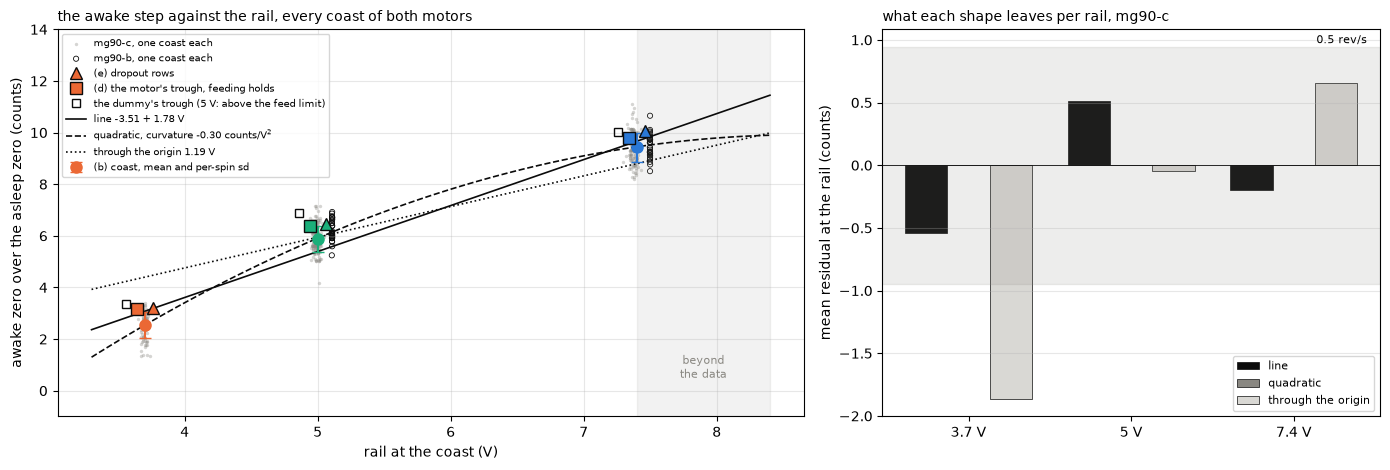

In [9]:
# the awake step against the rail: every spin, the per-rail means, and the three shapes
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [3, 2]})
a = ax[0]
oc = T[(T["motor"] == "mg90-c") & T["open_zero"].notna()]
ob = T[(T["motor"] == "mg90-b") & T["open_zero"].notna()]
rng = np.random.default_rng(0)
a.scatter(oc["rail_coast"] + rng.normal(0, 0.02, len(oc)), oc["open_zero"], s=6, color=MUTED, alpha=0.35, lw=0, label="mg90-c, one coast each")
a.scatter(ob["rail_coast"] + 0.12, ob["open_zero"], s=14, facecolors="none", edgecolors=INK, lw=0.6, label="mg90-b, one coast each")
for lv in LEVELS:
    L = LEV[lv]
    a.errorbar(lv, L["open_c"], yerr=L["open_c_sd"], fmt="o", color=RAIL_COLOR[lv], ms=8, capsize=4, lw=1.5, zorder=5,
               label="(b) coast, mean and per-spin sd" if lv == 3.7 else None)
    a.plot(lv + 0.06, L["dropout_c"], "^", color=RAIL_COLOR[lv], ms=8, mec=INK, zorder=5, label="(e) dropout rows" if lv == 3.7 else None)
    a.plot(lv - 0.06, L["trough_motor"], "s", color=RAIL_COLOR[lv], ms=8, mec=INK, zorder=6, label="(d) the motor's trough, feeding holds" if lv == 3.7 else None)
    a.plot(lv - 0.14, L["trough_dummy"], "s", color=RAIL_COLOR[lv], ms=6, mec=INK, mfc="none", zorder=5,
           label="the dummy's trough (5 V: above the feed limit)" if lv == 3.7 else None)
vv = np.linspace(3.3, 8.4, 100)
a.plot(vv, F["a"] + F["b"] * vv, "-", color=INK, lw=1.2, label=f"line {F['a']:+.2f} + {F['b']:.2f} V")
a.plot(vv, np.polyval(F["quad"], vv), "--", color=INK, lw=1.2, label=f"quadratic, curvature {F['quad'][0]:+.2f} counts/V$^2$")
a.plot(vv, F["b_origin"] * vv, ":", color=INK, lw=1.2, label=f"through the origin {F['b_origin']:.2f} V")
a.axvspan(7.4, 8.4, color=MUTED, alpha=0.1)
a.text(7.9, 0.5, "beyond\nthe data", ha="center", fontsize=8, color=MUTED)
a.set_xlabel("rail at the coast (V)"); a.set_ylabel("awake zero over the asleep zero (counts)")
a.set_title("the awake step against the rail, every coast of both motors", loc="left", fontsize=10); a.grid(alpha=0.3); a.legend(fontsize=7, loc="upper left")
a.set_ylim(-1, 14)
# the per-rail residual of each shape, against the 0.5 rev/s budget
a = ax[1]
x = np.arange(3)
for j, (key, lab, col) in enumerate((("per_level_resid", "line", INK), ("per_level_resid_quad", "quadratic", MUTED), ("per_level_resid_origin", "through the origin", "#d9d8d4"))):
    a.bar(x + (j - 1) * 0.26, [F[key][lv] for lv in LEVELS], 0.26, color=col, edgecolor=INK, lw=0.5, label=lab)
thr = 0.5 / rev_s_per_count("mg90-c")
a.axhspan(-thr, thr, color=MUTED, alpha=0.15); a.text(2.45, thr + 0.03, "0.5 rev/s", fontsize=8, ha="right")
a.axhline(0, color=INK, lw=0.6)
a.set_xticks(x, [f"{lv:g} V" for lv in LEVELS]); a.set_ylabel("mean residual at the rail (counts)")
a.set_title("what each shape leaves per rail, mg90-c", loc="left", fontsize=10); a.grid(alpha=0.3, axis="y"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

Left, the awake zero over the asleep zero on every coast, gray dots for mg90-c and open circles for mg90-b, with the per-rail mean and its per-spin standard deviation in the rail's color, the dropout rows as triangles, the motor's trough at the feeding duties as filled squares and the dummy's as open ones. The three shapes are drawn through mg90-c's coasts, and the shaded band past 7.4 V is where the 2S sag question takes them. Right, the mean residual each shape leaves at each rail, against the 0.5 rev/s budget. The thing to see is that the step is concave, 2.6 counts/V from 3.7 to 5 V and 1.5 from 5 to 7.4, so only the quadratic and the three points themselves sit inside the budget at every rail.

The awake zero sits 2.53, 5.88 and 9.43 counts over the asleep zero at 3.7, 5 and 7.4 V on mg90-c, 2.2, 5.2 and 8.3 mA, with a per-spin standard deviation of 0.5 to 0.6 counts and a standard error of 0.05 over 96, 156 and 144 coasts. mg90-b on the same board reads 6.20 and 9.49 at 5 and 7.4 V over 30 coasts each, 0.32 counts above mg90-c at 5 V (standard errors 0.07 and 0.04, different days) and 0.06 above at 7.4 V. So the step reproduces across motors and days to about 0.3 counts on this board, 0.3 mA or 0.17 rev/s. High confidence on the levels.

The shape is concave in the rail. A line through mg90-c's coasts, $-3.51\,(0.13) + 1.781\,(0.023)\,V$ counts, leaves per-rail residuals of $-0.54$, $+0.51$ and $-0.19$ counts, 11 and 13 standard errors of the coasts from zero at 3.7 and 5 V and 4 at 7.4 V, 0.27 rev/s at worst. A slope through the origin, 1.19 counts/V, leaves 1.1 counts rms. A quadratic with a curvature of $-0.30$ counts/V$^2$ leaves 0.52 counts, which is the per-spin scatter. mg90-b's two rails give 1.375 counts/V between 5 and 7.4 V against mg90-c's 1.48 over the same pair, and the dropout rows on mg90-c fit the same line within their errors. High confidence that the step is concave, moderate on its curvature, since three rails fix a quadratic with nothing left over.

The open bridge is settled from 0.1 ms after the cut: the 0.1 to 1 ms, 1 to 20 ms, 20 ms to the end and 100 to 300 ms windows read within 0.35 counts of each other at every rail, the tail 0.1 lower. trough-4, recorded on another day, reads 2.64, 5.92 and 9.41 counts in the same 1 to 20 ms window, within 0.11, 0.04 and 0.02 of the five datasets' pooled levels, and 2.60, 5.81 and 9.15 from 10 ms past the cut to the coast's end. At 7.4 V the early window sits 0.26 counts above the late coast (standard error 0.05), at the lower rails 0.04 and 0.11. It is not the body-diode tail, which is over in 0.25 ms, and it does not follow the speed at the cut, see the next section; which of the two levels a crest reading needs is open, and the gap is 0.14 rev/s. No schedule on either motor streams a brake, so (c) is not measured. The capture tool's post-rung brake is a three-tick slow-decay drive whose trough feeds like (d).

The switching share is small, and on the motor smaller than the dummy said. At the feeding duties trough-4's trough sits 0.12, 0.32 and 0.35 counts over the same chain's open bridge in its own column at 3.7, 5 and 7.4 V (standard error 0.07, 12 to 18 holds per rail) and 0.20, 0.41 and 0.60 over the crest column's open bridge, 0.17 to 0.53 mA or 0.10 to 0.32 rev/s. The dummy's trough at the feeding widths read 0.84 and 0.57 over the coast at 3.7 and 7.4 V, and its 5 V trough, with no burst at a feeding width, spread by a count between the bare resistor and the inductive wirings. So the dummy over-read the share at 3.7 V by about half a count, five standard errors of the motor's number, and the dropout rows, 0.58 to 0.67 over the open bridge on 3 to 18 spins, sit between the two. High confidence on the motor's levels, three repeats in both directions, and they are what the replay feeds. The zero stamped in each dummy burst's meta sits within about a count of (b) and (d) at all three rails, an integer with no history, so a weak check that a tracker on the board lands where the coasts do.

The asleep zero does not depend on the rail from 3.7 V up: 1205.9 to 1206.4 across the three levels, and the half count from 3.7 to 7.4 V is confounded with the sitting's drift, since every ladder ascends in rail with time. Stage 1 agrees, rest-noise at 1203 to 1204 at all three rails and the bare laps' rests at 1205 to 1206 from 3.7 to 7.6 V, and at 3.3 V the rest sits at 1189, $-16.5$ counts or 14.5 mA, 8.7 rev/s if a 3.7 V zero were kept there. The torque-off zero itself wanders across a dataset: the per-cycle baseline ranges 1.5 to 3.0 counts over 21 to 45 cycles, with slopes against the board NTC of $+1.0 \pm 0.2$, $+0.1 \pm 0.3$, $+1.1 \pm 0.3$, $+0.8 \pm 0.3$ and $-0.5 \pm 0.1$ counts/C by dataset, against opamp-temperature's 0.062 counts/C. It is not that tempco and not a consistent function of temperature. Its cause is open, and a tracker fed at every torque off follows it. The frame's two shunt samples differ at rest: on trough-4 the trough sample sits $0.175 \pm 0.008$ counts above the crest sample over the 36 baselines, and the bridge-states sweeps on the dummy read 0.07 to 0.50 the same way. The next section sizes it with the bridge open, where a trough-fed zero under a crest reading carries it.

## The trough on the motor

trough-4 carries the trough sample under 2 s holds at four duties per rail, three repeats in both directions, with a kick before each hold and a coast after it. Four questions are put to it. Does the trough move with the duty or with the winding current, which the holds confound and the kicks partly separate. Does it move with the speed or with the time within the hold. What zero error would each feeding gate admit, 20, 30, 40 or 60 % duty, read as the worst admitted hold's trough over the crest column's open bridge, since that is the zero a crest reading subtracts. And how far apart the frame's two shunt samples sit, at rest and awake, which a trough-fed zero under a crest reading carries whole.

In [10]:
RPC = rev_s_per_count("mg90-c")
# per rung: trough minus the same chain's coast, its own column (d_t) and the crest column (d_c), with the crest current over the zero
RUNG = TR.groupby(["level", "kind", "duty"]).agg(n=("k", "count"), ticks=("ticks", "first"), d_t=("d_t", "mean"), d_t_se=("d_t", "sem"), d_c=("d_c", "mean"),
                                                 d_c_se=("d_c", "sem"), worst=("d_c", lambda x: x.abs().max()), crest=("crest_over_zero", "mean"),
                                                 speed_cut=("speed_cut", "mean")).reset_index()
RUNG["d_c_ma"], RUNG["d_c_rev_s"] = RUNG["d_c"] * MA_PER_COUNT, RUNG["d_c"] * RPC
print("the trough per rung (counts; d_t = over the chain's coast in its own column, d_c = over the crest column's (b); crest = the winding current at the crest sample)")
print(RUNG.round(2).to_string(index=False))

# the step from the feeding holds (<= 20 %) to the wider ones, per rail
srows = []
for lv, g in HOLD.groupby("level"):
    lo, hi = g[g["duty"] <= FEED_PCT + 0.01]["d_t"], g[g["duty"] > FEED_PCT + 0.01]["d_t"]
    se = np.sqrt(lo.var(ddof=1) / len(lo) + hi.var(ddof=1) / len(hi))
    srows.append(dict(level=lv, n_le20=len(lo), n_gt20=len(hi), duties_gt20=" ".join(f"{d:.0f}" for d in sorted(hi.index.map(g["duty"]).unique())),
                      step=hi.mean() - lo.mean(), se=se, sigma=(hi.mean() - lo.mean()) / se,
                      resid_sd_step=np.sqrt(((g["d_t"] - np.where(g["duty"] <= FEED_PCT + 0.01, lo.mean(), hi.mean())) ** 2).sum() / (len(g) - 2)),
                      resid_sd_line_current=line_fit(g["crest_over_zero"], g["d_t"])[4].std(ddof=1), resid_sd_constant=g["d_t"].std(ddof=1)))
STEP = pd.DataFrame(srows)


def pooled_slope(g, xcol):
    # one common slope over the rails with one intercept per rail: the slope, its standard error, the residual sd
    X = np.column_stack([(g["level"] == lv).astype(float) for lv in LEVELS] + [g[xcol]])
    beta, *_ = np.linalg.lstsq(X, g["d_t"], rcond=None)
    res = g["d_t"] - X @ beta
    cov = (res ** 2).sum() / (len(g) - X.shape[1]) * np.linalg.inv(X.T @ X)
    return dict(b=float(beta[-1]), b_se=float(np.sqrt(cov[-1, -1])), resid_sd=float(np.sqrt((res ** 2).sum() / (len(g) - X.shape[1]))), n=len(g),
                intercepts={lv: float(beta[i]) for i, lv in enumerate(LEVELS)})


SLOPE_T = {(s, x): pooled_slope(g, x) for s, g in (("holds", HOLD), ("holds + kicks", TR)) for x in ("crest_over_zero", "duty")}
LEAK_BOUND_PCT = (SLOPE_T[("holds", "crest_over_zero")]["b"] + 2 * SLOPE_T[("holds", "crest_over_zero")]["b_se"]) * 100
print("\nthe step from the feeding holds to the wider ones per rail, and the residual sd of a step at 20 %, of a line on the current, of a constant")
print(STEP.round(3).to_string(index=False))
print("pooled slopes of d_t with one intercept per rail: " + "; ".join(f"{s}, {x}: {f['b']:+.4f} +/- {f['b_se']:.4f} ({f['b'] / f['b_se']:.1f} sigma), resid sd {f['resid_sd']:.2f}"
                                                                for (s, x), f in SLOPE_T.items()))
print(f"a current leak is bounded at {LEAK_BOUND_PCT:.2f} % of the crest current (2 se upper, holds), "
      f"{(SLOPE_T[('holds + kicks', 'crest_over_zero')]['b'] + 2 * SLOPE_T[('holds + kicks', 'crest_over_zero')]['b_se']) * 100:.2f} % with the kicks")

# the gate candidates: the zero error (d_c) the widest admitted hold feeds per rail, its 2 se upper, the kicks the gate admits
grows = []
for pct in GATES_PCT:
    for lv, g in HOLD.groupby("level"):
        adm = g[g["duty"] <= pct + 0.01]
        per = adm.groupby("duty")["d_c"].agg(["mean", "sem", "count"])
        w = per["mean"].idxmax()
        kicks = TR[(TR["kind"] == "kick") & (TR["level"] == lv) & (TR["duty"] <= pct + 0.01)]["d_c"]
        grows.append(dict(gate_pct=pct, gate_ticks=gate_ticks(pct), level=lv, duties_admitted=" ".join(f"{d:.0f}" for d in sorted(adm["duty"].unique())),
                          worst_rung=w, worst_counts=per.loc[w, "mean"], worst_se=per.loc[w, "sem"], upper_2se=per.loc[w, "mean"] + 2 * per.loc[w, "sem"],
                          worst_ma=per.loc[w, "mean"] * MA_PER_COUNT, worst_rev_s=per.loc[w, "mean"] * RPC, upper_rev_s=(per.loc[w, "mean"] + 2 * per.loc[w, "sem"]) * RPC,
                          pooled=adm["d_c"].mean(), kick_admitted=kicks.mean() if len(kicks) else np.nan))
GATE = pd.DataFrame(grows)
GW = GATE.loc[GATE.groupby("gate_pct")["worst_counts"].idxmax()].set_index("gate_pct")     # the worst admitted rung over the rails, per gate
print("\ngate candidates: the zero error the widest admitted hold feeds per rail (d_c, counts), and the kick the gate admits")
print(GATE.round(2).to_string(index=False))
print("worst over the rails per gate: " + "; ".join(f"{p} %: {r['level']:g} V {r['worst_rung']:.0f} % {r['worst_counts']:.2f} counts = {r['worst_rev_s']:.2f} rev/s (2 se upper {r['upper_rev_s']:.2f})"
                                                   for p, r in GW.iterrows()))

# time within the hold: the quarters (0.5 s each), the per-hold slope per quarter, the kick against the last quarter
Q = HOLD.copy()
for qn in (1, 2, 3, 4):
    Q[f"dq{qn}"] = Q[f"trough_q{qn}"] - Q["coast_trough"]
Q["d_kick"] = [TR[(TR["k"] == r["k"]) & (TR["kind"] == "kick") & (TR["dir"] == r["dir"])]["d_t"].iloc[0] for _, r in Q.iterrows()]
Q["slope_q"] = [np.polyfit([1, 2, 3, 4], [r[f"dq{qn}"] for qn in (1, 2, 3, 4)], 1)[0] for _, r in Q.iterrows()]
QR = Q.groupby("level").agg(n=("k", "count"), slope_per_quarter=("slope_q", "mean"), slope_se=("slope_q", "sem"),
                            kick_minus_q4=("d_kick", lambda x: (x - Q.loc[x.index, "dq4"]).mean()),
                            kick_minus_q4_se=("d_kick", lambda x: (x - Q.loc[x.index, "dq4"]).sem())).reset_index()
QR["over_hold"] = QR["slope_per_quarter"] * 3
QRUNG = Q.groupby(["level", "duty"])[["d_kick", "dq1", "dq2", "dq3", "dq4", "crest_q1", "crest_q4", "speed_cut"]].mean().reset_index()
print("\nthe trough through the hold, per rail: the slope per quarter (0.5 s) across holds, the kick against the last quarter (counts)")
print(QR.round(3).to_string(index=False))

# the coast with no current: the first 1 to 20 ms over the late level, per chain, against the speed at the cut (the rotor stops within 100 to 200 ms)
E = HOLD.assign(early_trough=HOLD["coast_trough_open"] - HOLD["coast_trough"], early_crest=HOLD["coast_crest_open"] - HOLD["coast_crest"])
erows = []
for lv, g in E.groupby("level"):
    for col in ("early_trough", "early_crest"):
        a_, b_, sa_, sb_, res = line_fit(g["speed_cut"], g[col])
        erows.append(dict(level=lv, column=col, n=len(g), mean=g[col].mean(), se=g[col].sem(), slope_per_100rev_s=b_ * 100, slope_se=sb_ * 100,
                          speed_lo=g["speed_cut"].min(), speed_hi=g["speed_cut"].max()))
EARLY = pd.DataFrame(erows)
print("\nthe coast's first 1 to 20 ms over its late level, per rail, against the speed at the cut (counts, counts per 100 rev/s)")
print(EARLY.round(3).to_string(index=False))
# d_t on the duty and the modeled speed together: w = (D V - i R) / Ke per spin, a model line used for the range only
A2 = TR.assign(speed_model=(TR["duty"] / 100 * TR["rail_spin"] - TR["crest_over_zero"] * MA_PER_COUNT * 1e-3 * MOTORS["mg90-c"]["r_ohm"]) * 1e3 / MOTORS["mg90-c"]["ke_mv_per_rev_s"])
X = np.column_stack([(A2["level"] == lv).astype(float) for lv in LEVELS] + [A2["duty"], A2["speed_model"]])
beta, *_ = np.linalg.lstsq(X, A2["d_t"], rcond=None)
res = A2["d_t"] - X @ beta
cov = (res ** 2).sum() / (len(A2) - X.shape[1]) * np.linalg.inv(X.T @ X)
BOTH = dict(duty=beta[-2], duty_se=np.sqrt(cov[-2, -2]), speed=beta[-1] * 100, speed_se=np.sqrt(cov[-1, -1]) * 100, lo=A2["speed_model"].min(), hi=A2["speed_model"].max())
print(f"d_t on the duty and the modeled speed together (holds + kicks, n {len(A2)}): duty {BOTH['duty']:+.4f} +/- {BOTH['duty_se']:.4f} counts per %, "
      f"speed {BOTH['speed']:+.3f} +/- {BOTH['speed_se']:.3f} counts per 100 rev/s, over {BOTH['lo']:.0f} to {BOTH['hi']:.0f} rev/s")

# the frame's two shunt samples: the trough sample over the crest sample at rest, per cycle, and with the bridge open awake
ZB = pd.DataFrame([dict(k=r["k"], level=r["level"], diff=r["z_trough"] - r["zero_i"], z_crest=r["zero_i"]) for r in reduce_dataset(*REAL)])
FRAME_REST = dict(mean=ZB["diff"].mean(), se=ZB["diff"].sem(), sd=ZB["diff"].std(ddof=1), by_rail={lv: g["diff"].mean() for lv, g in ZB.groupby("level")})
AW = HOLD.assign(awake_diff=HOLD["z_diff"] + HOLD["coast_trough"] - HOLD["coast_crest"])
FRAME_AWAKE = dict(mean=AW["awake_diff"].mean(), se=AW["awake_diff"].sem(), by_rail={lv: g["awake_diff"].mean() for lv, g in AW.groupby("level")})
print(f"\nthe trough sample over the crest sample: at rest {FRAME_REST['mean']:+.3f} +/- {FRAME_REST['se']:.3f} counts (sd {FRAME_REST['sd']:.3f} over {len(ZB)} baselines; "
      + ", ".join(f"{lv:g} V {v:+.3f}" for lv, v in FRAME_REST["by_rail"].items()) + f"); with the bridge open awake {FRAME_AWAKE['mean']:+.3f} +/- {FRAME_AWAKE['se']:.3f} ("
      + ", ".join(f"{lv:g} V {v:+.3f}" for lv, v in FRAME_AWAKE["by_rail"].items()) + f") = {FRAME_AWAKE['mean'] * MA_PER_COUNT:.2f} mA, {FRAME_AWAKE['mean'] * RPC:.2f} rev/s; "
      f"the crest baseline wanders {ZB['z_crest'].max() - ZB['z_crest'].min():.2f} counts across the recording")

the trough per rung (counts; d_t = over the chain's coast in its own column, d_c = over the crest column's (b); crest = the winding current at the crest sample)
 level kind  duty  n  ticks  d_t  d_t_se  d_c  d_c_se  worst  crest  speed_cut  d_c_ma  d_c_rev_s
   3.7 hold  16.0  6    192 0.05    0.12 0.16    0.10   0.49  56.07      44.75    0.14       0.09
   3.7 hold  20.0  6    240 0.18    0.08 0.23    0.09   0.52  60.97      60.94    0.20       0.12
   3.7 hold  30.0  6    360 0.62    0.10 0.70    0.10   1.05  71.74     102.34    0.62       0.37
   3.7 hold  60.0  6    720 0.62    0.09 0.73    0.09   1.01  90.72     229.40    0.64       0.39
   3.7 kick  40.0 24    480 0.50    0.08 0.59    0.08   1.20  97.86     109.36    0.52       0.31
   5.0 hold  12.0  6    144 0.38    0.13 0.48    0.12   0.81  59.80      43.93    0.43       0.26
   5.0 hold  15.0  6    180 0.45    0.16 0.54    0.15   0.89  64.87      61.07    0.47       0.28
   5.0 hold  20.0  6    240 0.12    0.08 0.21    0.09  

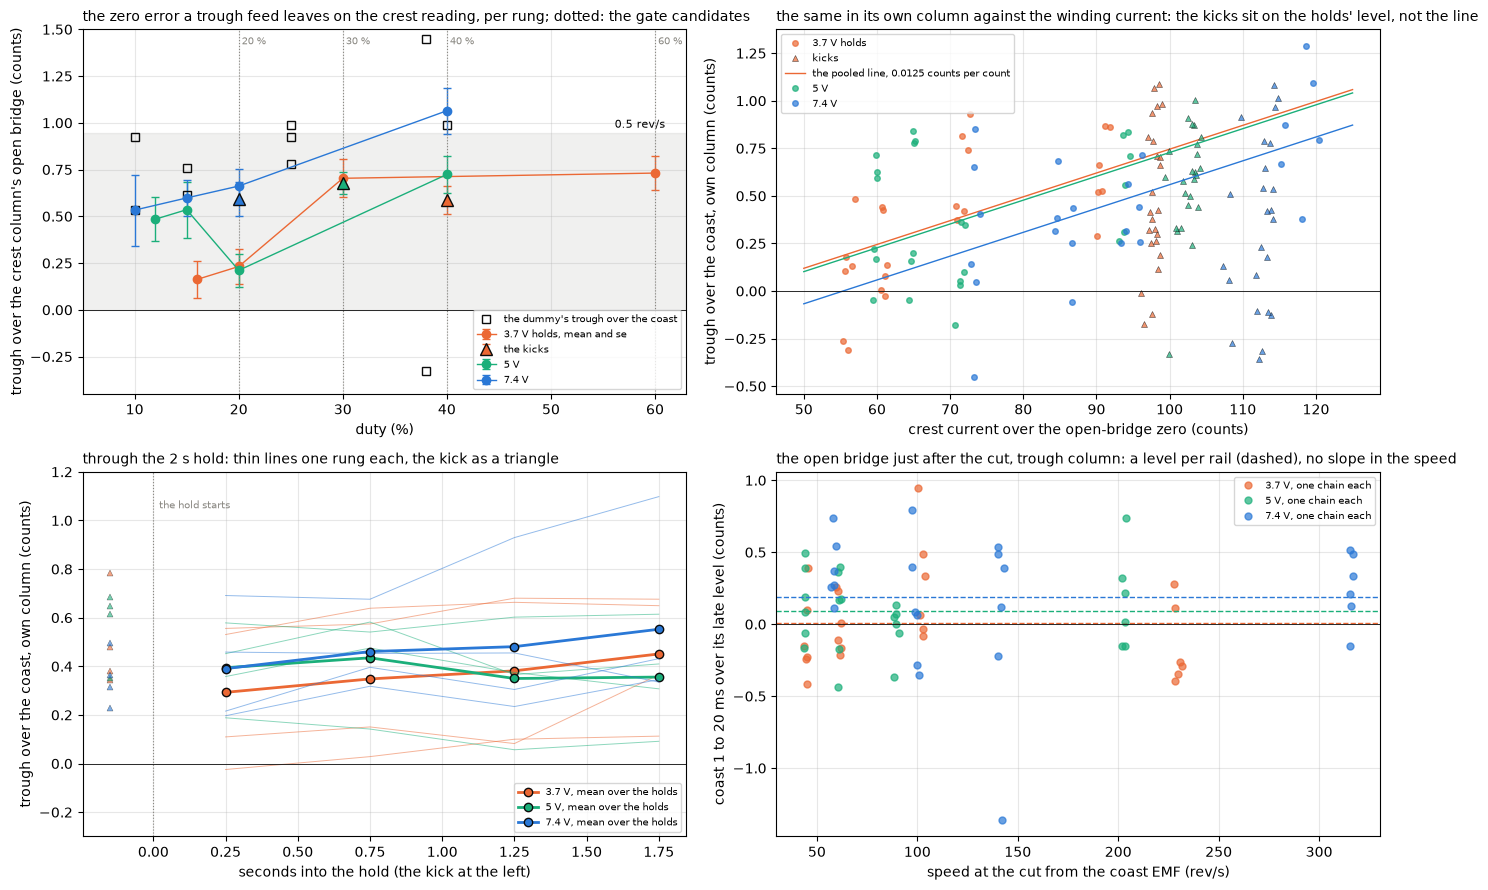

In [11]:
# the motor's trough: against the duty, against the current, through the hold, and the coast against the speed
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
thr = 0.5 / RPC
a = ax[0, 0]
for lv in LEVELS:
    h = RUNG[(RUNG["level"] == lv) & (RUNG["kind"] == "hold")]
    k = RUNG[(RUNG["level"] == lv) & (RUNG["kind"] == "kick")]
    a.errorbar(h["duty"], h["d_c"], yerr=h["d_c_se"], fmt="o-", color=RAIL_COLOR[lv], ms=6, capsize=3, lw=1, label=f"{lv:g} V holds, mean and se" if lv == 3.7 else f"{lv:g} V")
    a.errorbar(k["duty"], k["d_c"], yerr=k["d_c_se"], fmt="^", color=RAIL_COLOR[lv], ms=8, mec=INK, capsize=3, lw=1, label="the kicks" if lv == 3.7 else None)
    dd = D[(np.abs(D["rail"] - lv) < 0.3)].groupby("ticks")["trough_level"].mean() - LEV[lv]["open_c"]
    a.plot(dd.index / ARR * 100, dd.values, "s", color=RAIL_COLOR[lv], ms=6, mec=INK, mfc="none", label="the dummy's trough over the coast" if lv == 3.7 else None)
for p in GATES_PCT:
    a.axvline(p, color=MUTED, lw=0.8, ls=":")
    a.text(p, 1.42, f" {p} %", fontsize=7, color=MUTED)
a.axhspan(0, thr, color=MUTED, alpha=0.12); a.text(61, thr + 0.03, "0.5 rev/s", fontsize=8, ha="right")
a.axhline(0, color=INK, lw=0.6); a.set_xlim(5, 63); a.set_ylim(-0.45, 1.5)
a.set_xlabel("duty (%)"); a.set_ylabel("trough over the crest column's open bridge (counts)")
a.set_title("the zero error a trough feed leaves on the crest reading, per rung; dotted: the gate candidates", loc="left", fontsize=10); a.grid(alpha=0.3); a.legend(fontsize=7, loc="lower right")
a = ax[0, 1]
for lv in LEVELS:
    h = TR[(TR["level"] == lv) & (TR["kind"] == "hold")]
    k = TR[(TR["level"] == lv) & (TR["kind"] == "kick")]
    a.plot(h["crest_over_zero"], h["d_t"], "o", color=RAIL_COLOR[lv], ms=4, alpha=0.7, label=f"{lv:g} V holds" if lv == 3.7 else f"{lv:g} V")
    a.plot(k["crest_over_zero"], k["d_t"], "^", color=RAIL_COLOR[lv], ms=5, mec=INK, mew=0.4, alpha=0.7, label="kicks" if lv == 3.7 else None)
    f = SLOPE_T[("holds", "crest_over_zero")]
    xx = np.linspace(50, 125, 10)
    a.plot(xx, f["intercepts"][lv] + f["b"] * xx, "-", color=RAIL_COLOR[lv], lw=1, label=f"the pooled line, {f['b']:.4f} counts per count" if lv == 3.7 else None)
a.axhline(0, color=INK, lw=0.6); a.set_xlabel("crest current over the open-bridge zero (counts)"); a.set_ylabel("trough over the coast, own column (counts)")
a.set_title("the same in its own column against the winding current: the kicks sit on the holds' level, not the line", loc="left", fontsize=10); a.grid(alpha=0.3); a.legend(fontsize=7)
a = ax[1, 0]
tq = np.array([0.25, 0.75, 1.25, 1.75])
for lv in LEVELS:
    for _, r in QRUNG[QRUNG["level"] == lv].iterrows():
        a.plot(tq, [r[f"dq{qn}"] for qn in (1, 2, 3, 4)], "-", color=RAIL_COLOR[lv], lw=0.7, alpha=0.5)
        a.plot(-0.15, r["d_kick"], "^", color=RAIL_COLOR[lv], ms=5, mec=INK, mew=0.3, alpha=0.6)
    m = Q[Q["level"] == lv]
    a.plot(tq, [m[f"dq{qn}"].mean() for qn in (1, 2, 3, 4)], "o-", color=RAIL_COLOR[lv], lw=2, ms=6, mec=INK, label=f"{lv:g} V, mean over the holds")
a.axvline(0, color=MUTED, lw=0.8, ls=":"); a.text(0.02, 1.05, "the hold starts", fontsize=7, color=MUTED)
a.axhline(0, color=INK, lw=0.6); a.set_ylim(-0.3, 1.2)
a.set_xlabel("seconds into the hold (the kick at the left)"); a.set_ylabel("trough over the coast, own column (counts)")
a.set_title("through the 2 s hold: thin lines one rung each, the kick as a triangle", loc="left", fontsize=10); a.grid(alpha=0.3); a.legend(fontsize=7)
a = ax[1, 1]
for lv in LEVELS:
    g = E[E["level"] == lv]
    a.plot(g["speed_cut"], g["early_trough"], "o", color=RAIL_COLOR[lv], ms=5, alpha=0.7, label=f"{lv:g} V, one chain each")
    r = EARLY[(EARLY["level"] == lv) & (EARLY["column"] == "early_trough")].iloc[0]
    a.axhline(r["mean"], color=RAIL_COLOR[lv], lw=1, ls="--")
a.axhline(0, color=INK, lw=0.6); a.set_xlabel("speed at the cut from the coast EMF (rev/s)"); a.set_ylabel("coast 1 to 20 ms over its late level (counts)")
a.set_title("the open bridge just after the cut, trough column: a level per rail (dashed), no slope in the speed", loc="left", fontsize=10); a.grid(alpha=0.3); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

Top left, the trough over the crest column's open bridge per rung, the holds as circles with their standard error and the kicks as triangles, in the rail's color, with the dummy's trough over the coast as open squares and the gate candidates dotted; the gray band is the 0.5 rev/s budget. Top right, the same in the trough's own column against the winding current at the crest, with the pooled line through the holds: the kicks, at 98 to 113 counts of crest, sit at the level of the holds of their duty and not on the line. Bottom left, the trough through the 2 s hold in quarters, one thin line per rung and the per-rail mean bold, with the kick before it. Bottom right, the open bridge in its first 1 to 20 ms over its late level against the speed the rotor had at the cut.

The trough rises above 20 % duty and is flat below it. From the feeding holds to the wider ones it steps up $0.51 \pm 0.10$, $0.27 \pm 0.13$ and $0.50 \pm 0.15$ counts at 3.7, 5 and 7.4 V, and at 3.7 V the 60 % rung reads the same as the 30 % one, so the rise is in by 30 %. Pooled over the holds with one intercept per rail the slope is $0.0125 \pm 0.0025$ counts per count of crest current, or equally $0.0127 \pm 0.0027$ per percent of duty, since the crest rises with the duty inside each rail and neither axis is identified on the holds alone. The kicks break the tie a little: at 98 to 113 counts of crest they read no higher than the holds of their duty, which halves the current slope to $0.0072 \pm 0.0017$ and leaves the duty slope where it was. A two-level step at 20 % fits the holds as well as either line, residual 0.24 to 0.31 counts against 0.26 to 0.32. The reading is a duty effect of about half a count above 20 %, most likely in the brake half's switching, with a current leak bounded at 1.75 % of the crest current, 1.1 % with the kicks. High confidence that the trough above 20 % is higher, moderate that it is the duty and not a leak.

Neither the speed nor the time within the hold moves it. The rotor settles inside the kick, so within a hold the modeled speed changes by 1 to 4 % and the crest by 1 to 15 counts, and the quarters test time more than speed: the trough drifts $+0.051 \pm 0.016$, $-0.020 \pm 0.019$ and $+0.051 \pm 0.024$ counts per half second at the three rails, 0.15 counts over the 2 s hold at most, a quarter of the per-spin scatter. Across rungs the kick, the fastest part of a low chain, reads $+0.05 \pm 0.09$, $+0.22 \pm 0.07$ and $-0.20 \pm 0.14$ counts against the hold's last quarter, a sign per rail. With the duty and the modeled speed in one fit over the holds and the kicks neither reaches one standard error of itself. In the coast, with no current at all, the first 1 to 20 ms read $+0.01$, $+0.09$ and $+0.19$ counts over the late level in the trough column and $+0.03$, $+0.11$ and $+0.27$ in the crest column, with slopes against the speed at the cut of $-0.07$, $+0.04$ and $-0.01 \pm 0.09$ counts per 100 rev/s over 43 to 317 rev/s. High confidence that no speed term above 0.2 counts exists in this range. The early coast's excess scales with the rail and not with the speed; a settling or thermal tail of the driver after the drive would fit it, nothing here tests that, low confidence on any reading.

The gates. The zero error the widest admitted hold feeds, against the crest column's open bridge, is 0.66 counts at 20 % (the 7.4 V 20 % rung, 0.35 rev/s), 0.70 at 30 % (3.7 V 30 %, 0.37 rev/s, nothing new over what 7.4 V 20 % already pays), 1.06 at 40 % (7.4 V 40 %, 0.56 rev/s, over the line, 1.31 at two standard errors), and the same at 60 %, which is measured at 3.7 V only and reads 0.73 there. The kicks a wider gate admits read $+0.59$ to $+0.68$, the same as the holds of their duty. On this evidence the gate can go to 30 % at no cost, and not to 40 %. Moderate confidence: six spins per rung, no 30 % rung at 5 or 7.4 V, nothing between 40 and 60 % but at 3.7 V.

The frame's two samples. At rest the trough sample sits $0.175 \pm 0.008$ counts above the crest sample over the 36 baselines, 0.20, 0.19 and 0.13 by rail, and with the bridge open awake 0.32, 0.29 to 0.38 by rail. A zero fed from the trough and read against the crest therefore sits 0.3 counts high, 0.28 mA or 0.17 rev/s, at every duty and in every coast, a systematic the replay on the real feed carries and the modeled one did not. High confidence on this board. The crest baseline itself wanders 3.2 counts over the recording, which both samples follow.

## The tracker replayed over the captures

The port first. Integer arithmetic as specified, a feed moving the fed zero by $((x \ll 16) - z) \gg 13$, the other zero's stale counter aging on every tick, and a stale zero moving by the same delta. The checks below run the port's arithmetic through a seed, a constant feed, a step closing 63.2 % in one time constant and 100 % in eleven, and a stale zero following the other's move.

In [12]:
ASLEEP, COAST, DRIVE = 0, 1, 2            # bridge states; the brake is a 3-tick DRIVE
K_NONE, K_ASLEEP, K_AWAKE = -1, 0, 1      # which zero a tick feeds


@nb.njit
def run_tracker(kind, sample, awake_q, asleep_q, awake_fresh, asleep_fresh, out_awake, out_asleep):
    # the tick loop: a feed moves its zero by ((sample << 16) - zero) >> 13 (an arithmetic shift, so it floors), ages the
    # other zero's counter, and once that one is stale moves it by the same delta; a tick with no feed ages both
    for i in range(kind.shape[0]):
        k = kind[i]
        if k == 1:
            delta = ((np.int64(sample[i]) << 16) - awake_q) >> 13
            awake_q += delta
            if asleep_fresh > 1:
                asleep_fresh -= 1
            else:
                asleep_fresh = 0
                asleep_q += delta
            awake_fresh = 65535
        elif k == 0:
            delta = ((np.int64(sample[i]) << 16) - asleep_q) >> 13
            asleep_q += delta
            if awake_fresh > 1:
                awake_fresh -= 1
            else:
                awake_fresh = 0
                awake_q += delta
            asleep_fresh = 65535
        else:
            if awake_fresh > 0:
                awake_fresh -= 1
            if asleep_fresh > 0:
                asleep_fresh -= 1
        out_awake[i] = awake_q
        out_asleep[i] = asleep_q
    return awake_q, asleep_q, awake_fresh, asleep_fresh


@nb.njit
def rail_ewma(kind, rail, state, out):
    # a float EWMA of the rail at the same gain, fed on the awake-fed ticks only and held otherwise: the rail the awake
    # zero's value was learned at, method B's extra state
    a = 1.0 / (1 << 13)
    for i in range(kind.shape[0]):
        if kind[i] == 1:
            state += a * (rail[i] - state)
        out[i] = state
    return state


def counts(q):
    # the rounded output, as a reading would subtract it
    return np.maximum((np.asarray(q, np.int64) + (1 << (FRAC - 1))) >> FRAC, 0)


def q_to_float(q):
    return np.asarray(q, np.float64) / (1 << FRAC)


class Tracker:
    def __init__(self):
        self.awake_q = self.asleep_q = np.int64(0)
        self.awake_fresh = self.asleep_fresh = np.int64(0)

    def seed(self, c):
        # the boot seed: both zeros at the rest measurement, the step unknown
        self.awake_q = np.int64(int(c)) << FRAC
        self.asleep_q = self.awake_q

    def run(self, kind, sample):
        out_a, out_s = np.empty(len(kind), np.int64), np.empty(len(kind), np.int64)
        self.awake_q, self.asleep_q, self.awake_fresh, self.asleep_fresh = run_tracker(
            kind.astype(np.int8), np.asarray(sample).astype(np.int64), self.awake_q, self.asleep_q, self.awake_fresh, self.asleep_fresh, out_a, out_s)
        return out_a, out_s


def kinds_from_bridge(bridge, ticks, gate=TROUGH_FEED_MAX_TICKS):
    # the feed kind per tick from the bridge state and the drive width: a drive at or under the gate feeds the awake zero at once,
    # a rest feeds the asleep zero and a coast the awake zero once 32 ticks past the last change, anything else feeds nothing
    n = len(bridge)
    change = np.ones(n, bool)
    change[1:] = bridge[1:] != bridge[:-1]
    idx = np.arange(n)
    since = idx - np.maximum.accumulate(np.where(change, idx, 0))
    kind = np.full(n, K_NONE, np.int8)
    kind[(bridge == DRIVE) & (ticks > 0) & (ticks <= gate)] = K_AWAKE
    settled = since >= ZERO_SETTLE_TICKS
    kind[(bridge == ASLEEP) & settled] = K_ASLEEP
    kind[(bridge == COAST) & settled] = K_AWAKE
    return kind


# the port's arithmetic checked: a seed held, 63.2 % of a step at one tau and all of it by eleven, a stale zero following
TAU = 1 << ALPHA_SHIFT
t = Tracker(); t.seed(2048)
a_, s_ = t.run(np.full(4 * TAU, K_AWAKE, np.int8), np.full(4 * TAU, 2048))
assert (counts(a_) == 2048).all()
for frm, to in ((2048, 2088), (2088, 2048), (0, 2048)):
    t = Tracker(); t.seed(frm)
    a_, s_ = t.run(np.full(TAU, K_AWAKE, np.int8), np.full(TAU, to))
    assert abs(int(counts(a_[-1])) - (frm + ((to - frm) * 632) // 1000)) <= 1
    a_, s_ = t.run(np.full(11 * TAU, K_AWAKE, np.int8), np.full(11 * TAU, to))
    assert counts(a_[-1]) == to
t = Tracker(); t.seed(460)
t.run(np.full(64, K_ASLEEP, np.int8), np.full(64, 460))
a_, s_ = t.run(np.full(12 * TAU, K_AWAKE, np.int8), np.full(12 * TAU, 470))
assert counts(a_[-1]) == 470 and counts(s_[-1]) == 460
a_, s_ = t.run(np.full(STALE_TICKS, K_ASLEEP, np.int8), np.full(STALE_TICKS, 460))
assert counts(a_[-1]) == 470                                   # not yet stale: the awake zero holds
a_, s_ = t.run(np.full(12 * TAU, K_ASLEEP, np.int8), np.full(12 * TAU, 260))
assert counts(a_[-1]) == 270 and counts(s_[-1]) == 260         # stale: it followed the asleep zero's move
print(f"the port holds its checks; tau {TAU_S:.3f} s, a feed at <= {TROUGH_FEED_MAX_TICKS} ticks ({TROUGH_FEED_MAX_TICKS / ARR * 100:.0f} % duty) as first specified, the brake {BRAKE_TICKS} ticks")

the port holds its checks; tau 0.410 s, a feed at <= 240 ticks (20 % duty) as first specified, the brake 3 ticks


The replay builds each dataset tick by tick from the records, runs the port once through it, and reads the awake zero at every spin. On the five datasets without the trough the feeding rows carry the motor's measured level; the recording with the trough is replayed on its own samples in the next section.

In [13]:
NOISE_TROUGH = 1.0                 # counts rms on the synthetic trough: the motor's trough rows read 1.0 to 1.5 per row, the dummy's band 0.2 to 0.9
PRE_DRIVE_COAST_S = 0.005          # torque on to the stream's first row, segments.csv


def per_rail_open(recs, motor):
    # the dataset's own open-bridge zero per rail (the mean over its spins), the truth; the motor-wide level fills a rail it lacks
    acc = {}
    for r in recs:
        for s in r["segs"]:
            if s["cmd"] != 0 and "open_zero" in s:
                acc.setdefault(r["level"], []).append(s["open_zero"])
    out = {k: float(np.mean(v)) for k, v in acc.items()}
    for lv in LEVELS:
        out.setdefault(lv, LEV[lv]["open_c"] if motor == "mg90-c" or not np.isfinite(LEV[lv]["open_b"]) else LEV[lv]["open_b"])
    return out


D_MINUS_B = float(np.mean([LEV[lv]["trough_dummy"] - LEV[lv]["open_c"] for lv in LEVELS if not LEV[lv]["trough_above_feed_limit"]]))


def trough_level(level, mode, motor, own_open):
    # the level a feeding width's trough is synthesized at: (m) the motor's measured trough over the same chain's open bridge in its own
    # column, per rail; (d) the dummy's trough where a feeding width was measured, else the open bridge plus the mean (d) - (b);
    # (e) the dropout rows; (b) the open bridge itself
    L = LEV[level]
    if mode == "m":
        return own_open + L["d_t_motor"]
    if mode == "d":
        return own_open + (D_MINUS_B if L["trough_above_feed_limit"] else L["trough_dummy"] - L["open_c"])
    if mode == "e":
        use_b = motor == "mg90-b" and np.isfinite(L["dropout_b"])
        return own_open + ((L["dropout_b"] if use_b else L["dropout_c"]) - (L["open_b"] if use_b else L["open_c"]))
    return own_open


def chain_gap_default():
    # a coast's end to the next chain's first row where segments.csv exists, for the dataset without one
    gaps = []
    for r in reduce_dataset("mg90-c", "capture-1"):
        S = r["segs"]
        gaps += [S[i]["t_start"] - S[i - 1]["t_end"] for i in range(1, len(S)) if S[i - 1]["cmd"] == 0 and S[i]["cmd"] != 0 and np.isfinite(S[i]["t_start"])]
    return float(np.median(gaps))


def synth_times(recs, gap):
    # segments.csv's stand-in: back to back within a chain, the median chain gap between chains, from the cycle's start
    for r in recs:
        t, prev_cmd = r["t_start"] + 0.09, None
        for s in r["segs"]:
            if prev_cmd == 0 and s["seg"] > 1:
                t += gap
            elif prev_cmd is not None:
                t += PRE_DRIVE_COAST_S
            s["t_start"], s["t_end"] = t, t + s["n"] / FS
            t, prev_cmd = s["t_end"], s["cmd"]
    return recs


def build_cycle(r, prev_end, next_start, zero_rest, own_open, tr_level, brake_s, rng):
    # one cycle's per-tick bridge state, drive ticks, shunt samples and rail, plus the rest after it, and each segment's row span
    bridge, ticks, samples, rails, marks = [], [], [], [], {}
    n_at = 0

    def push(b, tk, smp, rail=None):
        nonlocal n_at
        n = len(smp)
        bridge.append(np.full(n, b, np.int8)); ticks.append(np.full(n, tk, np.int16) if np.isscalar(tk) else tk)
        samples.append(smp); rails.append(np.full(n, r["rail_rest"], np.float32) if rail is None else rail)
        n_at += n

    def noise(level, sd, n):
        return np.floor(level + sd * rng.standard_normal(n) + 0.5).astype(np.int32)   # integer codes about a level

    S = r["segs"]
    n_gap = max(int(round((S[0]["t_start"] - prev_end) * FS)), 0) if np.isfinite(prev_end) else 2 * FS
    push(ASLEEP, 0, noise(zero_rest, NOISE_REST, n_gap))                          # the rest before the baseline
    for i, s in enumerate(S):
        if i > 0:
            gap = max(int(round((s["t_start"] - S[i - 1]["t_end"]) * FS)), 0)
            if S[i - 1]["cmd"] == 0 and S[i - 1]["seg"] != 0 and s["cmd"] != 0:
                nb_, nc = int(round(brake_s * FS)), int(round(PRE_DRIVE_COAST_S * FS))   # a chain's end: brake, torque off, the pre-drive coast
                push(DRIVE, BRAKE_TICKS, noise(tr_level, NOISE_TROUGH, nb_))
                push(ASLEEP, 0, noise(zero_rest, NOISE_REST, max(gap - nb_ - nc, 0)))
                push(COAST, 0, noise(own_open, NOISE_REST, nc))
            else:
                push(COAST, 0, noise(own_open, NOISE_REST, gap))                   # after the baseline, or within a chain
        marks[s["seg"]] = (n_at, n_at + s["n"])
        tk, raw, rail = s["ticks"].astype(np.int16), s["raw"].astype(np.int32), BOARD.rail_v(s["vbus"]).astype(np.float32)
        if s["seg"] == 0:
            push(ASLEEP, 0, raw, rail)                                              # the baseline's real rows
        else:
            feed = (tk > 0) & (tk <= TROUGH_FEED_MAX_TICKS)
            smp = raw.copy()
            smp[feed] = noise(tr_level, NOISE_TROUGH, int(feed.sum()))              # the trough the stream did not carry
            bridge.append(np.where(tk > 0, DRIVE, COAST).astype(np.int8)); ticks.append(tk); samples.append(smp); rails.append(rail)
            n_at += len(tk)
    nb_ = int(round(brake_s * FS))
    push(DRIVE, BRAKE_TICKS, noise(tr_level, NOISE_TROUGH, nb_))                    # the last chain's brake
    end = next_start - PRE_DRIVE_COAST_S if np.isfinite(next_start) else S[-1]["t_end"] + 2.0
    n_rest = max(int(round((end - S[-1]["t_end"]) * FS)) - nb_, 0)
    push(ASLEEP, 0, noise(zero_rest, NOISE_REST, n_rest))                           # torque off to the next cycle
    return np.concatenate(bridge), np.concatenate(ticks), np.concatenate(samples), np.concatenate(rails), marks, S[-1]["t_end"] + (nb_ + n_rest) / FS


def simulate(motor, name, mode="m", brake_s=BRAKE_POLL_S, trace_every=0, rng_seed=1):
    # the tracker through one dataset in time order, seeded at its first baseline: one row per spin, and a decimated trace if asked
    recs = reduce_dataset(motor, name)
    if not np.isfinite(recs[0]["segs"][0]["t_start"]):
        recs = synth_times(recs, chain_gap_default())
    opens = per_rail_open(recs, motor)
    rng = np.random.default_rng(rng_seed)
    t = Tracker()
    t.seed(round(recs[0]["zero_i"]))
    rows, trace = [], []
    prev_end, prev_level, tick0 = np.nan, None, 0
    last_feed_rail, rail_state = recs[0]["rail_rest"], float(recs[0]["rail_rest"])
    rpc = rev_s_per_count(motor)
    first_chain = {s["seg"] for s in recs[0]["segs"][:next(i for i, s in enumerate(recs[0]["segs"]) if s["seg"] > 0 and s["cmd"] == 0) + 1]}
    for ci, r in enumerate(recs):
        own_open = r["zero_i"] + opens[r["level"]]
        tr = trough_level(r["level"], mode, motor, own_open)
        zero_rest = r["zero_i"] if ci == 0 else 0.5 * (r["zero_i"] + recs[ci - 1]["zero_i"])   # the rest between two cycles
        next_start = recs[ci + 1]["segs"][0]["t_start"] if ci + 1 < len(recs) else np.nan
        bridge, ticks, samples, rails, marks, prev_end = build_cycle(r, prev_end, next_start, zero_rest, own_open, tr, brake_s, rng)
        kind = kinds_from_bridge(bridge, ticks)
        aw, sl = t.run(kind, samples)
        aw, sl = q_to_float(aw), q_to_float(sl)
        rl = np.empty(len(kind), np.float64)
        rail_state = rail_ewma(kind, rails.astype(np.float64), rail_state, rl)
        fed_awake = np.flatnonzero(kind == 1)
        if trace_every:
            idx = np.arange(0, len(aw), trace_every)
            trace.append(pd.DataFrame(dict(t_s=(tick0 + idx) / FS, awake=aw[idx] - recs[0]["zero_i"], asleep=sl[idx] - recs[0]["zero_i"],
                                           truth=own_open - recs[0]["zero_i"], level=r["level"], bridge=bridge[idx], k=r["k"])))
        tick0 += len(aw)
        for i, s in enumerate(r["segs"]):
            if s["cmd"] == 0:
                continue
            a, b = marks[s["seg"]]
            prev_feeds = fed_awake[fed_awake < a]
            if len(prev_feeds):
                last_feed_rail = float(rails[prev_feeds[-1]])                        # the rail at the last awake-fed tick
            truth = r["zero_i"] + opens[r["level"]]
            rows.append(dict(motor=motor, name=name, k=r["k"], level=r["level"], duty=r["duty"], kick=r["kick"], seg=s["seg"], dir=s["dir"],
                             ticks=s["ticks_held"], feeds=s["ticks_held"] <= TROUGH_FEED_MAX_TICKS, is_hold=r["segs"][i - 1]["cmd"] != 0,
                             first_chain=ci == 0 and s["seg"] in first_chain, dur_s=s["n"] / FS,
                             first_after_rail_change=prev_level is not None and prev_level != r["level"] and s["seg"] == next(q["seg"] for q in r["segs"] if q["cmd"] != 0),
                             t_s=(tick0 - len(aw) + a) / FS, zero_i=r["zero_i"], truth=truth, truth_own=r["zero_i"] + s["open_zero"] if "open_zero" in s else np.nan,
                             rail_spin=s["rail_spin"], rail_last_feed=last_feed_rail, rail_ewma_start=rl[a], rail_ewma_200=rl[b - N200:b].mean(),
                             awake_start=aw[a], awake_end=aw[b - 1], awake_200=aw[b - N200:b].mean(),
                             asleep_start=sl[a], asleep_end=sl[b - 1], asleep_200=sl[b - N200:b].mean(), mode=mode, brake_s=brake_s, rpc=rpc))
        prev_level = r["level"]
    df = pd.DataFrame(rows)
    for c in ("start", "end", "200"):
        df[f"err_{c}"] = df[f"awake_{c}"] - df["truth"]
        df[f"err_{c}_ma"] = df[f"err_{c}"] * MA_PER_COUNT
        df[f"err_{c}_rev_s"] = df[f"err_{c}"] * df["rpc"]
    df["err_200_own"] = df["awake_200"] - df["truth_own"]
    return (df, pd.concat(trace, ignore_index=True)) if trace_every else df


# the primary replay (the motor's measured trough level, the brake 20 ms) with traces for two datasets, then every variant
frames, TRACE = [], {}
for motor, name in SIM:
    for mode in ("m", "d", "e", "b"):
        for brake_s in (BRAKE_POLL_S, BRAKE_POLL_S * BRAKE_POLLS):
            if mode == "m" and brake_s == BRAKE_POLL_S and name in ("capture-1", "low-meter-3") and motor == "mg90-c":
                df, TRACE[name] = simulate(motor, name, mode, brake_s, trace_every=400)   # 50 Hz, for the timeline figure
            else:
                df = simulate(motor, name, mode, brake_s)
            frames.append(df)
Q2 = pd.concat(frames, ignore_index=True)
P = Q2[(Q2["mode"] == "m") & (Q2["brake_s"] == BRAKE_POLL_S)]                       # the primary replay
print(f"{len(P)} spins replayed per variant, {int((~P['first_chain']).sum())} of them warm; mg90-b's chain gaps synthesized at {chain_gap_default():.1f} s; "
      f"the synthetic trough at the open bridge + " + " / ".join(f"{LEV[lv]['d_t_motor']:.2f}" for lv in LEVELS) + " counts at 3.7 / 5 / 7.4 V")

456 spins replayed per variant, 449 of them warm; mg90-b's chain gaps synthesized at 12.0 s; the synthetic trough at the open bridge + 0.12 / 0.32 / 0.35 counts at 3.7 / 5 / 7.4 V


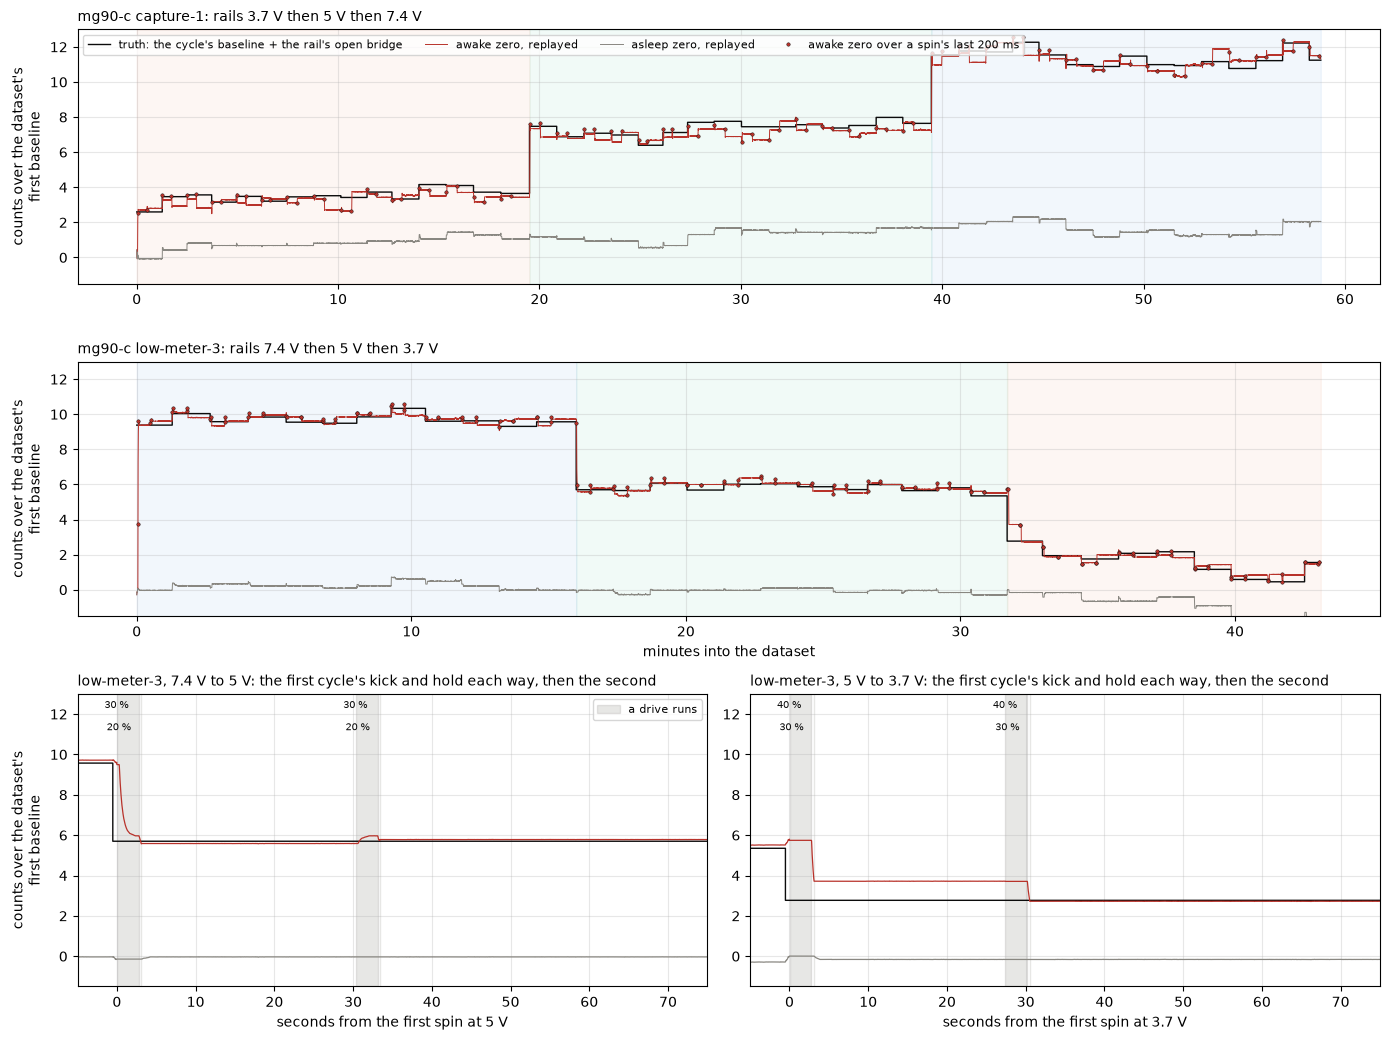

In [14]:
# the awake zero through two datasets' timelines against the per-rail truth, and low-meter-3's two rail steps up close
fig = plt.figure(figsize=(14, 10.5))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.15])
axes = [fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, :])]
for a, name in zip(axes, ("capture-1", "low-meter-3")):
    tr = TRACE[name]
    t_min = tr["t_s"] / 60
    for lv in LEVELS:
        g = tr[tr["level"] == lv]
        if len(g):
            a.fill_between(g["t_s"] / 60, -1.5, 13, color=RAIL_COLOR[lv], alpha=0.06, step="mid")
    a.step(t_min, tr["truth"], where="post", color=INK, lw=1.0, label="truth: the cycle's baseline + the rail's open bridge")
    a.plot(t_min, tr["awake"], color=RED, lw=0.7, label="awake zero, replayed")
    a.plot(t_min, tr["asleep"], color=MUTED, lw=0.7, label="asleep zero, replayed")
    sp = P[(P["name"] == name) & (P["motor"] == "mg90-c")]
    a.plot(sp["t_s"] / 60, sp["awake_200"] - sp["zero_i"].iloc[0], "o", ms=2.5, color=RED, mec=INK, mew=0.3, label="awake zero over a spin's last 200 ms")
    a.set_ylim(-1.5, 13); a.set_ylabel("counts over the dataset's\nfirst baseline"); a.grid(alpha=0.3)
    a.set_title(f"mg90-c {name}: rails {' then '.join(f'{lv:g} V' for lv in pd.unique(tr['level']))}", loc="left", fontsize=10)
axes[0].legend(fontsize=8, loc="upper left", ncol=4)
axes[1].set_xlabel("minutes into the dataset")
# the two rail steps of low-meter-3: from 5 s before the new rail's first spin to 75 s after, the drives shaded, each rung's duty on top
tr = TRACE["low-meter-3"]
sp = P[(P["name"] == "low-meter-3") & (P["motor"] == "mg90-c")]
for j, (lv_from, lv_to) in enumerate(((7.4, 5.0), (5.0, 3.7))):
    a = fig.add_subplot(gs[2, j])
    t0 = sp[sp["level"] == lv_to]["t_s"].iloc[0]
    g = tr[(tr["t_s"] >= t0 - 5) & (tr["t_s"] <= t0 + 75)]
    a.fill_between(g["t_s"] - t0, -1.5, 13, where=g["bridge"].to_numpy() == DRIVE, color=MUTED, alpha=0.2, step="mid", label="a drive runs")
    a.step(g["t_s"] - t0, g["truth"], where="post", color=INK, lw=1.0)
    a.plot(g["t_s"] - t0, g["awake"], color=RED, lw=0.9)
    a.plot(g["t_s"] - t0, g["asleep"], color=MUTED, lw=0.9)
    for _, r in sp[(sp["t_s"] >= t0 - 5) & (sp["t_s"] <= t0 + 75)].iterrows():
        kick = not r["is_hold"] and r["kick"] > 0
        a.annotate(f"{r['kick'] if kick else r['duty']} %", (r["t_s"] - t0, 12.3 if kick else 11.2), fontsize=7, ha="center", color=INK)
    a.set_xlim(-5, 75); a.set_ylim(-1.5, 13); a.grid(alpha=0.3); a.set_xlabel(f"seconds from the first spin at {lv_to:g} V")
    a.set_title(f"low-meter-3, {lv_from:g} V to {lv_to:g} V: the first cycle's kick and hold each way, then the second", loc="left", fontsize=10)
    if j == 0:
        a.set_ylabel("counts over the dataset's\nfirst baseline"); a.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

The replayed zeros through capture-1 (top) and low-meter-3 (middle), 50 Hz samples of the tick-exact run, the rail as the background tint and the truth as the black step: each cycle's own baseline plus the rail's open-bridge level. The gray trace is the asleep zero, which follows the baseline's wander, and the red one the awake zero, with its value over each spin's last 200 ms as dots. The thing to see is the awake zero jumping to the new rail's level inside the first cycle after a rail step when that cycle's rungs feed it (capture-1, at 15 %), and holding the old rail's level through a whole kick and hold when they do not. The bottom row is low-meter-3's two rail steps up close, the drives shaded and each rung's duty on top: at 7.4 to 5 V the 30 % kick runs 3.80 counts high until the 20 % hold learns the step, and at 5 to 3.7 V the 30 % kick and the 30 % hold feed nothing, so the first spin runs its whole 2.8 s at the old level and the coasts between the chains close the gap by about half each.

In [15]:
def summarize(DD, by):
    # rms and worst of the error per group at the first row and over the last 200 ms, in counts and rev/s, with the count past 0.5 rev/s
    rows = []
    for key, g in DD.groupby(by, sort=False):
        rows.append(dict(**dict(zip(by, key if isinstance(key, tuple) else (key,))), spins=len(g),
                         rms_start=np.sqrt((g["err_start"] ** 2).mean()), worst_start=g["err_start"].abs().max(),
                         rms_200=np.sqrt((g["err_200"] ** 2).mean()), worst_200=g["err_200"].abs().max(), mean_200=g["err_200"].mean(),
                         rms_200_rev_s=np.sqrt((g["err_200_rev_s"] ** 2).mean()), worst_200_rev_s=g["err_200_rev_s"].abs().max(),
                         over_half_200=int((g["err_200_rev_s"].abs() > 0.5).sum()), over_half_start=int((g["err_start"] * g["rpc"]).abs().gt(0.5).sum()),
                         rms_200_own=np.sqrt((g["err_200_own"] ** 2).mean())))
    return pd.DataFrame(rows)


W = P[~P["first_chain"]]                                                        # warm: the dataset's first chain left out
SUMW = summarize(W, ["motor", "name"])
SUMW.loc[len(SUMW)] = summarize(W.assign(motor="all", name="pooled"), ["motor", "name"]).iloc[0]
print("primary replay per dataset, warm (counts over the truth; start = the spin's first row, 200 = its last 200 ms)")
print(SUMW.round(2).to_string(index=False))
SUMALL = summarize(P.assign(motor="all", name="pooled"), ["motor", "name"]).iloc[0]
print(f"\nevery spin, the boot chains included: rms 200 {SUMALL['rms_200']:.2f}, worst {SUMALL['worst_200']:.2f}, rms start {SUMALL['rms_start']:.2f}, worst {SUMALL['worst_start']:.2f}")
# the sensitivity to the trough level fed and to the brake's length, pooled warm
SENS = summarize(Q2[~Q2["first_chain"]], ["mode", "brake_s"])
print("\nthe variants, pooled warm: mode m = the motor's trough, d = the dummy's trough, e = the dropout rows, b = the open bridge itself")
print(SENS.round(2).to_string(index=False))
# the feeding and the non-feeding rungs, warm: what each converges to
fe = W[W["feeds"] & (W["dur_s"] >= 1.0)]
FR = fe.groupby(["motor", "name", "level", "duty", "is_hold"])["err_end"].agg(["mean", "std", "size"])
print(f"\nfeeding rungs (<= 20 %, held >= 1 s), warm, per rung: the awake zero at the rung's end {FR['mean'].min():+.2f} to {FR['mean'].max():+.2f} counts over the truth, "
      f"sd across a rung's spins {FR['std'].min():.2f} to {FR['std'].max():.2f}; by rail " + ", ".join(f"{lv:g} V {g['err_end'].mean():+.2f}" for lv, g in fe.groupby("level")))
nf = W[~W["feeds"]]
NF = nf.groupby(["motor", "name"], sort=False)["err_200"].agg(["mean", "std", lambda x: x.abs().max()])
print("non-feeding rungs (> 20 %), warm, per dataset, mean / sd / worst counts: " + ", ".join(f"{m} {n} {r['mean']:+.2f} / {r['std']:.2f} / {r.iloc[2]:.2f}" for (m, n), r in NF.iterrows()))
bad = W[W["err_200_rev_s"].abs() > 0.5]
print(f"\nwarm spins past 0.5 rev/s over their last 200 ms ({len(bad)} of {len(W)}):")
print(bad[["motor", "name", "k", "level", "duty", "kick", "seg", "dir", "ticks", "feeds", "first_after_rail_change", "dur_s", "err_start", "err_200", "err_200_rev_s"]].round(2).to_string(index=False))
FC = P[P["first_chain"]]
print("\nthe first chain of each dataset, seeded at its baseline (the boot case):")
print(FC[["motor", "name", "level", "duty", "seg", "ticks", "feeds", "dur_s", "err_start", "err_end", "err_200", "err_200_rev_s"]].round(2).to_string(index=False))

primary replay per dataset, warm (counts over the truth; start = the spin's first row, 200 = its last 200 ms)
 motor        name  spins  rms_start  worst_start  rms_200  worst_200  mean_200  rms_200_rev_s  worst_200_rev_s  over_half_200  over_half_start  rms_200_own
mg90-c   capture-1     89       0.69         4.10     0.35       0.94     -0.05           0.18             0.50              0                2         0.59
mg90-c   capture-2     89       0.64         3.84     0.29       0.79     -0.05           0.16             0.42              0                2         0.61
mg90-c       low-1     82       0.54         4.10     0.35       2.44      0.12           0.19             1.29              1                2         0.58
mg90-c low-meter-3    130       0.64         3.80     0.55       3.80      0.22           0.29             2.01              3                4         0.82
mg90-b   capture-1     59       0.54         3.10     0.31       0.74     -0.04           0.17           

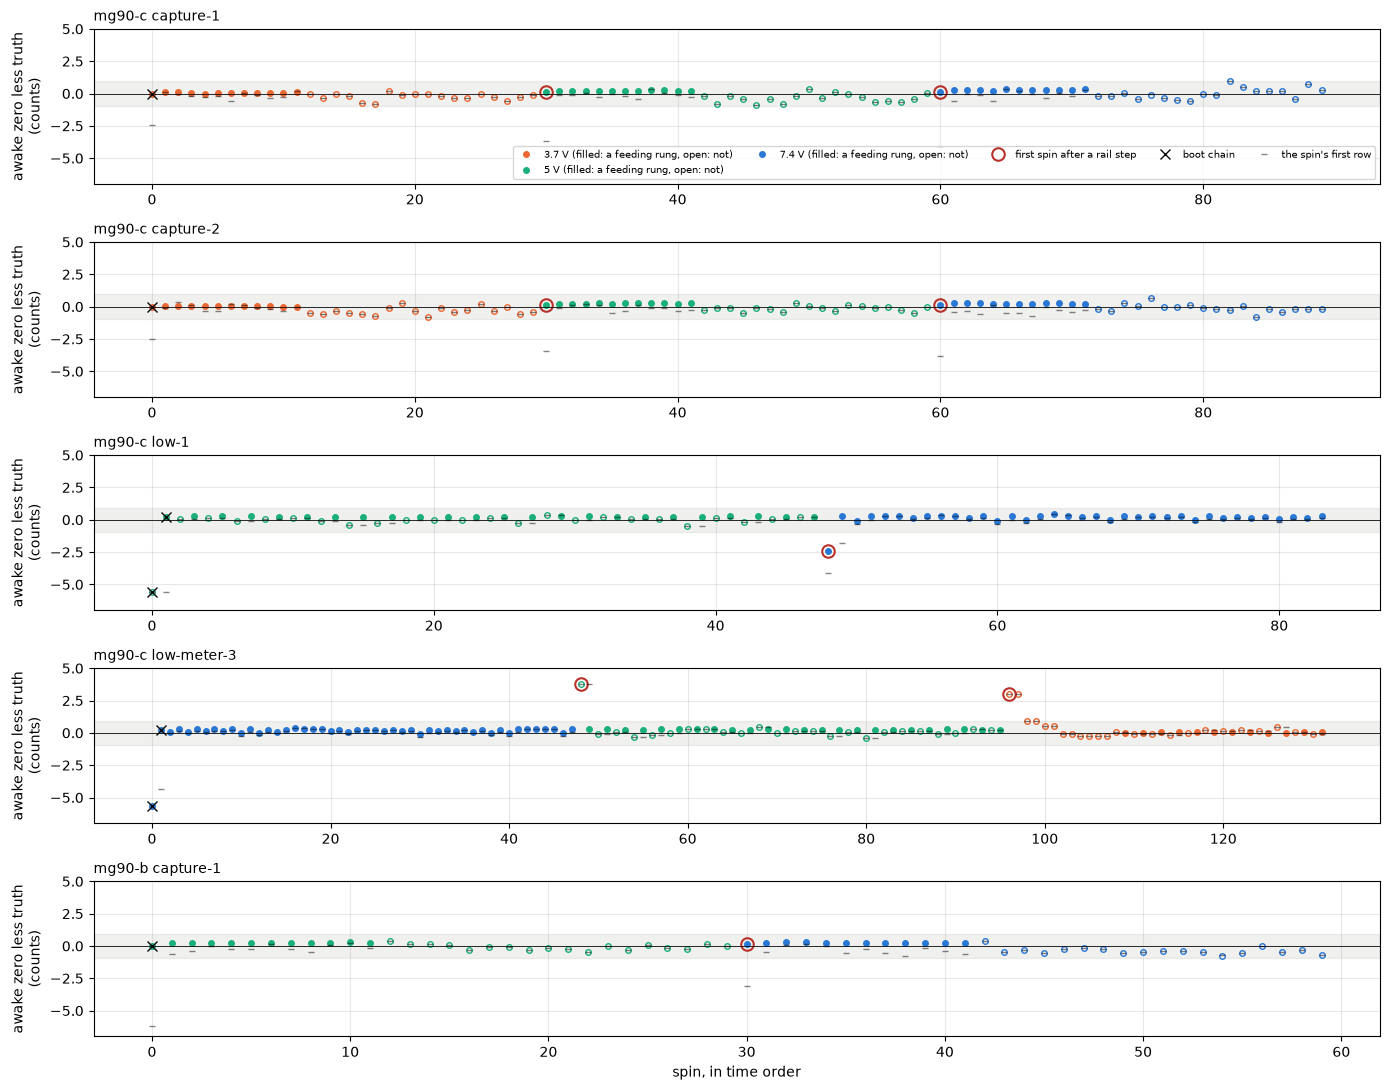

In [16]:
# every spin's error over its last 200 ms, by dataset: feeding rungs filled, non-feeding open, the first spin after a rail step ringed
fig, ax = plt.subplots(5, 1, figsize=(14, 11), sharex=False)
for a, (motor, name) in zip(ax, SIM):
    g = P[(P["motor"] == motor) & (P["name"] == name)].reset_index(drop=True)
    thr = 0.5 / g["rpc"].iloc[0]
    a.axhspan(-thr, thr, color=MUTED, alpha=0.12)
    for lv in LEVELS:
        h = g[g["level"] == lv]
        if not len(h):
            continue
        a.plot(h.index[h["feeds"]], h["err_200"][h["feeds"]], "o", ms=4, color=RAIL_COLOR[lv], label=f"{lv:g} V (filled: a feeding rung, open: not)")
        a.plot(h.index[~h["feeds"]], h["err_200"][~h["feeds"]], "o", ms=4, mfc="none", color=RAIL_COLOR[lv])
    rc = g[g["first_after_rail_change"]]
    a.plot(rc.index, rc["err_200"], "o", ms=9, mfc="none", mec=RED, mew=1.5, label="first spin after a rail step")
    fc = g[g["first_chain"]]
    a.plot(fc.index, fc["err_200"], "x", ms=7, color=INK, label="boot chain")
    a.plot(g.index, g["err_start"], "_", ms=5, color=INK, alpha=0.5, label="the spin's first row")
    a.axhline(0, color=INK, lw=0.6); a.grid(alpha=0.3)
    a.set_ylabel("awake zero less truth\n(counts)"); a.set_title(f"{motor} {name}", loc="left", fontsize=10)
    a.set_ylim(-7, 5)
ax[0].legend(fontsize=7, ncol=5, loc="lower right"); ax[-1].set_xlabel("spin, in time order")
plt.tight_layout(); plt.show()

Every spin of the primary replay, the awake zero less the truth over the spin's last 200 ms, in the rail's color, filled where the rung feeds the awake zero (20 % or under) and open where it does not, with the error at the spin's first row as a tick, the first spin after each rail step ringed in red, the boot chain crossed, and the 0.5 rev/s band in gray. The thing to see is where the dots leave the band: at the boot chains, at the rail steps, and nowhere else.

Replayed tick-exactly over the five datasets with the motor's trough level at the feeding widths, the tracker holds the awake zero within 0.41 counts rms (0.22 rev/s) over a spin's last 200 ms once warm, 0.93 at the first row with the boot chains in, and 0.55 rms over every spin. 4 of 449 warm spins exceed 0.5 rev/s over their last 200 ms, 11 at their first row, and every one is a rail step or a boot.

- A feeding rung converges within the spin to the trough level it is fed. At its end the awake zero sits $+0.02$ to $+0.31$ counts over the open-bridge truth, by rung, with a standard deviation of 0.06 or under across a rung's spins. That offset is the motor's trough excess in its own column, 0.12 to 0.35 by rail, and the frame offset of 0.32 comes on top of it on the real feed. Fed with the dummy's level instead it is $+0.45$ to $+0.79$, with the dropout rows' $+0.6$, with the open bridge zero. So a long hold is as good as the level it is fed, and that level is now measured.
- A non-feeding rung holds what the last coast or feeding rung left: per dataset a warm mean of $-0.22$ to $+0.28$ counts and a standard deviation of 0.20 to 0.83, worst 3.80.
- The first spin after a rail step. At 20 % or under (capture-1 and capture-2 at 5 and 7.4 V, mg90-b at 7.4 V) the first row reads $-3.1$ to $-4.1$ counts, 1.7 to 2.2 rev/s, and the spin learns the step inside itself, 97 % of it by 1.5 s, ending $+0.1$ to $+0.2$. With a 300 ms kick at 240 ticks then a hold at 96 (low-1, 5 to 7.4 V) the first row reads $-4.10$, the kick's last 200 ms $-2.44$ (1.3 rev/s), and the hold closes it. Above 20 % nothing feeds: low-meter-3's 7.4 to 5 V step under a 30 % kick carries 3.80 counts (2.0 rev/s) through the whole kick before the 20 % hold learns, and its 5 to 3.7 V step under a 30 % kick and a 30 % hold runs the whole first spin at 2.97 counts (1.6 rev/s) for 2.8 s. The same cycle's reverse spin, after one 0.3 s coast and a 20 ms brake, is back inside the budget: the error decays by the coasts alone, about half per 0.3 s coast.
- Boot, each dataset's first chain with the step unknown: the first row reads $-2.5$ counts at 3.7 V, $-5.6$ and $-6.2$ at 5 V and $-9.3$ at 7.4 V, 1.3 to 5.0 rev/s. low-1's 30 % kick carries $-5.62$ for its whole 300 ms. low-meter-3's 20 % kick feeds and closes to $-4.3$ by its end, and the hold finishes it.
- No stage 2 dataset reaches 3.3 V. From stage 1's rests a step from 3.7 V down to 3.3 V moves the asleep zero $-16.5$ counts, and a fresh awake zero follows only once stale or fed, so a drive within 3.3 s of such a step would read 14.5 mA (8.7 rev/s) high. The rule that a 1S rail under 3.7 V is ungraded stands.
- Sensitivity. With the brake at 1 s the motor-level replay reads 0.38 counts rms pooled warm, and the (b) replay, the open bridge itself as the trough, 0.31 with its worst 3.57 at the rail steps only. The dummy's level in place of the motor's raises the rms to 0.56, the dropout rows' to 0.52. Against each spin's own coast zero as the truth every rms rises by about 0.3 counts, the per-spin scatter.

## The tracker on its real feed

trough-4 replayed with every streamed row's own trough sample fed as the method feeds it: the baseline rows to the asleep zero, the coast rows to the awake zero after the settle, the drive rows to the awake zero when their window is at or under the gate, and nothing from a wider drive. The brake, the rests and the 5 ms pre-drive coast are synthesized as before, and the truth per spin is the chain's own late coast in the crest column, the zero a crest reading in that chain needs. The port runs once per gate candidate from boot, both zeros at the first baseline, and once more from a 5 V warm state for the first chain. The two rail steps, 7.4 to 5 V under a 30 % kick and 5 to 3.7 V under a 40 % kick and a 30 % hold, are reported apart, and the spins with those two chains out are the steady ones.

In [17]:
def build_real(recs, brake_s, rng):
    # the whole recording's per-tick bridge state, drive ticks and shunt samples: every streamed row's own trough sample, the unstreamed
    # stretches synthesized as in the modeled replay (the brake at the chain's own coast level in the trough column, the rests at the trough
    # baseline with the rest floor's noise, 5 ms of coast before a chain), each driven segment's row span and each cycle's
    bridge, ticks, samples, marks, spans = [], [], [], {}, []
    n_at = 0

    def push(b, tk, smp):
        nonlocal n_at
        n = len(smp)
        bridge.append(np.full(n, b, np.int8) if np.isscalar(b) else b)
        ticks.append(np.full(n, tk, np.int16) if np.isscalar(tk) else tk)
        samples.append(np.asarray(smp, np.int32))
        n_at += n

    def noise(level, sd, n):
        return np.floor(level + sd * rng.standard_normal(n) + 0.5).astype(np.int32)

    prev_end = np.nan
    for ci, r in enumerate(recs):
        S, n0 = r["segs"], n_at
        zero_rest = r["z_trough"] if ci == 0 else 0.5 * (r["z_trough"] + recs[ci - 1]["z_trough"])
        coast_levels = {s["seg"]: r["z_trough"] + s["coast_trough_late"] for s in S if s["cmd"] == 0 and s["seg"] > 0}
        n_gap = max(int(round((S[0]["t_start"] - prev_end) * FS)), 0) if np.isfinite(prev_end) else 2 * FS
        push(ASLEEP, 0, noise(zero_rest, NOISE_REST, n_gap))
        for i, s in enumerate(S):
            if i > 0:
                gap = max(int(round((s["t_start"] - S[i - 1]["t_end"]) * FS)), 0)
                own_coast = coast_levels[s["coast_seg"]] if "coast_seg" in s else coast_levels[max(coast_levels)]
                if S[i - 1]["cmd"] == 0 and S[i - 1]["seg"] > 0 and s["cmd"] != 0:
                    nb_, nc = int(round(brake_s * FS)), int(round(PRE_DRIVE_COAST_S * FS))
                    push(DRIVE, BRAKE_TICKS, noise(coast_levels[S[i - 1]["seg"]], NOISE_TROUGH, nb_))
                    push(ASLEEP, 0, noise(zero_rest, NOISE_REST, max(gap - nb_ - nc, 0)))
                    push(COAST, 0, noise(own_coast, NOISE_REST, nc))
                else:
                    push(COAST, 0, noise(own_coast, NOISE_REST, gap))
            marks[(r["k"], s["seg"])] = (n_at, n_at + s["n"])
            tk = s["ticks"].astype(np.int16)
            if s["seg"] == 0:
                push(ASLEEP, 0, s["trough"].astype(np.int32))                            # the baseline's own trough rows
            else:
                push(np.where(tk > 0, DRIVE, COAST).astype(np.int8), tk, s["trough"].astype(np.int32))   # the drive's and the coast's own trough rows
        nb_ = int(round(brake_s * FS))
        push(DRIVE, BRAKE_TICKS, noise(coast_levels[S[-1]["seg"]], NOISE_TROUGH, nb_))
        next_start = recs[ci + 1]["segs"][0]["t_start"] if ci + 1 < len(recs) else np.nan
        end = next_start - PRE_DRIVE_COAST_S if np.isfinite(next_start) else S[-1]["t_end"] + 2.0
        n_rest = max(int(round((end - S[-1]["t_end"]) * FS)) - nb_, 0)
        push(ASLEEP, 0, noise(zero_rest, NOISE_REST, n_rest))
        prev_end = S[-1]["t_end"] + (nb_ + n_rest) / FS
        spans.append((n0, n_at))
    return np.concatenate(bridge), np.concatenate(ticks), np.concatenate(samples), marks, spans


def simulate_real(gate, seed="boot", brake_s=BRAKE_POLL_S, rng_seed=1, trace_every=0):
    # the tracker through the recording with both samples on its real feed, under a gate in ticks; the truth per spin is the chain's own
    # late coast in the crest column (what a crest reading subtracts from); seed "boot" = both zeros at the first baseline, "warm-5V" = the
    # awake zero already at the 5 V open-bridge level, the state a 5 V bracket would leave
    recs = reduce_dataset(*REAL)
    rng = np.random.default_rng(rng_seed)
    bridge, ticks, samples, marks, spans = build_real(recs, brake_s, rng)
    kind = kinds_from_bridge(bridge, ticks, gate)
    del bridge, ticks
    t = Tracker()
    t.seed(round(recs[0]["z_trough"]))
    if seed == "warm-5V":
        five = np.mean([s["coast_trough_late"] for r in recs if r["level"] == 5.0 for s in r["segs"] if s["cmd"] == 0 and s["seg"] > 0])
        t.awake_q = np.int64(round((round(recs[0]["z_trough"]) + five) * (1 << FRAC)))
    first_chain = {(recs[0]["k"], s["seg"]) for s in recs[0]["segs"][:4]}
    rpc = rev_s_per_count("mg90-c")
    rows, trace, prev_level = [], [], None
    for r, (a0, a1) in zip(recs, spans):                                             # cycle by cycle, the state carried, one pass over the ticks
        aw, sl = t.run(kind[a0:a1], samples[a0:a1])
        aw, sl = q_to_float(aw), q_to_float(sl)
        if trace_every:
            idx = np.arange(0, len(aw), trace_every)
            trace.append(pd.DataFrame(dict(t_s=(a0 + idx) / FS, awake=aw[idx] - recs[0]["zero_i"], asleep=sl[idx] - recs[0]["zero_i"], level=r["level"], k=r["k"])))
        for i, s in enumerate(r["segs"]):
            if s["cmd"] == 0:
                continue
            a, b = marks[(r["k"], s["seg"])]
            a, b = a - a0, b - a0
            c = r["segs"][s["coast_seg"]]
            truth_c, truth_t = r["zero_i"] + c["coast_crest_late"], r["z_trough"] + c["coast_trough_late"]
            rows.append(dict(gate=gate, seed=seed, k=r["k"], level=r["level"], kind="hold" if r["segs"][i - 1]["cmd"] != 0 else "kick",
                             duty=s["ticks_settled"] * 100 / ARR, ticks=s["ticks_settled"], dir=s["dir"], seg=s["seg"],
                             feeds=s["ticks_settled"] <= gate, first_chain=(r["k"], s["seg"]) in first_chain,
                             rail_step_chain=r["k"] in RAIL_STEP_K and s["seg"] <= 3,
                             first_after_rail_change=prev_level is not None and prev_level != r["level"] and s["seg"] == 1,
                             n_feeds=int((kind[a0 + a:a0 + b] == K_AWAKE).sum()), t_s=(a0 + a) / FS, zero_i=r["zero_i"],
                             awake_start=aw[a], awake_200=aw[b - N200:b].mean(), asleep_start=sl[a], asleep_200=sl[b - N200:b].mean(),
                             truth_c=truth_c, truth_t=truth_t, err_start=aw[a] - truth_c, err_200=aw[b - N200:b].mean() - truth_c,
                             err_200_t=aw[b - N200:b].mean() - truth_t, rpc=rpc,
                             c_200=sl[b - N200:b].mean() + table(r["rail_rest"]) - truth_c))       # the comparison: the asleep zero + the table
        prev_level = r["level"]
    df = pd.DataFrame(rows)
    return (df, pd.concat(trace, ignore_index=True)) if trace_every else df


# the table the comparison reads from: mg90-c capture-1's open bridge per rail, linear between (the same table the methods section scores)
cal = {}
for r in reduce_dataset("mg90-c", "capture-1"):
    for s in r["segs"]:
        if s["cmd"] != 0 and "open_zero" in s:
            cal.setdefault(r["level"], []).append(s["open_zero"])
CAL_V = np.array(sorted(cal))
CAL_Z = np.array([np.mean(cal[v]) for v in CAL_V])


def table(v):
    return np.interp(v, CAL_V, CAL_Z)


RAIL_STEP_K = {12, 24}                     # the first cycle at 5 V (7.4 -> 5 V, a 30 % kick) and at 3.7 V (5 -> 3.7 V, a 40 % kick and a 30 % hold)
rframes, RTRACE = [], {}
for pct in GATES_PCT:
    if pct in (20, GATE_REC_PCT):
        d, RTRACE[pct] = simulate_real(gate_ticks(pct), trace_every=400)
    else:
        d = simulate_real(gate_ticks(pct))
    d["gate_pct"] = pct
    rframes.append(d)
RD = pd.concat(rframes, ignore_index=True)
R20 = RD[RD["gate_pct"] == 20]
RW5 = simulate_real(gate_ticks(20), seed="warm-5V")


def rscore(g):
    return dict(spins=len(g), rms_200=np.sqrt((g["err_200"] ** 2).mean()), worst_200=g["err_200"].abs().max(), mean_200=g["err_200"].mean(),
                          rms_200_rev_s=np.sqrt((g["err_200"] ** 2).mean()) * g["rpc"].iloc[0], worst_200_rev_s=g["err_200"].abs().max() * g["rpc"].iloc[0],
                          over_half_200=int((g["err_200"].abs() * g["rpc"] > 0.5).sum()), rms_start=np.sqrt((g["err_start"] ** 2).mean()),
                          worst_start=g["err_start"].abs().max(), mean_200_trough_col=g["err_200_t"].mean(),
                          C_rms_200=np.sqrt((g["c_200"] ** 2).mean()), C_worst_200=g["c_200"].abs().max())


rows = []
for pct, g in RD.groupby("gate_pct"):
    w = g[~g["first_chain"]]
    st = w[~w["rail_step_chain"]]
    for name, h in (("warm", w), ("steady", st)):
        for lv, hh in [("all", h)] + list(h.groupby("level")):
            rows.append(dict(gate_pct=pct, set=name, level=lv, **rscore(hh)))
RS = pd.DataFrame(rows)
RSW = RS[(RS["set"] == "warm") & (RS["level"] == "all")].set_index("gate_pct")
RSS = RS[(RS["set"] == "steady") & (RS["level"] == "all")].set_index("gate_pct")
print(f"the tracker on its real feed, {REAL[1]}, boot seed: the awake zero against the chain's own late coast (crest column), counts; warm = the first chain out, "
      "steady = the two rail-step chains out as well; C = the asleep zero (trough-fed) + capture-1's table, the comparison")
print(RS[RS["level"] == "all"].round(2).to_string(index=False))
print("\nper rail, warm")
print(RS[(RS["set"] == "warm") & (RS["level"] != "all")].round(2).to_string(index=False))
H74 = {pct: g[(g["level"] == 7.4) & (g["kind"] == "hold")]["err_200"] for pct, g in RD[~RD["first_chain"] & ~RD["rail_step_chain"]].groupby("gate_pct")}
print("\nthe 7.4 V holds, steady, per gate: mean / over 0.5 rev/s of 23: " + ", ".join(f"{p} % {h.mean():+.2f} / {int((h.abs() * RPC > 0.5).sum())}" for p, h in H74.items()))
RC = RD[RD["k"].isin(RAIL_STEP_K) & (RD["seg"] <= 2)]
print("\nthe first chain after each rail step, per gate: the kick and the hold, counts at the first row and over the last 200 ms")
print(RC[["gate_pct", "k", "level", "kind", "duty", "feeds", "n_feeds", "err_start", "err_200"]].assign(err_200_rev_s=lambda d: d["err_200"] * RPC).round(2).to_string(index=False))
FCR = pd.concat([R20[R20["first_chain"]].assign(seed="boot"), RW5[RW5["first_chain"]]])
print("\nthe first chain (7.4 V, a 20 % kick then a 20 % hold, both feeding at every gate) from boot and from a 5 V warm state, gate 20 %")
print(FCR[["seed", "kind", "duty", "n_feeds", "err_start", "err_200"]].assign(err_start_rev_s=lambda d: d["err_start"] * RPC).round(2).to_string(index=False))
RUNG_R = R20[~R20["first_chain"]].groupby(["level", "kind", "duty"]).agg(n=("k", "count"), feeds=("feeds", "first"), err_200=("err_200", "mean"), sd=("err_200", "std"),
                                                                        err_200_trough_col=("err_200_t", "mean"), worst=("err_200", lambda x: x.abs().max())).reset_index()
print("\nper rung, warm, gate 20 %: the awake zero over the chain's late coast at the segment's last 200 ms, crest column and trough column")
print(RUNG_R.round(2).to_string(index=False))
steady20 = R20[~R20["first_chain"] & ~R20["rail_step_chain"]]
print(f"\nsteady spins over 0.5 rev/s at gate 20 %: {int((steady20['err_200'].abs() * RPC > 0.5).sum())} of {len(steady20)}, "
      f"{steady20[steady20['err_200'].abs() * RPC > 0.5]['err_200'].abs().min():.2f} to {steady20['err_200'].abs().max():.2f} counts, "
      f"{int((steady20[steady20['err_200'].abs() * RPC > 0.5]['kind'] == 'hold').sum())} holds; the steady mean {RSS.loc[20, 'mean_200']:+.2f} of which "
      f"{FRAME_AWAKE['mean']:+.2f} is the frame offset and {RSS.loc[20, 'mean_200_trough_col']:+.2f} the trough's own excess in its column")

the tracker on its real feed, trough-4, boot seed: the awake zero against the chain's own late coast (crest column), counts; warm = the first chain out, steady = the two rail-step chains out as well; C = the asleep zero (trough-fed) + capture-1's table, the comparison
 gate_pct    set level  spins  rms_200  worst_200  mean_200  rms_200_rev_s  worst_200_rev_s  over_half_200  rms_start  worst_start  mean_200_trough_col  C_rms_200  C_worst_200
       20   warm   all    142     0.82       4.10      0.49           0.43             2.17             18       0.87         4.10                 0.17       0.56         1.42
       20 steady   all    138     0.60       1.49      0.41           0.32             0.79             15       0.57         1.49                 0.09       0.56         1.42
       30   warm   all    142     0.74       3.91      0.53           0.39             2.07             20       0.84         4.10                 0.21       0.56         1.42
       30 steady   all    1

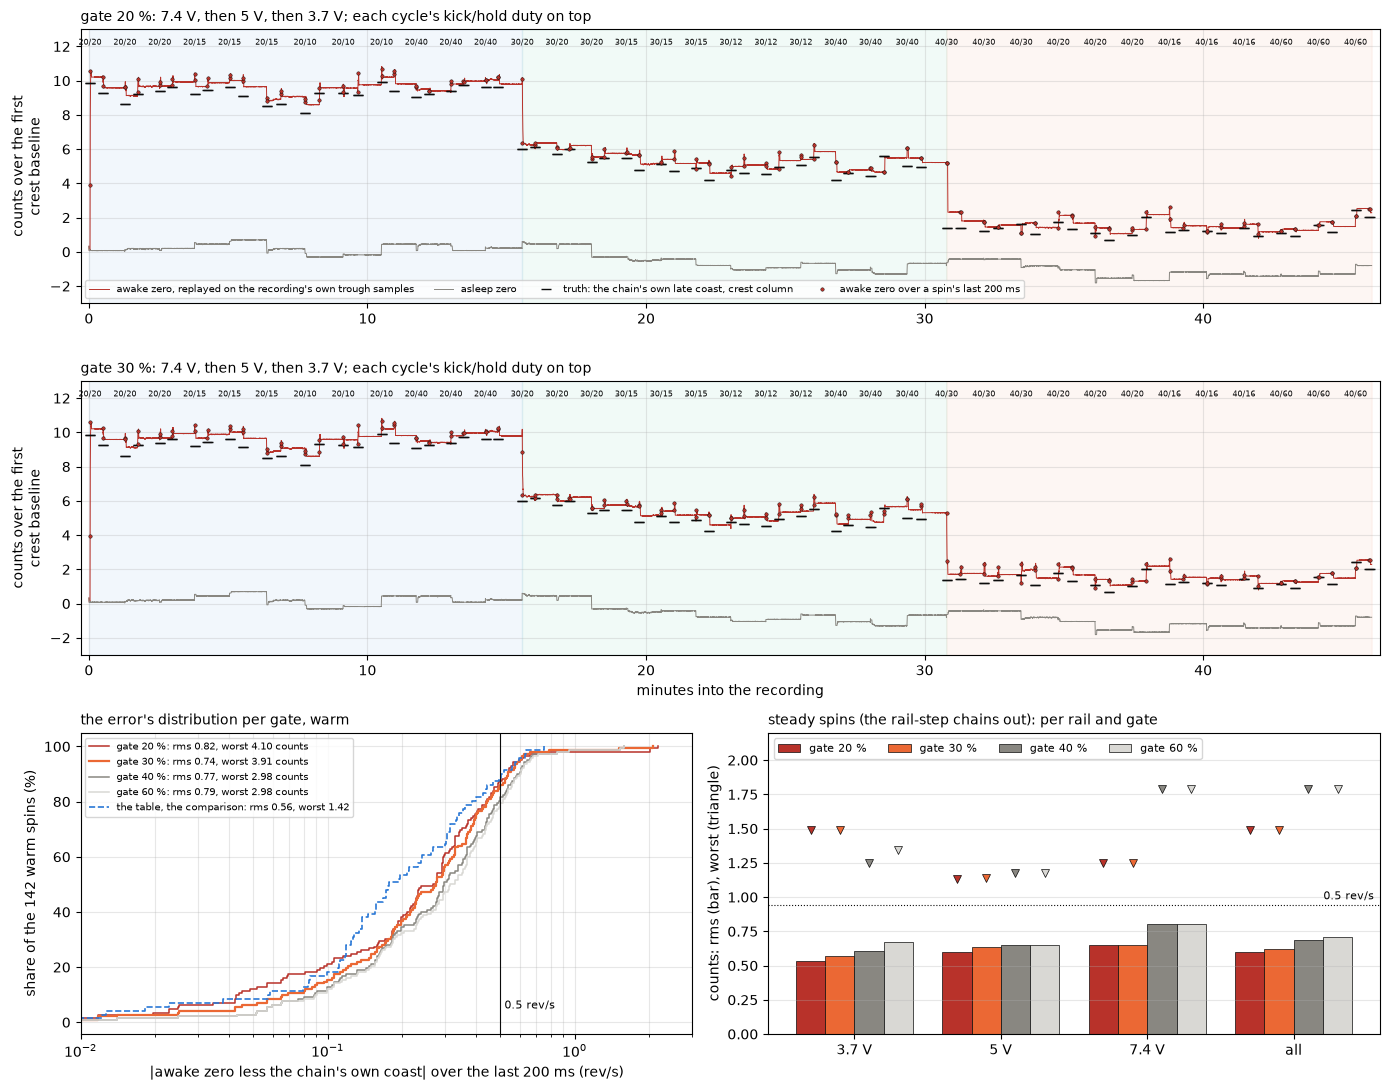

In [18]:
# the real feed: the awake zero through the recording under the gate as first specified and under the recommended one, then every gate scored
fig = plt.figure(figsize=(14, 11))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.1])
zi0 = reduce_dataset(*REAL)[0]["zero_i"]
for row, pct in enumerate((20, GATE_REC_PCT)):
    a = fig.add_subplot(gs[row, :])
    tr = RTRACE[pct]
    g = RD[RD["gate_pct"] == pct]
    for lv in LEVELS:
        h = tr[tr["level"] == lv]
        a.fill_between(h["t_s"] / 60, -3, 13, color=RAIL_COLOR[lv], alpha=0.06, step="mid")
    a.plot(tr["t_s"] / 60, tr["awake"], color=RED, lw=0.7, label="awake zero, replayed on the recording's own trough samples")
    a.plot(tr["t_s"] / 60, tr["asleep"], color=MUTED, lw=0.7, label="asleep zero")
    a.plot(g["t_s"] / 60, g["truth_c"] - zi0, "_", ms=7, color=INK, label="truth: the chain's own late coast, crest column")
    a.plot(g["t_s"] / 60, g["awake_200"] - zi0, "o", ms=2.5, color=RED, mec=INK, mew=0.3, label="awake zero over a spin's last 200 ms")
    for _, r in g[g["kind"] == "kick"].drop_duplicates("k").iterrows():
        a.annotate(f"{r['duty']:.0f}/{g[(g['k'] == r['k']) & (g['kind'] == 'hold')]['duty'].iloc[0]:.0f}", (r["t_s"] / 60, 12.1), fontsize=6, ha="center", color=INK)
    a.set_ylim(-3, 13); a.set_xlim(-0.3, tr["t_s"].max() / 60 + 0.3); a.grid(alpha=0.3); a.set_ylabel("counts over the first\ncrest baseline")
    a.set_title(f"gate {pct} %: 7.4 V, then 5 V, then 3.7 V; each cycle's kick/hold duty on top", loc="left", fontsize=10)
    if row == 0:
        a.legend(fontsize=7, loc="lower left", ncol=4)
    else:
        a.set_xlabel("minutes into the recording")
# the gates scored: the distribution of the warm errors per gate with the table beside, and per-rail rms and worst on the steady spins
a = fig.add_subplot(gs[2, 0])
GCOL = {20: RED, 30: ORANGE, 40: MUTED, 60: "#d9d8d4"}
for pct in GATES_PCT:
    w = RD[(RD["gate_pct"] == pct) & ~RD["first_chain"]]
    e = np.sort((w["err_200"].abs() * RPC).to_numpy())
    a.step(e, np.arange(1, len(e) + 1) / len(e) * 100, where="post", color=GCOL[pct], lw=1.6 if pct == GATE_REC_PCT else 1.1, label=f"gate {pct} %: rms {RSW.loc[pct, 'rms_200']:.2f}, worst {RSW.loc[pct, 'worst_200']:.2f} counts")
w = R20[~R20["first_chain"]]
e = np.sort((w["c_200"].abs() * RPC).to_numpy())
a.step(e, np.arange(1, len(e) + 1) / len(e) * 100, where="post", color=BLUE, lw=1.2, ls="--", label=f"the table, the comparison: rms {RSW.loc[20, 'C_rms_200']:.2f}, worst {RSW.loc[20, 'C_worst_200']:.2f}")
a.axvline(0.5, color=INK, lw=0.8); a.text(0.52, 5, "0.5 rev/s", fontsize=8)
a.set_xscale("log"); a.set_xlim(0.01, 3); a.set_xlabel("|awake zero less the chain's own coast| over the last 200 ms (rev/s)"); a.set_ylabel("share of the 142 warm spins (%)")
a.set_title("the error's distribution per gate, warm", loc="left", fontsize=10); a.grid(alpha=0.3, which="both"); a.legend(fontsize=7, loc="upper left")
a = fig.add_subplot(gs[2, 1])
x = np.arange(4)
for j, pct in enumerate(GATES_PCT):
    s = RS[(RS["gate_pct"] == pct) & (RS["set"] == "steady")].set_index("level")
    vals = [s.loc[lv, "rms_200"] for lv in LEVELS] + [s.loc["all", "rms_200"]]
    a.bar(x + (j - 1.5) * 0.2, vals, 0.2, color=GCOL[pct], edgecolor=INK, lw=0.5, label=f"gate {pct} %")
    a.plot(x + (j - 1.5) * 0.2, [s.loc[lv, "worst_200"] for lv in LEVELS] + [s.loc["all", "worst_200"]], "v", color=GCOL[pct], mec=INK, mew=0.5, ms=6)
a.axhline(0.5 / RPC, color=INK, lw=0.8, ls=":"); a.text(3.55, 0.5 / RPC + 0.04, "0.5 rev/s", fontsize=8, ha="right")
a.set_xticks(x, [f"{lv:g} V" for lv in LEVELS] + ["all"]); a.set_ylabel("counts: rms (bar), worst (triangle)"); a.set_ylim(0, 2.2)
a.set_title("steady spins (the rail-step chains out): per rail and gate", loc="left", fontsize=10); a.grid(alpha=0.3, axis="y"); a.legend(fontsize=8, ncol=4, loc="upper left")
plt.tight_layout(); plt.show()

Top and middle, the awake zero through the recording under the 20 % gate and under the 30 % one, the chain's own late coast as the black ticks and the awake zero over each spin's last 200 ms as dots, each cycle's kick and hold duty on top. Bottom left, the share of the warm spins under each error size per gate, with the table beside as the comparison. Bottom right, the rms and the worst spin per rail on the steady spins, the rail-step chains out, per gate.

On its real feed the tracker holds the awake zero to 0.82 counts rms warm under the 20 % gate (0.43 rev/s), worst 4.10 on the first spin after the 7.4 to 5 V step, a 30 % kick that feeds nothing, 2.2 rev/s for its 300 ms. On the steady spins it reads 0.60 rms, worst 1.49, with a mean of $+0.41$ counts of which $+0.32$ is the frame offset, the trough sample above the crest sample with the bridge open, and $+0.09$ the trough's own excess in its column averaged over feeding and non-feeding spins; the 0.43 counts of scatter about the mean is the per-chain scatter of the coast itself, which any method carries. 15 of 138 steady spins pass 0.5 rev/s, at 0.95 to 1.49 counts, 7 holds and 8 kicks, the mean plus that scatter. Against the modeled replay the rms is higher by the frame offset, which a replay feeding the crest sample could not see, and by a recording whose chains are 60 % feeding or rail-step; the worst case is the same mechanism and the same size.

The gates on the real feed. At 30 % the 5 V kick feeds, 4.10 to 2.85 counts by its end, and the 3.7 V 30 % hold feeds, 3.82 to 1.10, so the warm rms falls to 0.74 and the worst to 3.91, the 3.7 V 40 % kick that still feeds nothing; the steady spins read 0.62 rms, worst 1.49, mean $+0.48$. At 40 % the kicks feed too, warm 0.77 and worst 2.98, but the 7.4 V 40 % holds now feed at 1.06 counts over the open bridge and the 7.4 V holds' steady mean rises from $+0.61$ to $+0.84$, 9 of 23 over 0.5 rev/s against 4; 60 % changes nothing more, since nothing between 40 and 60 % was recorded but at 3.7 V. The rail-step gain of a wider gate and its steady cost cross between 30 and 40 %, where the trough's own level said they would. 30 % is the gate this result recommends.

Boot and the table. From boot the first chain's 20 % kick at 7.4 V opens 9.59 counts low, 5.1 rev/s, feeds through its 300 ms to 5.92 low, and the 2 s hold closes it to $+0.74$; from a 5 V warm state it opens 3.78 low, 2.0 rev/s. The asleep zero plus capture-1's table reads 0.56 rms and 1.42 worst here against 0.24 and 0.72 on the modeled replay: $+0.175$ of the frame offset, since the asleep zero is trough-fed now, and the 7.4 V table point standing 0.51 above this recording's late coast, 0.26 of it the early window and 0.25 the day. On this recording the table and the tracker tie in steady rms, 0.56 against 0.60, and the table keeps the worst case, 1.42 against 4.10. High confidence in the replay, every streamed row real; moderate in the gate ranking, one recording and six spins per rung.

## Convergence and rail steps

How many seconds of feed a step of the measured size takes on the exact port, what each kind of segment closes, and what a 2S pack's sag during a hold above 20 % would move the true zero by, where nothing feeds.

settling within 0.5 counts under continuous feed, tau 0.410 s
         step  counts    ma  rev_s  settle_s_exact  settle_s_analytic  left_after_0p8s_counts
   3.7 -> 5 V    3.35  2.95   1.77            0.82               0.78                    0.47
   5 -> 7.4 V    3.55  3.13   1.88            0.85               0.80                    0.50
 3.7 -> 7.4 V    6.90  6.08   3.65            1.13               1.07                    0.98
 7.4 -> 3.7 V   -6.90 -6.08  -3.65            1.03               1.07                   -0.98
boot at 3.7 V    2.53  2.23   1.34            0.71               0.66                    0.36
  boot at 5 V    5.88  5.18   3.12            1.06               1.01                    0.83
boot at 7.4 V    9.43  8.31   5.00            1.25               1.20                    1.34

the fraction of a step one segment's feed closes
                          segment  seconds  fraction_closed  left_of_3p55_counts
        coast 0.3 s (low-meter-3)     0.30            0

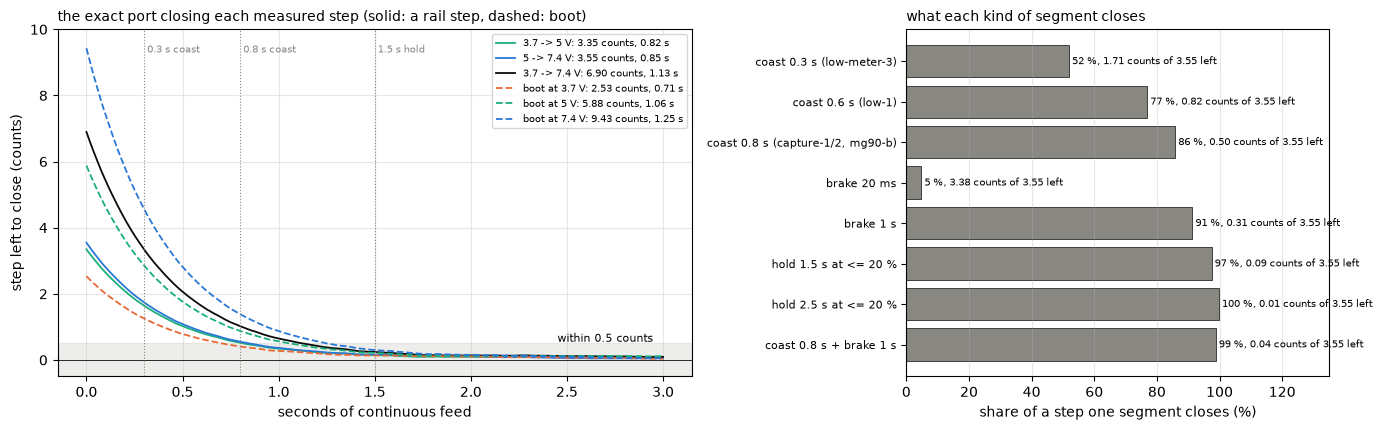

In [19]:
def settle_ticks(step_counts, within=0.5, base=1206):
    # ticks of continuous feed until the port sits within `within` counts of a target `step` away; integer samples whose
    # mean is the target (the rest floor's dither), the input the board has
    t = Tracker(); t.seed(base)
    target, n = base + step_counts, int(20 * FS)
    rng = np.random.default_rng(0)
    smp = np.floor(target + 1.08 * rng.standard_normal(n) + 0.5).astype(np.int64)
    a_, _ = t.run(np.full(n, K_AWAKE, np.int8), smp)
    err = np.abs(q_to_float(a_) - target)
    bad = np.flatnonzero(err > within)
    return (int(bad[-1] + 1) if len(bad) else 0), q_to_float(a_) - target


RPC = rev_s_per_count("mg90-c")
oc_ = {lv: LEV[lv]["open_c"] for lv in LEVELS}
STEPS = {"3.7 -> 5 V": oc_[5.0] - oc_[3.7], "5 -> 7.4 V": oc_[7.4] - oc_[5.0], "3.7 -> 7.4 V": oc_[7.4] - oc_[3.7], "7.4 -> 3.7 V": oc_[3.7] - oc_[7.4],
         "boot at 3.7 V": oc_[3.7], "boot at 5 V": oc_[5.0], "boot at 7.4 V": oc_[7.4]}
rows, CURVES = [], {}
for k, s in STEPS.items():
    n, CURVES[k] = settle_ticks(s)
    rows.append(dict(step=k, counts=s, ma=s * MA_PER_COUNT, rev_s=s * RPC, settle_s_exact=n / FS,
                     settle_s_analytic=np.log(0.5 / abs(s)) / np.log(1 - 2 ** -ALPHA_SHIFT) / FS, left_after_0p8s_counts=s * np.exp(-0.8 / TAU_S)))
SETTLE = pd.DataFrame(rows)
FEEDS = {"coast 0.3 s (low-meter-3)": 0.3, "coast 0.6 s (low-1)": 0.6, "coast 0.8 s (capture-1/2, mg90-b)": 0.8, "brake 20 ms": 0.02, "brake 1 s": 1.0,
         "hold 1.5 s at <= 20 %": 1.5, "hold 2.5 s at <= 20 %": 2.5, "coast 0.8 s + brake 1 s": 1.8}
FRAC_CLOSED = pd.DataFrame([dict(segment=k, seconds=v, fraction_closed=1 - np.exp(-v / TAU_S), left_of_3p55_counts=3.55 * np.exp(-v / TAU_S)) for k, v in FEEDS.items()])
# a 2S pack sagging 8.4 -> 7.0 V during a hold above 20 %: the true zero's move by each shape, 1 V past the data
shapes = {"line": lambda v: F["a"] + F["b"] * v, "quadratic": lambda v: np.polyval(F["quad"], v), "through the origin": lambda v: F["b_origin"] * v}
SAG = pd.DataFrame([dict(shape=k, zero_8p4=fn(8.4), zero_7p0=fn(7.0), move_counts=fn(7.0) - fn(8.4), move_ma=(fn(7.0) - fn(8.4)) * MA_PER_COUNT,
                         move_rev_s=(fn(7.0) - fn(8.4)) * RPC, zero_7p4_fit=fn(7.4)) for k, fn in shapes.items()])
# an unseeded tracker, both zeros from 0 under a rest at 1206: the cost if the boot seed were missing
t = Tracker(); n = int(6 * FS)
a_, _ = t.run(np.full(n, K_ASLEEP, np.int8), np.full(n, 1206))
COLD = {s: float(1206 - q_to_float(a_)[int(s * FS) - 1]) for s in (0.1, 0.41, 1, 2, 3, 5)}
print(f"settling within 0.5 counts under continuous feed, tau {TAU_S:.3f} s")
print(SETTLE.round(2).to_string(index=False))
print("\nthe fraction of a step one segment's feed closes")
print(FRAC_CLOSED.round(3).to_string(index=False))
print("\na 2S sag 8.4 -> 7.0 V with nothing feeding, mg90-c's shapes extrapolated 1 V past the data (measured at 7.4 V: %.2f counts)" % oc_[7.4])
print(SAG.round(2).to_string(index=False))
print("\nan unseeded tracker, counts short of the rest after " + ", ".join(f"{k} s: {v:.0f}" for k, v in COLD.items()))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [3, 2]})
a = ax[0]
tt = np.arange(int(3 * FS)) / FS
for k, col in (("3.7 -> 5 V", GREEN), ("5 -> 7.4 V", BLUE), ("3.7 -> 7.4 V", INK), ("boot at 3.7 V", ORANGE), ("boot at 5 V", GREEN), ("boot at 7.4 V", BLUE)):
    ls = "--" if k.startswith("boot") else "-"
    a.plot(tt, -CURVES[k][:len(tt)], ls, color=col, lw=1.3, label=f"{k}: {STEPS[k]:.2f} counts, {SETTLE.set_index('step').loc[k, 'settle_s_exact']:.2f} s")
a.axhspan(-0.5, 0.5, color=MUTED, alpha=0.15); a.text(2.95, 0.55, "within 0.5 counts", fontsize=8, ha="right")
a.axhline(0, color=INK, lw=0.6)
for s_ in (0.3, 0.8, 1.5):
    a.axvline(s_, color=MUTED, lw=0.8, ls=":")
a.text(0.3, 9.3, " 0.3 s coast", fontsize=7, color=MUTED); a.text(0.8, 9.3, " 0.8 s coast", fontsize=7, color=MUTED); a.text(1.5, 9.3, " 1.5 s hold", fontsize=7, color=MUTED)
a.set_xlabel("seconds of continuous feed"); a.set_ylabel("step left to close (counts)"); a.set_ylim(-0.5, 10)
a.set_title("the exact port closing each measured step (solid: a rail step, dashed: boot)", loc="left", fontsize=10); a.grid(alpha=0.3); a.legend(fontsize=7)
a = ax[1]
y = np.arange(len(FRAC_CLOSED))
a.barh(y, FRAC_CLOSED["fraction_closed"] * 100, color=MUTED, edgecolor=INK, lw=0.5)
for yi, (fr, left) in enumerate(zip(FRAC_CLOSED["fraction_closed"], FRAC_CLOSED["left_of_3p55_counts"])):
    a.text(min(fr * 100 + 1, 101), yi, f"{fr * 100:.0f} %, {left:.2f} counts of 3.55 left", va="center", fontsize=7)
a.set_yticks(y, FRAC_CLOSED["segment"], fontsize=8); a.invert_yaxis(); a.set_xlim(0, 135); a.set_xlabel("share of a step one segment closes (%)")
a.set_title("what each kind of segment closes", loc="left", fontsize=10); a.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()

Left, the exact port fed continuously with dithered integer samples, the step left to close against seconds of feed for each rail step the data measured (solid) and each boot case (dashed), the 0.5 count band in gray and the lengths of the segments the datasets offer as dotted lines. Right, the share of a step each kind of segment closes, with what it leaves of the 3.55 count step from 5 to 7.4 V.

With the exact port and dithered integer input a step settles within 0.5 counts after 0.82 s of feed for 3.7 to 5 V (3.35 counts), 0.85 s for 5 to 7.4 V (3.55), 1.1 s for 3.7 to 7.4 V either way (6.9), and 0.71, 1.06 and 1.25 s from boot at 3.7, 5 and 7.4 V. The analytic exponential agrees within 0.05 s. A 0.3 s coast closes 52 % of a step, 0.6 s 77 %, 0.8 s 86 %, a 20 ms brake 5 %, a 1 s brake 91 %, a 1.5 s hold at 20 % or under 97 % and a 2.5 s hold 99.8 %. A 0.8 s coast leaves 0.5 counts (0.27 rev/s) of the 3.55 count step. A 2S pack sagging from 8.4 to 7.0 V during a hold above 20 % moves the true zero by $-2.49$ counts on the line ($-2.2$ mA, $-1.3$ rev/s), $-0.80$ on the quadratic ($-0.4$ rev/s) and $-1.66$ on the proportional slope. The data end at 7.4 V and the two shapes disagree by three times one volt beyond it, so the size is low confidence, somewhere between 0.4 and 1.3 rev/s, and nothing in the tracker follows it until a feed. An aside: a tracker with no boot seed, both zeros from 0, would read 443 counts short of the rest 0.41 s after boot, 105 at 1 s, 9 at 2 s and 0 at 5 s, the cost if the rest measurement were ever missing.

## The table and the rail term on the same replay

The per-spin records of the primary replay scored three ways, the tracker beside its two comparisons. The calibration table of method C is mg90-c capture-1's own per-rail open-bridge mean, read once and applied to every dataset and both motors by the live rail, so capture-2, low-1, low-meter-3 and mg90-b are held out of it.

In [20]:
SLOPE, LINE = F["b"], F


def methods(G):
    # each candidate's error per spin at the first row and over the last 200 ms; the table is the one the real-feed section defined
    G = G.copy()
    for when in ("200", "start"):
        aw, sl, re = G[f"awake_{when}"], G[f"asleep_{when}"], G[f"rail_ewma_{when}"]
        G[f"A_{when}"] = aw - G["truth"]                                                               # the tracker as is
        G[f"B0_{when}"] = aw + SLOPE * (G["rail_spin"] - G["rail_last_feed"]) - G["truth"]              # + slope x (rail now - rail at the last fed tick)
        G[f"B_{when}"] = aw + SLOPE * (G["rail_spin"] - re) - G["truth"]                                # + slope x (rail now - the rail EWMA)
        G[f"C_{when}"] = sl + table(G["rail_spin"]) - G["truth"]                                        # asleep zero + the table by the live rail
        G[f"Cline_{when}"] = sl + LINE["a"] + LINE["b"] * G["rail_spin"] - G["truth"]                   # asleep zero + the line
    return G


def score(e, rpc):
    return dict(rms=np.sqrt((e ** 2).mean()), worst=e.abs().max(), mean=e.mean(), rms_rev_s=np.sqrt(((e * rpc) ** 2).mean()),
                worst_rev_s=(e * rpc).abs().max(), over_half=int(((e * rpc).abs() > 0.5).sum()), n=len(e))


METHODS = ("A", "B0", "B", "C", "Cline")
PM = methods(P)
rows = []
for warm in (False, True):
    PP = PM[~PM["first_chain"]] if warm else PM
    for (m, n), g in list(PP.groupby(["motor", "name"], sort=False)) + [(("all", "pooled"), PP)]:
        for meth in METHODS:
            for when in ("200", "start"):
                rows.append(dict(warm=warm, motor=m, name=n, method=meth, when=when, **score(g[f"{meth}_{when}"], g["rpc"])))
SC = pd.DataFrame(rows)
print(f"the table from mg90-c capture-1: " + ", ".join(f"{v:.1f} V {z:.2f}" for v, z in zip(CAL_V, CAL_Z)) + f" counts; the slope {SLOPE:.3f} counts/V")
print("\npooled over the five datasets")
print(SC[SC["motor"] == "all"].round(2).to_string(index=False))
print("\nper dataset, warm, the last 200 ms: rms / worst counts")
piv = SC[SC["warm"] & (SC["when"] == "200") & (SC["motor"] != "all")].pivot(index=["motor", "name"], columns="method", values=["rms", "worst"])
print(piv.round(2).to_string())
rc = PM[PM["first_after_rail_change"]]
print("\nthe first spin after each rail step, counts at the first row and over the last 200 ms")
print(rc[["motor", "name", "k", "level", "duty", "ticks", "feeds", "rail_spin", "rail_last_feed", "rail_ewma_start", "A_start", "B0_start", "B_start", "C_start", "A_200", "B0_200", "B_200", "C_200"]].round(2).to_string(index=False))
nfw = PM[~PM["feeds"] & ~PM["first_chain"]]
bterm = SLOPE * (nfw["rail_spin"] - nfw["rail_ewma_200"])
print(f"\nB's term on the warm non-feeding spins: mean {bterm.mean():+.3f} counts, largest {bterm.abs().max():.3f} (n {len(nfw)}); "
      f"B0's term there: largest {(SLOPE * (nfw['rail_spin'] - nfw['rail_last_feed'])).abs().max():.3f}")

the table from mg90-c capture-1: 3.7 V 2.59, 5.0 V 6.01, 7.4 V 9.66 counts; the slope 1.781 counts/V

pooled over the five datasets
 warm motor   name method  when  rms  worst  mean  rms_rev_s  worst_rev_s  over_half   n
False   all pooled      A   200 0.55   5.64  0.04       0.29         2.99          6 456
False   all pooled      A start 0.93   9.28 -0.17       0.49         4.92         18 456
False   all pooled     B0   200 0.56   5.72 -0.03       0.30         3.03          7 456
False   all pooled     B0 start 0.94   9.35 -0.23       0.50         4.95         19 456
False   all pooled      B   200 0.48   5.72 -0.03       0.26         3.03          3 456
False   all pooled      B start 0.77   9.35 -0.21       0.41         4.95         11 456
False   all pooled      C   200 0.24   0.72 -0.01       0.13         0.39          0 456
False   all pooled      C start 0.24   0.72 -0.01       0.13         0.39          0 456
False   all pooled  Cline   200 0.52   1.29 -0.16       0.28       

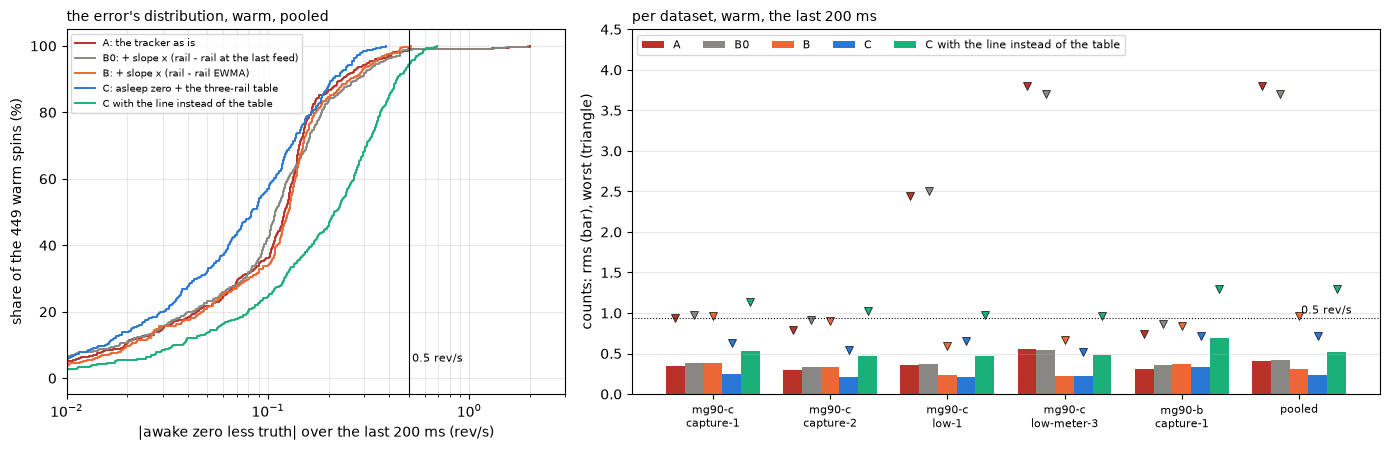

In [21]:
# the three methods: the distribution of every spin's error, and the per-dataset rms and worst
MCOL = {"A": RED, "B0": MUTED, "B": ORANGE, "C": BLUE, "Cline": GREEN}
MLAB = {"A": "A: the tracker as is", "B0": "B0: + slope x (rail - rail at the last feed)", "B": "B: + slope x (rail - rail EWMA)",
        "C": "C: asleep zero + the three-rail table", "Cline": "C with the line instead of the table"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2, 3]})
a = ax[0]
WM = PM[~PM["first_chain"]]
for meth in METHODS:
    e = np.sort((WM[f"{meth}_200"] * WM["rpc"]).abs().to_numpy())
    a.step(e, np.arange(1, len(e) + 1) / len(e) * 100, where="post", color=MCOL[meth], lw=1.4, label=MLAB[meth])
a.axvline(0.5, color=INK, lw=0.8); a.text(0.52, 5, "0.5 rev/s", fontsize=8)
a.set_xscale("log"); a.set_xlim(0.01, 3); a.set_xlabel("|awake zero less truth| over the last 200 ms (rev/s)"); a.set_ylabel("share of the 449 warm spins (%)")
a.set_title("the error's distribution, warm, pooled", loc="left", fontsize=10); a.grid(alpha=0.3, which="both"); a.legend(fontsize=7, loc="upper left")
a = ax[1]
sets = [f"{m}\n{n}" for m, n in SIM] + ["pooled"]
S200 = SC[SC["warm"] & (SC["when"] == "200")]
x = np.arange(len(sets))
for j, meth in enumerate(METHODS):
    r_ = [S200[(S200["method"] == meth) & (S200["name"] == n) & (S200["motor"] == m)].iloc[0] for m, n in SIM] + [S200[(S200["method"] == meth) & (S200["motor"] == "all")].iloc[0]]
    a.bar(x + (j - 2) * 0.16, [r["rms"] for r in r_], 0.16, color=MCOL[meth], label=MLAB[meth].split(":")[0])
    a.plot(x + (j - 2) * 0.16, [r["worst"] for r in r_], "v", color=MCOL[meth], mec=INK, mew=0.5, ms=6)
a.axhline(0.5 / RPC, color=INK, lw=0.8, ls=":"); a.text(5.45, 0.5 / RPC + 0.05, "0.5 rev/s", fontsize=8, ha="right")
a.set_xticks(x, sets, fontsize=8); a.set_ylabel("counts: rms (bar), worst (triangle)"); a.set_ylim(0, 4.5)
a.set_title("per dataset, warm, the last 200 ms", loc="left", fontsize=10); a.grid(alpha=0.3, axis="y"); a.legend(fontsize=8, ncol=5, loc="upper left")
plt.tight_layout(); plt.show()

Left, the share of the warm spins whose error over the last 200 ms sits under each size, one curve per method, with the 0.5 rev/s budget as the vertical line. Right, each method's rms per dataset as a bar and its worst spin as a triangle, the budget dotted. The thing to see is the gap between the red curve and the blue one at the top right: the tracker's spins past the budget are the rail steps and nothing else, and the table, which knows the rail, has none.

Pooled over the five datasets, warm, over the last 200 ms, in counts rms and worst.

- (A) the tracker, 0.41 and 3.80 (0.22 and 2.01 rev/s), 4 spins past 0.5 rev/s.
- (B0) the tracker plus the slope times the rail now less the rail at the last fed tick, 0.42 and 3.70, 5 spins past.
- (B) the same with the rail learned by an EWMA, 0.31 and 0.96 (0.16 and 0.51 rev/s), one past.
- (C) the asleep zero plus the three-rail table, 0.24 and 0.72 (0.13 and 0.39 rev/s), none past, cold or warm.
- (C) with the line in place of the table, 0.52 and 1.29, 26 past.

Per dataset, warm, C reads 0.25, 0.21, 0.21, 0.22 and 0.33 counts rms on capture-1, capture-2, low-1, low-meter-3 and mg90-b, worst 0.63, 0.54, 0.65, 0.52 and 0.72, against the tracker's 0.35, 0.29, 0.35, 0.55 and 0.31, worst 0.94, 0.79, 2.44, 3.80 and 0.74.

The table sets the bound. At 0.24 counts rms it is the step's reproducibility across days and motors on this board, 0.2 to 0.3 counts, plus the asleep zero's tracking, and no static method on this board reaches under it; on the real feed it reads 0.56 against the tracker's 0.60 steady, the two within the per-chain scatter. What separates the two methods is the first spin above the gate after a rail step or a boot, up to 4 counts for the tracker and nothing for the table, and what separates them at identification is three supplies: the table needs the zero read at three rails on every user's bench, which identification cannot ask for, and a table read at two rails with a line between them leaves half a count at the third. The tracker needs nothing at identification, reads the zero at the live rail and the live temperature, and closes a rail step within about a second of feed. That is the method, with the table's number as the bound it is graded against.

B as worded is inert. At every torque on the 5 ms coast before the drive is an awake feed at the new rail, so the rail at the last feed is the new rail while the zero has moved under 1 % of the step. B0 only ever adds the rail's sag under load, $-0.1$ counts. B works when the rail is learned by an EWMA at the same gain on the same ticks: it takes the rail-step worst case from 3.80 to 0.96 counts, one spin left at 0.51 rev/s, and its rms to 0.31, short of the table's 0.24 because the line it carries is the wrong shape, $\pm 0.5$ per rail. At 3.7 V it leaves 0.65 on low-meter-3's first spin and 1.48 at the first row of capture-1's 5 V change. It is the one refinement that needs no identification step, and it is not recommended here: it trades the rail-step second for a shape error on every spin, and the data at a fourth rail that would fix the shape do not exist.

## The board-side terms: what to compensate, how best

Every term stage 1 measured on this board, its size from the result files or from this notebook, what it is worth in rev/s at low speed through mg90-c's constants, and the method the data support. The ADC map's term comes from terminal-chain's residual map at the current channel's codes, read between the zero and a few low-speed readings.

In [22]:
inl = pd.read_csv(results.ROOT / "stages" / "1-board" / "terminal-chain" / "results" / f"{BOARD.key}-inl.csv")
res_at = lambda c: float(np.interp(c, inl["code"], inl["residual_counts"]))   # the ADC map's residual at a code
z0 = LEV[5.0]["asleep"]
INL = pd.DataFrame([dict(reading_ma=ma, code=z0 + ma / MA_PER_COUNT, differential_counts=res_at(z0 + ma / MA_PER_COUNT) - res_at(z0),
                         crosses_carry=int((z0 + ma / MA_PER_COUNT) // 256) != int(z0 // 256)) for ma in (30, 50, 65, 80, 150)])
RPMA = rev_s_per_ma("mg90-c")
KE_C = MOTORS["mg90-c"]["ke_mv_per_rev_s"]
tick_mv = lambda v_on: v_on / (2 * ARR) * 1e3                                 # one timer tick of window as period-average millivolts
scale_pct = (CPA / BOARD.counts_per_a - 1) * 100
lv = LEV
A_C = SC[(SC["motor"] == "all") & SC["warm"] & (SC["when"] == "200")].set_index("method")
gw = GW.loc[GATE_REC_PCT]
rows = []
rows.append(dict(term="current zero, awake over asleep (the driver's quiescent current through the shunt), and its rail shape",
    size=f"{lv[3.7]['open_c']:.1f} / {lv[5.0]['open_c']:.1f} / {lv[7.4]['open_c']:.1f} counts = {lv[3.7]['open_c'] * MA_PER_COUNT:.1f} / {lv[5.0]['open_c'] * MA_PER_COUNT:.1f} / {lv[7.4]['open_c'] * MA_PER_COUNT:.1f} mA at 3.7 / 5 / 7.4 V, sd 0.5-0.6 per spin, concave in the rail: a constant leaves {lv[3.7]['open_c'] - DRIVE_OFF:+.1f} / {lv[5.0]['open_c'] - DRIVE_OFF:+.1f} / {lv[7.4]['open_c'] - DRIVE_OFF:+.1f}, the line +/-0.5 per rail",
    rev_s=f"{lv[3.7]['open_c'] * RPC:.1f} / {lv[5.0]['open_c'] * RPC:.1f} / {lv[7.4]['open_c'] * RPC:.1f} unlearned; a rail step {abs(STEPS['3.7 -> 5 V']) * RPC:.1f}-{abs(STEPS['5 -> 7.4 V']) * RPC:.1f} for a first spin above the gate",
    best=f"the dynamic two-zero tracker, live, fed from the trough sample under slow-decay drives at {GATE_REC_PCT} % duty and under, the coasts and the brakes: "
         f"warm rms {RSW.loc[GATE_REC_PCT, 'rms_200']:.2f} counts on the real feed ({A_C.loc['A', 'rms']:.2f} on the modeled replay), steady {RSS.loc[GATE_REC_PCT, 'rms_200']:.2f}; "
         f"a first spin above the gate after a rail step carries up to {RSW.loc[GATE_REC_PCT, 'worst_200']:.1f} counts ({RSW.loc[GATE_REC_PCT, 'worst_200_rev_s']:.1f} rev/s) for about a second of feed, boot {abs(FCR[FCR['seed'] == 'boot']['err_start'].min()):.1f} counts; "
         f"a per-board three-rail table reaches {A_C.loc['C', 'rms']:.2f} rms as the static bound and is not a method a user can run"))
rows.append(dict(term="the frame's two shunt samples: the trough sample over the crest sample",
    size=f"{FRAME_REST['mean']:+.3f} +/- {FRAME_REST['se']:.3f} counts at rest ({len(ZB)} baselines, three rails), {FRAME_AWAKE['mean']:+.2f} with the bridge open awake; a trough-fed zero under a crest reading carries it at every duty",
    rev_s=f"{FRAME_AWAKE['mean'] * RPC:.2f} ({FRAME_AWAKE['mean'] * MA_PER_COUNT:.2f} mA), a systematic",
    best="a per-board constant from a rest stream with both samples, or left, under the budget"))
rows.append(dict(term="switching share: the motor's trough (d) over the open bridge in its own column, the dropout rows (e) and the dummy's trough",
    size=f"(d) on the motor at <= 20 %: {lv[3.7]['d_t_motor']:+.2f} / {lv[5.0]['d_t_motor']:+.2f} / {lv[7.4]['d_t_motor']:+.2f} counts (se 0.07), {STEP['step'].min():+.2f} to {STEP['step'].max():+.2f} more above 20 %, flat in the speed and the time; "
         f"(e) - (b) = {lv[3.7]['e_minus_b']:+.2f} / {lv[5.0]['e_minus_b']:+.2f} / {lv[7.4]['e_minus_b']:+.2f} (n {lv[3.7]['dropout_c_n']} / {lv[5.0]['dropout_c_n']} / {lv[7.4]['dropout_c_n']} spins); the dummy's {lv[3.7]['d_minus_b']:+.2f} / - / {lv[7.4]['d_minus_b']:+.2f}",
    rev_s=f"{lv[3.7]['d_c_motor'] * RPC:.2f} to {lv[7.4]['d_c_motor'] * RPC:.2f} against the crest's zero at the feeding duties, {gw['worst_rev_s']:.2f} at the worst rung the {GATE_REC_PCT} % gate admits",
    best=f"the feeding gate at {GATE_REC_PCT} %: nothing new over 20 % (worst rung {gw['worst_counts']:.2f} counts); 40 % admits {GW.loc[40, 'worst_counts']:.2f} counts at 7.4 V, over the line; no term beyond the gate"))
rows.append(dict(term="window floors, terminal 93 ticks and current 64 ticks",
    size=f"terminal difference 24-41 % low at 72 ticks, +1.3 / +0.6 % at 84 (7.4 / 3.7 V), inside 0.5 % from 96; current inside 1 % from 48; v_floor_1pct {ST['v_floor_1pct_7v4']['value']:.0f} / {ST['v_floor_1pct_3v7']['value']:.0f} % duty, i_floor_1pct {ST['i_floor_1pct_7v4']['value']:.0f} / {ST['i_floor_1pct_3v7']['value']:.0f} %",
    rev_s="n/a: a gate, not a correction",
    best="keep the gates; nothing to compensate above them"))
rows.append(dict(term="edge lags per rail (the drive pulse shorter than commanded)",
    size=f"tap ON {ST['tap_on_edge_lag_3v7']['value']:.0f} [{ST['tap_on_edge_lag_3v7']['lo']:.0f}, {ST['tap_on_edge_lag_3v7']['hi']:.0f}] / {ST['tap_on_edge_lag_7v4']['value']:.0f} [{ST['tap_on_edge_lag_7v4']['lo']:.0f}, {ST['tap_on_edge_lag_7v4']['hi']:.0f}] ticks, OFF {ST['off_edge_lag_3v7']['value']:.0f} [{ST['off_edge_lag_3v7']['lo']:.0f}, {ST['off_edge_lag_3v7']['hi']:.0f}] / {ST['off_edge_lag_7v4']['value']:.0f} [{ST['off_edge_lag_7v4']['lo']:.0f}, {ST['off_edge_lag_7v4']['hi']:.0f}] at 3.7 / 7.4 V: the window 28 / 32 ticks short",
    rev_s=f"1 tick of window = {tick_mv(3.7):.2f} / {tick_mv(5.0):.2f} / {tick_mv(7.4):.2f} mV = {tick_mv(3.7) / KE_C:.2f} / {tick_mv(5.0) / KE_C:.2f} / {tick_mv(7.4) / KE_C:.2f} rev/s per tick at 3.7 / 5 / 7.4 V at any duty; the 28-32 tick shortfall itself, if scaled by the commanded width, {30 * tick_mv(5.0) / KE_C:.1f} rev/s at 5 V",
    best="a per-rail edge term on the window width in the BEMF estimate, linear in the rail between the measured rails; the 5 V reference itself is unmeasured on the dummy"))
rows.append(dict(term="window scale k (the window's V/I over the 100 % V/I, slow decay)",
    size=f"{ST['window_scale']['value']:.4f} [{ST['window_scale']['lo']:.4f}, {ST['window_scale']['hi']:.4f}] (sample-timing), {BSR['window_scale']['value']:.4f} [{BSR['window_scale']['lo']:.4f}, {BSR['window_scale']['hi']:.4f}] (bridge-states): the current 0.5-0.8 % low in a window",
    rev_s=f"{0.0063 * 50:.2f} mA at 50 mA = {0.0063 * 50 * RPMA:.2f} rev/s",
    best="no term: a third of the current scale's 2 % class; fold into the scale if a reference shunt ever grades it"))
rows.append(dict(term="ADC INL (terminal-chain's fine grid): a sawtooth per 256 codes, missing codes at each carry",
    size=f"{TC['inl_sawtooth_pp_counts']['value']:.1f} [{TC['inl_sawtooth_pp_counts']['lo']:.1f}, {TC['inl_sawtooth_pp_counts']['hi']:.1f}] counts pp; at the current channel (zero at code {z0:.0f}) between the zero and a reading: "
         + ", ".join(f"{r.reading_ma} mA {r.differential_counts:+.2f}" + (" (across the carry at 1280)" if r.crosses_carry else "") for r in INL.itertuples()),
    rev_s=f"{INL['differential_counts'].abs().max() * RPC:.2f} worst over these readings",
    best="offline only, with the chip's own map; nothing on the board"))
rows.append(dict(term="torque-off zero at a 3.3 V rail (VDD headroom lost)",
    size=f"{CS['rest_zero_3v3_counts']['value']:.1f} against {CS['rest_zero_counts']['value']:.0f} from 3.7 V up ({CS['rest_zero_3v3_counts']['value'] - CS['rest_zero_counts']['value']:+.1f} counts), VDD {CS['vdd_3v3_v']['value']:.2f} V; the reading over the line {CS['deviation_3v3_bare_pct']['value']:+.1f} % (bare) / {CS['deviation_3v3_series_pct']['value']:+.1f} % (series)",
    rev_s=f"{(CS['rest_zero_3v3_counts']['value'] - CS['rest_zero_counts']['value']) * RPC:+.1f} if a 3.7 V zero were kept; the scale 4-8 % of the reading",
    best="a 1S rail under 3.7 V stays ungraded (current-scale's rule); the asleep feed follows the zero; an offline VDD correction from vref_raw at most, one level of data"))
rows.append(dict(term="op-amp zero drift with board temperature",
    size=f"{OPA['zero_drift_counts_per_c']['value']:.3f} [{OPA['zero_drift_counts_per_c']['lo']:.3f}, {OPA['zero_drift_counts_per_c']['hi']:.3f}] counts/C, {OPA['zero_drift_counts_per_c']['value'] * 35:.1f} counts over 35 C; the per-cycle baseline wanders 1.5-3.2 counts over a dataset with slopes against the NTC of {DR['counts_per_c'].min():+.1f} to {DR['counts_per_c'].max():+.1f} counts/C, so the wander is not that tempco",
    rev_s=f"{OPA['zero_drift_counts_per_c']['value'] * 35 * RPC:.1f} over 35 C untracked; the wander {0.5 * RPC:.2f} rms",
    best="the tracker as is, the asleep zero fed at every torque off; the wander's cause open"))
rows.append(dict(term="chain gain drift with board temperature",
    size=f"{OPA['gain_drift_pct_per_c']['value']:.4f} [{OPA['gain_drift_pct_per_c']['lo']:.4f}, {OPA['gain_drift_pct_per_c']['hi']:.4f}] %/C ({OPA['gain_drift_max_pct']['value']:+.2f} % at 63 C); the amplifier alone {OPA['amp_drift_pct_per_c']['value']:.4f} %/C, the shunt about -50 ppm/C",
    rev_s=f"at 50 mA over 35 C {abs(OPA['gain_drift_pct_per_c']['value']) * 35 / 100 * 50:.3f} mA = {abs(OPA['gain_drift_pct_per_c']['value']) * 35 / 100 * 50 * RPMA:.3f} rev/s",
    best="no term, a bound; R x i carries it as 0.3 % of the copper's drop"))
rows.append(dict(term="current scale (counts per amp against the DMM)",
    size=f"{CPA:.1f} [{CS['counts_per_a']['lo']:.1f}, {CS['counts_per_a']['hi']:.1f}] counts/A, {scale_pct:+.2f} % over the nominal {BOARD.counts_per_a:.1f} from the parts (shunt {BOARD.shunt_mohm} mOhm x gain {BOARD.gain_milli / 1e3:.3f} / VDD); class {CS['counts_per_a_class_pct']['value']:.0f} % of reading; the amplifier alone {CS['amp_over_nominal_pct']['value']:+.2f} % over nominal",
    rev_s=f"at 50 mA {scale_pct / 100 * 50:.2f} mA = {scale_pct / 100 * 50 * RPMA:.2f} rev/s if R is in ohms; nothing if R is identified in the same counts",
    best="a measured scale once a reference shunt grades it below the 2 % class; until then the nominal, and R identified in counts"))
TERMS = pd.DataFrame(rows)


def to_md(df):
    cols = list(df.columns)
    out = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    out += ["| " + " | ".join(str(v).replace("|", "/") for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(out)


display(Markdown(to_md(TERMS.rename(columns={"rev_s": "rev/s at low speed (mg90-c)", "best": "best method the data support"}))))

| term | size | rev/s at low speed (mg90-c) | best method the data support |
|---|---|---|---|
| current zero, awake over asleep (the driver's quiescent current through the shunt), and its rail shape | 2.5 / 5.9 / 9.4 counts = 2.2 / 5.2 / 8.3 mA at 3.7 / 5 / 7.4 V, sd 0.5-0.6 per spin, concave in the rail: a constant leaves -2.7 / +0.6 / +4.2, the line +/-0.5 per rail | 1.3 / 3.1 / 5.0 unlearned; a rail step 1.8-1.9 for a first spin above the gate | the dynamic two-zero tracker, live, fed from the trough sample under slow-decay drives at 30 % duty and under, the coasts and the brakes: warm rms 0.74 counts on the real feed (0.41 on the modeled replay), steady 0.62; a first spin above the gate after a rail step carries up to 3.9 counts (2.1 rev/s) for about a second of feed, boot 9.6 counts; a per-board three-rail table reaches 0.24 rms as the static bound and is not a method a user can run |
| the frame's two shunt samples: the trough sample over the crest sample | +0.175 +/- 0.008 counts at rest (36 baselines, three rails), +0.32 with the bridge open awake; a trough-fed zero under a crest reading carries it at every duty | 0.17 (0.28 mA), a systematic | a per-board constant from a rest stream with both samples, or left, under the budget |
| switching share: the motor's trough (d) over the open bridge in its own column, the dropout rows (e) and the dummy's trough | (d) on the motor at <= 20 %: +0.12 / +0.32 / +0.35 counts (se 0.07), +0.27 to +0.51 more above 20 %, flat in the speed and the time; (e) - (b) = +0.67 / +0.58 / +0.63 (n 3 / 4 / 18 spins); the dummy's +0.84 / - / +0.57 | 0.10 to 0.32 against the crest's zero at the feeding duties, 0.37 at the worst rung the 30 % gate admits | the feeding gate at 30 %: nothing new over 20 % (worst rung 0.70 counts); 40 % admits 1.06 counts at 7.4 V, over the line; no term beyond the gate |
| window floors, terminal 93 ticks and current 64 ticks | terminal difference 24-41 % low at 72 ticks, +1.3 / +0.6 % at 84 (7.4 / 3.7 V), inside 0.5 % from 96; current inside 1 % from 48; v_floor_1pct 8 / 7 % duty, i_floor_1pct 4 / 4 % | n/a: a gate, not a correction | keep the gates; nothing to compensate above them |
| edge lags per rail (the drive pulse shorter than commanded) | tap ON 37 [23, 51] / 42 [31, 57] ticks, OFF 13 [5, 27] / 15 [5, 29] at 3.7 / 7.4 V: the window 28 / 32 ticks short | 1 tick of window = 1.54 / 2.08 / 3.08 mV = 0.21 / 0.28 / 0.42 rev/s per tick at 3.7 / 5 / 7.4 V at any duty; the 28-32 tick shortfall itself, if scaled by the commanded width, 8.5 rev/s at 5 V | a per-rail edge term on the window width in the BEMF estimate, linear in the rail between the measured rails; the 5 V reference itself is unmeasured on the dummy |
| window scale k (the window's V/I over the 100 % V/I, slow decay) | 1.0063 [1.0046, 1.0081] (sample-timing), 1.0053 [1.0037, 1.0082] (bridge-states): the current 0.5-0.8 % low in a window | 0.32 mA at 50 mA = 0.19 rev/s | no term: a third of the current scale's 2 % class; fold into the scale if a reference shunt ever grades it |
| ADC INL (terminal-chain's fine grid): a sawtooth per 256 codes, missing codes at each carry | 2.0 [1.5, 2.5] counts pp; at the current channel (zero at code 1206) between the zero and a reading: 30 mA +0.31, 50 mA +0.10, 65 mA +0.89 (across the carry at 1280), 80 mA +1.69 (across the carry at 1280), 150 mA +0.64 (across the carry at 1280) | 0.90 worst over these readings | offline only, with the chip's own map; nothing on the board |
| torque-off zero at a 3.3 V rail (VDD headroom lost) | 1189.5 against 1206 from 3.7 V up (-16.5 counts), VDD 3.12 V; the reading over the line +8.4 % (bare) / +3.5 % (series) | -8.7 if a 3.7 V zero were kept; the scale 4-8 % of the reading | a 1S rail under 3.7 V stays ungraded (current-scale's rule); the asleep feed follows the zero; an offline VDD correction from vref_raw at most, one level of data |
| op-amp zero drift with board temperature | 0.062 [0.048, 0.077] counts/C, 2.2 counts over 35 C; the per-cycle baseline wanders 1.5-3.2 counts over a dataset with slopes against the NTC of -0.5 to +1.1 counts/C, so the wander is not that tempco | 1.2 over 35 C untracked; the wander 0.26 rms | the tracker as is, the asleep zero fed at every torque off; the wander's cause open |
| chain gain drift with board temperature | -0.0090 [-0.0107, -0.0072] %/C (-0.27 % at 63 C); the amplifier alone -0.0034 %/C, the shunt about -50 ppm/C | at 50 mA over 35 C 0.157 mA = 0.094 rev/s | no term, a bound; R x i carries it as 0.3 % of the copper's drop |
| current scale (counts per amp against the DMM) | 1135.0 [1133.8, 1136.3] counts/A, +2.40 % over the nominal 1108.5 from the parts (shunt 60 mOhm x gain 14.884 / VDD); class 2 % of reading; the amplifier alone +0.97 % over nominal | at 50 mA 1.20 mA = 0.72 rev/s if R is in ohms; nothing if R is identified in the same counts | a measured scale once a reference shunt grades it below the 2 % class; until then the nominal, and R identified in counts |

Every row's rev/s goes through mg90-c's $R$ and $K_e$, 0.53 rev/s per count. The current zero and its rail shape are one row: the zero is a concave function of the rail that a constant, a slope or a line does not carry, and the tracker learns it live at whatever rail the board sits at. The trough's own share and the frame offset are the two terms the trough feed adds, one gated and one a per-board constant or left. The rest are gates, bounds or offline corrections.

## Results

The current channel's zero on this board is two numbers and a shape. The asleep zero, with the driver disabled, sits at 1206 counts from 3.7 V up and wanders 1.5 to 3 counts over a sitting with no consistent law in temperature. The awake zero, with the driver on and no winding current, sits 2.53, 5.88 and 9.43 counts over it at 3.7, 5 and 7.4 V (2.2, 5.2 and 8.3 mA), a per-spin standard deviation of 0.5 to 0.6 counts and a standard error of 0.05, read on 396 coasts of mg90-c, and trough-4 on another day reproduces it within 0.11 in the same window. mg90-b on the same board reads 6.20 and 9.49 at 5 and 7.4 V, within 0.3 counts. The step is concave in the rail: 2.6 counts/V from 3.7 to 5 V and 1.5 from 5 to 7.4 V, a line leaving $\pm 0.5$ counts per rail (0.27 rev/s) and a slope through the origin 1.1 counts rms. A quadratic with a curvature of $-0.30$ counts/V$^2$ leaves the per-spin scatter. High confidence on the levels and the concavity, moderate on the curvature.

The trough a slow-decay drive feeds is measured on the motor. At 20 % duty and under it sits 0.12, 0.32 and 0.35 counts over the same chain's open bridge in its own column at 3.7, 5 and 7.4 V, and 0.20, 0.41 and 0.60 over the crest column's, half the dummy's reading; above 20 % it steps up by about half a count and no further, with no term in the speed or in the time within the hold above 0.2 counts. The frame's trough sample sits 0.175 counts above the crest sample at rest and 0.32 with the bridge open awake, so a trough-fed zero under a crest reading carries 0.3 counts, 0.17 rev/s, at every duty. A feeding gate at 30 % admits a worst rung of 0.70 counts (0.37 rev/s), the same cost 20 % already pays at 7.4 V; 40 % admits 1.06 (0.56 rev/s). High confidence on the trough levels and the frame offset, moderate on the gate above 30 %.

The dynamic two-zero tracker, replayed tick-exactly over the five datasets with the measured trough level, holds the awake zero within 0.41 counts rms (0.22 rev/s) once warm; on its real feed, every row's own trough sample, 0.82 rms warm and 0.60 steady under the 20 % gate, 0.74 and 0.62 under the 30 % one, with a steady mean of $+0.4$ counts that is mostly the frame offset. It loses the zero for a first spin above the gate after a rail step, 2.9 to 4.1 counts (1.5 to 2.2 rev/s) for the spin's length, and after a boot, 9.6 counts (5.1 rev/s) at the first row at 7.4 V; a rail step of 3.4 to 3.6 counts settles within 0.5 counts after 0.8 s of feed, one of 6.9 after 1.1 s, and a 0.8 s coast closes 86 % of a step, a 0.3 s coast 52 %, a 20 ms brake 5 % and a 1.5 s hold at the gate or under 97 %.

The asleep zero plus a per-board three-rail table reads 0.24 counts rms and 0.72 worst on the modeled replay, held out on four datasets and the second motor, and 0.56 and 1.42 on the real feed; the tracker with a rail term through a rail EWMA 0.31 and 0.96. The table is the bound a static method reaches on this board and is not a method a user can run. The method this stage specifies is the tracker alone, with the feeding gate at 30 %, its EWMA at $2^{-13}$ per tick, the settle at 32 ticks and the stale count at 65535, and its residual stated: a first spin above the gate after a rail step or a boot carries up to 2 rev/s, 5 rev/s from boot, for about a second of coast or low-duty drive. The firmware takes that form and these constants from this result.

The result file carries the awake step per rail in counts and mA with its standard error, the per-spin standard deviation and mg90-b's levels beside it, the asleep zero per rail, the line, the proportional slope and the quadratic with their per-rail residuals, the motor's trough per rail and per rung in both columns with its duty step, its slopes, its time and speed terms and the coast levels it reproduces, the frame offset at rest and awake, the switching share, the modeled replay's scores pooled and per dataset with the boot chain's first-row errors, the gate candidates with the zero error each admits and the real-feed replay's scores per gate, warm and steady, the convergence times per step and the share each segment closes, the three methods' pooled scores, the recommended form with the tracker's constants and its residual, the table and the rail term under a comparison key, each motor's constants as used, and the board-side table's sizes.

In [23]:
q = results.quantity
KEY = {3.7: "3v7", 5.0: "5v0", 7.4: "7v4"}
step_counts = {KEY[lv]: q(LEV[lv]["open_c"], LEV[lv]["open_c"] - LEV[lv]["open_c_se"], LEV[lv]["open_c"] + LEV[lv]["open_c_se"], "counts") for lv in LEVELS}
step_ma = {KEY[lv]: q(LEV[lv]["open_c"] * MA_PER_COUNT, (LEV[lv]["open_c"] - LEV[lv]["open_c_se"]) * MA_PER_COUNT, (LEV[lv]["open_c"] + LEV[lv]["open_c_se"]) * MA_PER_COUNT, "mA") for lv in LEVELS}
step_sd = {KEY[lv]: q(LEV[lv]["open_c_sd"], unit="counts") for lv in LEVELS}
step_n = {KEY[lv]: q(LEV[lv]["open_c_n"], unit="coasts") for lv in LEVELS}
step_b = {KEY[lv]: q(LEV[lv]["open_b"], LEV[lv]["open_b"] - LEV[lv]["open_b_sd"] / np.sqrt(LEV[lv]["open_b_n"]), LEV[lv]["open_b"] + LEV[lv]["open_b_sd"] / np.sqrt(LEV[lv]["open_b_n"]), "counts")
          for lv in LEVELS if np.isfinite(LEV[lv]["open_b"])}
asleep = {KEY[lv]: q(LEV[lv]["asleep"], unit="counts") for lv in LEVELS}
tb = TB.set_index("level")
step_repro = {"late_coast_counts": {KEY[lv]: q(tb.loc[lv, "late_crest"], tb.loc[lv, "late_crest"] - tb.loc[lv, "se"], tb.loc[lv, "late_crest"] + tb.loc[lv, "se"], "counts") for lv in LEVELS},
              "open_1_20ms_counts": {KEY[lv]: q(tb.loc[lv, "open_1_20ms"], unit="counts") for lv in LEVELS},
              "chains": {KEY[lv]: q(tb.loc[lv, "chains"], unit="chains") for lv in LEVELS}}
shape = {"line_intercept_counts": q(F["a"], F["a"] - F["a_se"], F["a"] + F["a_se"], "counts"),
         "line_slope_counts_per_v": q(F["b"], F["b"] - F["b_se"], F["b"] + F["b_se"], "counts/V"),
         "line_resid_sd_counts": q(F["resid_sd"], unit="counts"),
         "line_resid_by_rail_counts": {KEY[lv]: q(r, unit="counts") for lv, r in F["per_level_resid"].items()},
         "origin_slope_counts_per_v": q(F["b_origin"], unit="counts/V"), "origin_resid_sd_counts": q(F["resid_sd_origin"], unit="counts"),
         "quadratic_counts": {"v2": q(F["quad"][0], unit="counts/V^2"), "v1": q(F["quad"][1], unit="counts/V"), "v0": q(F["quad"][2], unit="counts")},
         "quadratic_resid_sd_counts": q(F["resid_sd_quad"], unit="counts"),
         "quadratic_resid_by_rail_counts": {KEY[lv]: q(r, unit="counts") for lv, r in F["per_level_resid_quad"].items()},
         "two_point_slopes_counts_per_v": {"3v7_to_5v0": q(STEPS["3.7 -> 5 V"] / 1.3, unit="counts/V"), "5v0_to_7v4": q(STEPS["5 -> 7.4 V"] / 2.4, unit="counts/V")},
         "mg90b_slope_5v0_to_7v4_counts_per_v": q(FITS["open mg90-b"]["b"], FITS["open mg90-b"]["b"] - FITS["open mg90-b"]["b_se"], FITS["open mg90-b"]["b"] + FITS["open mg90-b"]["b_se"], "counts/V"),
         "n_spins": q(F["n"], unit="coasts")}
mt = MT.set_index("level")
motor_trough = {"over_coast_same_column_counts": {KEY[lv]: q(mt.loc[lv, "d_t"], mt.loc[lv, "d_t"] - mt.loc[lv, "d_t_se"], mt.loc[lv, "d_t"] + mt.loc[lv, "d_t_se"], "counts") for lv in LEVELS},
                "over_coast_crest_column_counts": {KEY[lv]: q(mt.loc[lv, "d_c"], mt.loc[lv, "d_c"] - mt.loc[lv, "d_c_se"], mt.loc[lv, "d_c"] + mt.loc[lv, "d_c_se"], "counts") for lv in LEVELS},
                "over_coast_crest_column_ma": {KEY[lv]: q(mt.loc[lv, "d_c"] * MA_PER_COUNT, unit="mA") for lv in LEVELS},
                "over_coast_crest_column_rev_s": {KEY[lv]: q(mt.loc[lv, "d_c"] * RPC, unit="rev/s") for lv in LEVELS},
                "feeding_holds": {KEY[lv]: q(mt.loc[lv, "feeding_holds"], unit="holds") for lv in LEVELS},
                "level_over_asleep_zero_counts": {KEY[lv]: q(mt.loc[lv, "trough_over_crest_zero"], unit="counts") for lv in LEVELS},
                "by_rung_counts": {f"{KEY[r.level]}_{r.kind}_{r.duty:.0f}pct": {"same_column": q(r.d_t, r.d_t - r.d_t_se, r.d_t + r.d_t_se, "counts"),
                                                                              "crest_column": q(r.d_c, r.d_c - r.d_c_se, r.d_c + r.d_c_se, "counts"),
                                                                              "ticks": q(r.ticks, unit="ticks"), "spins": q(r.n, unit="spins")} for r in RUNG.itertuples()},
                "step_above_20pct_counts": {KEY[r.level]: q(r.step, r.step - r.se, r.step + r.se, "counts") for r in STEP.itertuples()},
                "slope_per_count_of_crest_holds": q(SLOPE_T[("holds", "crest_over_zero")]["b"], SLOPE_T[("holds", "crest_over_zero")]["b"] - SLOPE_T[("holds", "crest_over_zero")]["b_se"],
                                                    SLOPE_T[("holds", "crest_over_zero")]["b"] + SLOPE_T[("holds", "crest_over_zero")]["b_se"], "counts/count"),
                "slope_per_pct_duty_holds": q(SLOPE_T[("holds", "duty")]["b"], SLOPE_T[("holds", "duty")]["b"] - SLOPE_T[("holds", "duty")]["b_se"], SLOPE_T[("holds", "duty")]["b"] + SLOPE_T[("holds", "duty")]["b_se"], "counts/%"),
                "slope_per_count_of_crest_holds_kicks": q(SLOPE_T[("holds + kicks", "crest_over_zero")]["b"], SLOPE_T[("holds + kicks", "crest_over_zero")]["b"] - SLOPE_T[("holds + kicks", "crest_over_zero")]["b_se"],
                                                          SLOPE_T[("holds + kicks", "crest_over_zero")]["b"] + SLOPE_T[("holds + kicks", "crest_over_zero")]["b_se"], "counts/count"),
                "current_leak_bound_pct": q(LEAK_BOUND_PCT, unit="%"),
                "quarter_slope_counts": {KEY[r.level]: q(r.slope_per_quarter, r.slope_per_quarter - r.slope_se, r.slope_per_quarter + r.slope_se, "counts per 0.5 s") for r in QR.itertuples()},
                "kick_minus_last_quarter_counts": {KEY[r.level]: q(r.kick_minus_q4, r.kick_minus_q4 - r.kick_minus_q4_se, r.kick_minus_q4 + r.kick_minus_q4_se, "counts") for r in QR.itertuples()},
                "early_coast_over_late_counts": {f"{KEY[r.level]}_{r.column.split('_')[1]}": q(r.mean, r.mean - r.se, r.mean + r.se, "counts") for r in EARLY.itertuples()},
                "early_coast_slope_per_100rev_s": {f"{KEY[r.level]}_{r.column.split('_')[1]}": q(r.slope_per_100rev_s, r.slope_per_100rev_s - r.slope_se, r.slope_per_100rev_s + r.slope_se, "counts") for r in EARLY.itertuples()},
                "speed_at_cut_range_rev_s": q(EARLY["speed_lo"].min(), EARLY["speed_lo"].min(), EARLY["speed_hi"].max(), "rev/s"),
                "coast_reproduced": step_repro}
frame = {"rest_counts": q(FRAME_REST["mean"], FRAME_REST["mean"] - FRAME_REST["se"], FRAME_REST["mean"] + FRAME_REST["se"], "counts"),
         "rest_by_rail_counts": {KEY[lv]: q(v, unit="counts") for lv, v in FRAME_REST["by_rail"].items()},
         "awake_open_bridge_counts": q(FRAME_AWAKE["mean"], min(FRAME_AWAKE["by_rail"].values()), max(FRAME_AWAKE["by_rail"].values()), "counts"),
         "awake_by_rail_counts": {KEY[lv]: q(v, unit="counts") for lv, v in FRAME_AWAKE["by_rail"].items()},
         "awake_open_bridge_ma": q(FRAME_AWAKE["mean"] * MA_PER_COUNT, unit="mA"), "awake_open_bridge_rev_s": q(FRAME_AWAKE["mean"] * RPC, unit="rev/s"),
         "baselines": q(len(ZB), unit="cycles")}
share = {"motor_trough_minus_coast_same_column_counts": motor_trough["over_coast_same_column_counts"],
         "motor_trough_minus_coast_crest_column_counts": motor_trough["over_coast_crest_column_counts"],
         "motor_trough_above_20pct_extra_counts": motor_trough["step_above_20pct_counts"],
         "dropout_minus_coast_counts": {KEY[lv]: q(LEV[lv]["e_minus_b"], unit="counts") for lv in LEVELS},
         "dropout_spins": {KEY[lv]: q(LEV[lv]["dropout_c_n"], unit="spins") for lv in LEVELS},
         "dummy_trough_minus_coast_counts": {KEY[lv]: q(LEV[lv]["d_minus_b"], unit="counts") for lv in LEVELS if not LEV[lv]["trough_above_feed_limit"]},
         "dummy_trough_5v0_above_feed_limit_minus_coast_counts": q(LEV[5.0]["d_minus_b"], unit="counts")}


def replay_q(r):
    return {"rms_200_counts": q(r["rms_200"], unit="counts"), "worst_200_counts": q(r["worst_200"], unit="counts"),
            "rms_200_rev_s": q(r["rms_200_rev_s"], unit="rev/s"), "worst_200_rev_s": q(r["worst_200_rev_s"], unit="rev/s"),
            "rms_start_counts": q(r["rms_start"], unit="counts"), "worst_start_counts": q(r["worst_start"], unit="counts"),
            "spins_over_half_rev_s_200": q(r["over_half_200"], unit="spins"), "spins_over_half_rev_s_start": q(r["over_half_start"], unit="spins"),
            "spins": q(r["spins"], unit="spins")}


replay = {"synthetic_trough": "the motor's measured trough over the open bridge, same column, per rail", "warm_pooled": replay_q(SUMW.iloc[-1]), "all_pooled": replay_q(SUMALL),
          "warm_by_dataset": {f"{r['motor']} {r['name']}": replay_q(r) for _, r in SUMW.iloc[:-1].iterrows()},
          "variants_warm_pooled_rms_200_counts": {f"{r['mode']} brake {r['brake_s']:g} s": q(r["rms_200"], unit="counts") for _, r in SENS.iterrows()},
          "boot_first_row_counts": {f"{r['motor']} {r['name']}": q(r["err_start"], unit="counts") for _, r in FC.groupby(["motor", "name"], sort=False).first().reset_index().iterrows()},
          "feeding_rung_end_offset_counts": q(fe["err_end"].mean(), fe["err_end"].mean() - fe["err_end"].std(ddof=1), fe["err_end"].mean() + fe["err_end"].std(ddof=1), "counts"),
          "non_feeding_rung_sd_counts": q(nf["err_200"].std(ddof=1), unit="counts")}


def real_q(r):
    return {"rms_200_counts": q(r["rms_200"], unit="counts"), "worst_200_counts": q(r["worst_200"], unit="counts"), "mean_200_counts": q(r["mean_200"], unit="counts"),
            "rms_200_rev_s": q(r["rms_200_rev_s"], unit="rev/s"), "worst_200_rev_s": q(r["worst_200_rev_s"], unit="rev/s"),
            "spins_over_half_rev_s_200": q(r["over_half_200"], unit="spins"), "rms_start_counts": q(r["rms_start"], unit="counts"),
            "worst_start_counts": q(r["worst_start"], unit="counts"), "spins": q(r["spins"], unit="spins")}


gates = {}
for pct in GATES_PCT:
    g = GATE[GATE["gate_pct"] == pct].set_index("level")
    w = GW.loc[pct]
    gates[f"{pct}pct"] = {"trough_feed_max_ticks": q(gate_ticks(pct), unit="ticks"), "brake_min_ticks": q(brake_min_ticks(pct), unit="ticks"),
                          "worst_admitted_rung": f"{w['level']:g} V hold {w['worst_rung']:.0f} %",
                          "worst_admitted_rung_counts": q(w["worst_counts"], w["worst_counts"] - w["worst_se"], w["worst_counts"] + w["worst_se"], "counts"),
                          "worst_admitted_rung_upper_2se_counts": q(w["upper_2se"], unit="counts"),
                          "worst_admitted_rung_rev_s": q(w["worst_rev_s"], w["worst_rev_s"], w["upper_rev_s"], "rev/s"),
                          "by_rail_worst_counts": {KEY[lv]: q(g.loc[lv, "worst_counts"], g.loc[lv, "worst_counts"] - g.loc[lv, "worst_se"], g.loc[lv, "worst_counts"] + g.loc[lv, "worst_se"], "counts") for lv in LEVELS},
                          "unmeasured": "no 30 % rung at 5 and 7.4 V; nothing between 40 and 60 % but at 3.7 V" if pct >= 30 else "",
                          "real_feed_warm": real_q(RSW.loc[pct]), "real_feed_steady": real_q(RSS.loc[pct]),
                          "real_feed_warm_by_rail": {KEY[lv]: real_q(RS[(RS["gate_pct"] == pct) & (RS["set"] == "warm") & (RS["level"] == lv)].iloc[0]) for lv in LEVELS},
                          "real_feed_7v4_holds_steady_mean_counts": q(H74[pct].mean(), unit="counts")}
fcb = FCR[FCR["seed"] == "boot"]
real = {"dataset": str(results.rel(folder_of(*REAL))), "truth": "the chain's own late coast, crest column, 10 ms past the cut to the end",
        "feed": "every streamed row's trough sample; the brake, the rests and the pre-drive coast synthesized as in the modeled replay",
        "gates": {f"{pct}pct": {"warm": real_q(RSW.loc[pct]), "steady": real_q(RSS.loc[pct])} for pct in GATES_PCT},
        "boot_first_row_counts": q(fcb["err_start"].min(), unit="counts"), "boot_first_row_rev_s": q(fcb["err_start"].min() * RPC, unit="rev/s"),
        "boot_kick_end_counts": q(fcb[fcb["kind"] == "kick"]["err_200"].iloc[0], unit="counts"), "boot_hold_end_counts": q(fcb[fcb["kind"] == "hold"]["err_200"].iloc[0], unit="counts"),
        "warm_5v_first_row_counts": q(FCR[FCR["seed"] == "warm-5V"]["err_start"].min(), unit="counts"),
        "rail_step_first_spin_counts": {f"k{int(r.k)}_{KEY[r.level]}_{r.kind}_{r.duty:.0f}pct_gate{int(r.gate_pct)}": q(r.err_200, unit="counts") for r in RC.itertuples()},
        "steady_mean_frame_offset_share_counts": q(FRAME_AWAKE["mean"], unit="counts"),
        "table_comparison": {"rms_200_counts": q(RSW.loc[20, "C_rms_200"], unit="counts"), "worst_200_counts": q(RSW.loc[20, "C_worst_200"], unit="counts")}}
conv = {"settle_within_half_count_s": {k.replace(" -> ", "_to_").replace(" ", "_").replace(".", "v"): q(r["settle_s_exact"], unit="s") for k, r in SETTLE.set_index("step").iterrows()},
        "step_counts": {k.replace(" -> ", "_to_").replace(" ", "_").replace(".", "v"): q(s, unit="counts") for k, s in STEPS.items()},
        "fraction_closed": {k: q(r["fraction_closed"], unit="ratio") for k, r in FRAC_CLOSED.set_index("segment").iterrows()},
        "sag_8v4_to_7v0_move_counts": {r["shape"].replace(" ", "_"): q(r["move_counts"], unit="counts") for _, r in SAG.iterrows()},
        "tau_s": q(TAU_S, unit="s")}
meth = {m: {"rms_200_counts": q(A_C.loc[m, "rms"], unit="counts"), "worst_200_counts": q(A_C.loc[m, "worst"], unit="counts"),
            "rms_200_rev_s": q(A_C.loc[m, "rms_rev_s"], unit="rev/s"), "worst_200_rev_s": q(A_C.loc[m, "worst_rev_s"], unit="rev/s"),
            "spins_over_half_rev_s": q(A_C.loc[m, "over_half"], unit="spins"),
            "rms_by_dataset_counts": {f"{mo} {n}": q(S200[(S200["method"] == m) & (S200["motor"] == mo) & (S200["name"] == n)].iloc[0]["rms"], unit="counts") for mo, n in SIM}}
        for m in METHODS}
form = {"form": f"the dynamic two-zero tracker alone: an EWMA per zero of the trough shunt sample, the asleep zero fed with the driver disabled, the awake zero fed by "
                f"coasts and brakes after the settle and by slow-decay drives at {GATE_REC_PCT} % duty and under; a stale zero follows the other; both seeded from the install's rest; "
                "the reading is the crest sample less the awake zero",
        "ewma_alpha_shift": q(ALPHA_SHIFT, unit="bits"), "state_frac_bits": q(FRAC, unit="bits"), "stale_ticks": q(STALE_TICKS, unit="ticks"),
        "settle_ticks": q(ZERO_SETTLE_TICKS, unit="ticks"), "trough_feed_gate_pct": q(GATE_REC_PCT, unit="%"),
        "trough_feed_max_ticks": q(gate_ticks(GATE_REC_PCT), unit="ticks"), "brake_min_ticks": q(brake_min_ticks(GATE_REC_PCT), unit="ticks"),
        "residual": {"first_spin_above_gate_after_rail_step_counts": q(RSW.loc[GATE_REC_PCT, "worst_200"], unit="counts"),
                     "first_spin_above_gate_after_rail_step_rev_s": q(RSW.loc[GATE_REC_PCT, "worst_200_rev_s"], unit="rev/s"),
                     "boot_first_row_rev_s": real["boot_first_row_rev_s"],
                     "feed_to_close_a_rail_step_s": conv["settle_within_half_count_s"]["5_to_7v4_V"],
                     "frame_offset_systematic_counts": frame["awake_open_bridge_counts"],
                     "worst_admitted_rung_counts": gates[f"{GATE_REC_PCT}pct"]["worst_admitted_rung_counts"]},
        "why": "the zero is a property of the board that moves with the rail and the temperature; the tracker reads it on the board in service where the reading "
               "it serves is taken, at no cost at identification; a per-rail table would need the zero read at three rails, three supplies on every bench"}
comparison = {"table_three_rail": {"form": "the asleep zero + a per-board table of the awake step at three rails, linear between, by the live rail; no awake tracking",
                                   "table_counts": {KEY[v]: q(z, unit="counts") for v, z in zip(CAL_V, CAL_Z)},
                                   "table_source": "mg90-c capture-1, the open bridge 1-20 ms after the coast cut, per rail",
                                   "rms_200_counts": meth["C"]["rms_200_counts"], "worst_200_counts": meth["C"]["worst_200_counts"],
                                   "spins_over_half_rev_s": meth["C"]["spins_over_half_rev_s"],
                                   "real_feed_rms_200_counts": real["table_comparison"]["rms_200_counts"], "real_feed_worst_200_counts": real["table_comparison"]["worst_200_counts"],
                                   "status": "the bound a static method reaches on this board and the grading truth's own reproducibility; not a deliverable, identification cannot ask a user for three supplies"},
              "rail_ewma_term": {"form": "the tracker + the line's slope x (the live rail - a rail EWMA fed on the awake-fed ticks)",
                                 "rms_200_counts": meth["B"]["rms_200_counts"], "worst_200_counts": meth["B"]["worst_200_counts"],
                                 "status": "the one refinement that needs no identification step; it carries the line's wrong shape, +/- 0.5 counts per rail; not recommended"}}
terms = {"current_zero_unlearned_rev_s": {KEY[lv]: q(LEV[lv]["open_c"] * RPC, unit="rev/s") for lv in LEVELS},
         "rail_step_first_spin_rev_s": {"3v7_to_5v0": q(abs(STEPS["3.7 -> 5 V"]) * RPC, unit="rev/s"), "5v0_to_7v4": q(abs(STEPS["5 -> 7.4 V"]) * RPC, unit="rev/s")},
         "drive_offset_constant_error_counts": {KEY[lv]: q(LEV[lv]["open_c"] - DRIVE_OFF, unit="counts") for lv in LEVELS},
         "switching_share_rev_s": q(LEV[7.4]["d_c_motor"] * RPC, LEV[3.7]["d_c_motor"] * RPC, GW.loc[GATE_REC_PCT, "worst_rev_s"], "rev/s"),
         "frame_offset_rev_s": frame["awake_open_bridge_rev_s"],
         "tick_of_window_rev_s": {KEY[lv]: q(tick_mv(lv) / KE_C, unit="rev/s") for lv in LEVELS},
         "window_scale_at_50ma_rev_s": q(0.0063 * 50 * RPMA, unit="rev/s"),
         "inl_differential_worst_counts": q(INL["differential_counts"].abs().max(), unit="counts"),
         "zero_3v3_if_3v7_kept_rev_s": q((CS["rest_zero_3v3_counts"]["value"] - CS["rest_zero_counts"]["value"]) * RPC, unit="rev/s"),
         "zero_tempco_over_35c_rev_s": q(OPA["zero_drift_counts_per_c"]["value"] * 35 * RPC, unit="rev/s"),
         "baseline_wander_range_counts": q(DR["zero_range"].mean(), DR["zero_range"].min(), DR["zero_range"].max(), "counts"),
         "baseline_vs_ntc_counts_per_c": {f"{r['motor']} {r['name']}": q(r["counts_per_c"], r["counts_per_c"] - r["counts_per_c_se"], r["counts_per_c"] + r["counts_per_c_se"], "counts/C") for _, r in DR.iterrows()},
         "gain_drift_at_50ma_35c_rev_s": q(abs(OPA["gain_drift_pct_per_c"]["value"]) * 35 / 100 * 50 * RPMA, unit="rev/s"),
         "scale_at_50ma_rev_s": q(scale_pct / 100 * 50 * RPMA, unit="rev/s"), "scale_over_nominal_pct": q(scale_pct, unit="%")}
mot = {"mg90-c": {"ke_mv_per_rev_s": q(MOTORS["mg90-c"]["ke_mv_per_rev_s"], unit="mV per rev/s"), "ke_coasts": q(MOTORS["mg90-c"]["ke_n"], unit="coasts"),
                  "r_ohm": q(MOTORS["mg90-c"]["r_ohm"], MOTORS["mg90-c"]["r_lo"], MOTORS["mg90-c"]["r_hi"], "ohm"), "rev_s_per_count": q(rev_s_per_count("mg90-c"), unit="rev/s")},
       "mg90-b": {"ke_mv_per_rev_s": q(MOTORS["mg90-b"]["ke_mv_per_rev_s"], unit="mV per rev/s"),
                  "r_ohm": q(MOTORS["mg90-b"]["r_ohm"], MOTORS["mg90-b"]["r_lo"], MOTORS["mg90-b"]["r_hi"], "ohm"), "rev_s_per_count": q(rev_s_per_count("mg90-b"), unit="rev/s")}}
NOTES = ("compensation grades the board's terms for a low-speed current reading and specifies the dynamic two-zero tracker as the current zero's method, graded against "
         "the stage 1 captures, the stage 2 bemf-coast datasets of mg90-c (capture-1, capture-2, low-1, low-meter-3) and mg90-b (capture-1), and mg90-c's trough-4, the "
         "recording with the trough sample in every row. awake_step_*: the open bridge 1-20 ms after each coast cut over the cycle's torque-off baseline mean, per rail, "
         "mg90-c, the bounds one standard error over the coasts; awake_step_mg90b_counts the same on mg90-b. asleep_zero_counts: the baseline mean per rail. step_shape: "
         "the fits of the step against the coast's rail per spin. motor_trough: trough-4's trough sample under the holds, settled rows over the trough baseline, against "
         "the same chain's late coast (10 ms past the cut to the end) in its own column (same_column) and in the crest column (crest_column), the bounds one standard "
         "error; its duty step, slopes, time and speed terms, and the coast levels reproduced. frame_offset: the trough sample over the crest sample at rest and with the "
         "bridge open awake. switching_share: the motor's trough, the dropout rows and the dummy's trough over the open bridge. tracker_replay: the tick-exact port "
         "through each of the five datasets' timelines with the motor's measured trough level synthesized at feeding widths, the error against the dataset's own per-rail "
         "open bridge; warm = the first chain left out; the variants feed the dummy's level (d), the dropout level (e), the open bridge (b) and a 1 s brake. "
         "gate_candidates: per feeding gate, the zero error the widest admitted hold feeds and the real-feed replay's scores. real_feed_replay: the port through trough-4 "
         "on its own trough samples per gate, the error against the chain's own late coast; steady = the two rail-step chains out as well. convergence: the exact port "
         "under continuous dithered feed. methods_pooled: on the modeled replay, A the tracker, B0 the tracker + slope x (rail - rail at the last feed), B with a rail "
         "EWMA, C the asleep zero + mg90-c capture-1's three-rail table by the live rail, Cline the same with the line; warm, the last 200 ms. recommended_form: the "
         "tracker alone with the 30 % gate and its constants, its residual stated. comparison: the table and the rail term, the bounds they set, not deliverables. "
         "board_terms: each term in rev/s at low speed through mg90-c's own R and Ke. motor_constants: mg90-c's from its own stall pass and coasts, mg90-b's from its stage 2 results.")
out = results.write(
    "1-board", "compensation", folder_of(*REAL), pair=BOARD.key, notes=NOTES,
    awake_step_counts=step_counts, awake_step_ma=step_ma, awake_step_spin_sd_counts=step_sd, awake_step_coasts=step_n, awake_step_mg90b_counts=step_b,
    asleep_zero_counts=asleep, step_shape=shape, motor_trough=motor_trough, frame_offset_counts=frame, switching_share=share, tracker_replay=replay,
    gate_candidates=gates, real_feed_replay=real, convergence=conv, methods_pooled=meth, recommended_form=form, comparison=comparison, board_terms=terms,
    motor_constants=mot, rev_s_per_count_mg90c=q(RPC, unit="rev/s"), ma_per_count=q(MA_PER_COUNT, unit="mA"))
print(out)

stages/1-board/compensation/results/dev-v006-2A-D.json


## Limitations

- The motor's trough is measured on one recording of one motor, six spins per rung. There is no 30 % rung at 5 or 7.4 V, so the 30 % gate's cost at those rails is read from the 20 % rungs and the 3.7 V 30 % rung, and nothing between 40 and 60 % was recorded but at 3.7 V, so the 60 % gate is bounded there alone. Duty, current and speed move together in the holds, and only the kicks separate the current from the duty, weakly.
- The five datasets without the trough feed the replay a synthetic trough at the motor's measured level in the trough's own column, so the modeled replay does not carry the frame offset; the real feed does.
- The recording streams no bias column, so the tracker on the silicon is not checked against the port, and the replay reads each row's own width where the method reads the previous tick's command, one tick of offset, ignored here.
- The capture tool's brake lasted 20 ms or 1 s on the pot-less rig, unrecorded. Both run, the primary is 20 ms.
- The rests are synthesized at the baseline level with white noise, so the asleep zero's wander within a rest is not modeled, and mg90-b's segment times are synthesized from capture-1's median gap, which pools the 5 ms gap after a baseline with the gap between chains.
- Each dataset is seeded at its own first baseline, the boot case. The real sittings chained datasets, so the first chain's errors are reported apart as the boot case and left out of the warm summaries.
- The truth is the dataset's own per-rail mean on the five datasets and the chain's own late coast on trough-4. Against each spin's own coast zero every modeled rms rises by about 0.3 counts, and the 1 to 20 ms window in place of the late coast moves the 7.4 V truth by 0.26.
- One board. The step is a board property, and the sister board's rest zero differs by 150 counts, so its step and its frame offset are its own to measure.
- No stage 2 dataset reaches 3.3 V and none goes above 7.4 V, so the 3.3 V zero rests on stage 1's rests alone and the 2S sag question on an extrapolation.

## Open questions

- The baseline's wander, 1.5 to 3 counts over a dataset with slopes against the NTC from $+1.1$ to $-0.5$ counts/C between datasets. If it is the amplifier's input pair or the pull-ups warming with the board's own heat, a torque-off stream with the NTC through a heated plateau reads it against temperature alone, as opamp-temperature did at 0.062 counts/C. If it is the rail or the reference, it follows `vref_raw` and `vbus_raw` in the same stream. If it is the join or the leads, it stays on a rest with the motor unplugged.
- The early coast over the late one, 0.26 counts at 7.4 V, 0.04 and 0.11 at the lower rails, scaling with the rail and not with the speed at the cut. If it is a tail of the driver after the drive it follows the drive's length and width in a schedule that varies both; if it is in the current path it moves with the load. Which of the two levels a crest reading needs decides 0.14 rev/s.
- The 30 % rung at 5 and 7.4 V, and a rung between 40 and 60 % at every rail. The same schedule as trough-4 with those duties reads the gate's cost where it is interpolated here, and says whether the rise saturates by 30 % at the higher rails as it does at 3.7 V.
- The step beyond 7.4 V. A coast ladder at 7.4, 7.8 and 8.2 V on the same motor separates the line from the quadratic where a 2S pack sits, and sizes the sag term, 0.4 to 1.3 rev/s here.
- Whether the step and the frame offset hold on a board after a different session's install, and on the sister board. The same three-rail coast and a rest stream with both samples, weeks apart and on the other board, bound their drift against the 0.3 counts the step reproduces to here.

## Conclusion

The board's largest term at low current is the current zero's step between the bridge asleep and awake, 2.5 to 9.4 counts from 3.7 to 7.4 V, 1.3 to 5.0 rev/s if unlearned, concave in the rail. The method for it is the dynamic two-zero tracker alone. It measures the zero on the board in service, at the live rail and the live temperature, costs nothing at identification, and on its real feed holds the zero to 0.74 counts rms warm and 0.62 steady with the feeding gate at 30 %, 0.4 of it the frame's own offset. What it leaves is a first spin above the gate after a rail step or a boot, up to 2 rev/s and 5 rev/s from boot, for about a second of coast or low-duty drive, since a step of the measured size closes within 0.5 counts after 0.8 to 1.1 s of feed. A per-board table of the step at three rails would hold every spin inside the budget at 0.24 counts rms, and it stays here as the bound the tracker is graded against, since identification cannot ask a user for three supplies. The firmware takes the tracker, its gate at 30 % and its constants from here.

The rest of the board's terms are small or belong elsewhere. The trough's own share over the open bridge is 0.1 to 0.35 counts at the feeding duties and half a count more above 20 %, under the budget behind the gate. The frame's trough sample sits 0.3 counts above the crest sample with the bridge open, a per-board constant or a systematic left under the budget. The window floors are gates. The edge lags are a voltage-side term for the BEMF estimate, 0.2 to 0.4 rev/s per tick of window, measured at two rails. The window scale, the gain drift and the current scale are bounds of a percent or less that cancel where $R$ is identified in the same counts. The ADC's map is corrected offline or not at all. Nothing under a 3.7 V rail is graded.

Later stages should take three things from here. A current reading's zero at low speed is the awake zero at the live rail, learned live, so a stage that reads a current at a rail it did not rest at reads it after about a second of coast or low-duty feed at that rail, and a reading taken sooner carries the old rail's zero. The baseline wanders a count or two over a sitting for reasons not yet measured, so a zero in a notebook's own construction is read in the same cycle as the reading it serves, the open bridge of that cycle's coast. And the trough the method feeds on is now measured on a motor, 0.1 to 0.35 counts over the open bridge at the feeding duties with 0.3 counts of frame offset on top, so a capture that carries the trough sample in its row grades the tracker directly, as trough-4 did here.